# 04 — Model Development

## Objective

This notebook develops a deep learning model for pixel-level
building damage assessment using the xView2 dataset.

The model will learn to identify:

1. Background
2. No damage
3. Minor damage
4. Major damage
5. Destroyed

## Model Architecture

- Architecture: U-Net
- Encoder: ResNet-34
- Encoder initialization: ImageNet pretrained weights
- Input channels: 6
- Output channels: 5
- Input resolution: 1024 × 1024

## Training Strategy

- Loss: Cross-Entropy Loss + Dice Loss
- Optimizer: AdamW
- Learning-rate scheduler: ReduceLROnPlateau
- Mixed precision: Enabled when supported
- Model selection: Holdout validation

## Dataset

- Training: 2,799 samples
- Holdout: 933 samples
- Testing: 933 samples

The test dataset will remain isolated until final evaluation.

In [1]:
# ============================================================
# 1. IMPORTS AND HARDWARE CONFIGURATION
# ============================================================

import os
import random
import json
import time
import gc

from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F

import torchvision
from torchvision.models import (
    resnet34,
    ResNet34_Weights
)

from torch.utils.data import Dataset, DataLoader

from tqdm.auto import tqdm

# ------------------------------------------------------------
# HARDWARE CONFIGURATION
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 60)
print("HARDWARE CONFIGURATION")
print("=" * 60)

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():

    print("GPU:", torch.cuda.get_device_name(0))

    print(
        "GPU Memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 3),
            2
        ),
        "GB"
    )

else:

    print("CUDA unavailable. Training will use CPU.")

print("\nImport validation passed.")

HARDWARE CONFIGURATION
PyTorch version: 2.7.1+cu126
Torchvision version: 0.22.1+cu126
Device: cuda
GPU: NVIDIA GeForce RTX 2050
GPU Memory: 4.0 GB

Import validation passed.


In [2]:
# ============================================================
# 2. PROJECT CONFIGURATION
# ============================================================

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_ROOT = PROJECT_ROOT / "dataset"

PROCESSED_ROOT = PROJECT_ROOT / "processed"

TARGET_CACHE_ROOT = PROCESSED_ROOT / "targets"

CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"

OUTPUT_ROOT = PROJECT_ROOT / "outputs"

CHECKPOINT_ROOT.mkdir(parents=True, exist_ok=True)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

SPLITS = ["train", "hold", "test"]

print("Project Root:", PROJECT_ROOT)
print("Dataset Root:", DATASET_ROOT)
print("Target Cache:", TARGET_CACHE_ROOT)
print("Checkpoint Directory:", CHECKPOINT_ROOT)
print("Output Directory:", OUTPUT_ROOT)

# ------------------------------------------------------------
# VALIDATE DATASET DIRECTORIES
# ------------------------------------------------------------

assert DATASET_ROOT.exists(), "Dataset directory missing."

for split in SPLITS:

    assert (
        DATASET_ROOT / split / "images"
    ).exists(), f"{split} images missing."

    assert (
        DATASET_ROOT / split / "labels"
    ).exists(), f"{split} labels missing."

    assert (
        TARGET_CACHE_ROOT / split
    ).exists(), f"{split} target cache missing."

print("\nAll dataset directories verified.")

# ------------------------------------------------------------
# REPRODUCIBILITY
# ------------------------------------------------------------

RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

print("Random seed:", RANDOM_STATE)
print("Project configuration validated.")

Project Root: d:\ML_Project
Dataset Root: d:\ML_Project\dataset
Target Cache: d:\ML_Project\processed\targets
Checkpoint Directory: d:\ML_Project\checkpoints
Output Directory: d:\ML_Project\outputs

All dataset directories verified.
Random seed: 42
Project configuration validated.


In [3]:
# ============================================================
# 2. PROJECT CONFIGURATION
# ============================================================

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_ROOT = PROJECT_ROOT / "dataset"

PROCESSED_ROOT = PROJECT_ROOT / "processed"

TARGET_CACHE_ROOT = PROCESSED_ROOT / "targets"

CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"

OUTPUT_ROOT = PROJECT_ROOT / "outputs"

CHECKPOINT_ROOT.mkdir(parents=True, exist_ok=True)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

SPLITS = ["train", "hold", "test"]

print("Project Root:", PROJECT_ROOT)
print("Dataset Root:", DATASET_ROOT)
print("Target Cache:", TARGET_CACHE_ROOT)
print("Checkpoint Directory:", CHECKPOINT_ROOT)
print("Output Directory:", OUTPUT_ROOT)

# ------------------------------------------------------------
# VALIDATE DATASET DIRECTORIES
# ------------------------------------------------------------

assert DATASET_ROOT.exists(), "Dataset directory missing."

for split in SPLITS:

    assert (
        DATASET_ROOT / split / "images"
    ).exists(), f"{split} images missing."

    assert (
        DATASET_ROOT / split / "labels"
    ).exists(), f"{split} labels missing."

    assert (
        TARGET_CACHE_ROOT / split
    ).exists(), f"{split} target cache missing."

print("\nAll dataset directories verified.")

# ------------------------------------------------------------
# REPRODUCIBILITY
# ------------------------------------------------------------

RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

print("Random seed:", RANDOM_STATE)
print("Project configuration validated.")

Project Root: d:\ML_Project
Dataset Root: d:\ML_Project\dataset
Target Cache: d:\ML_Project\processed\targets
Checkpoint Directory: d:\ML_Project\checkpoints
Output Directory: d:\ML_Project\outputs

All dataset directories verified.
Random seed: 42
Project configuration validated.


In [4]:
# ============================================================
# 3. MODEL CONFIGURATION
# ============================================================

IMAGE_HEIGHT = 1024
IMAGE_WIDTH = 1024

INPUT_CHANNELS = 6
NUM_CLASSES = 5

IGNORE_INDEX = 255

CLASS_MAPPING = {
    0: "background",
    1: "no-damage",
    2: "minor-damage",
    3: "major-damage",
    4: "destroyed"
}

BATCH_SIZE = 2

NUM_WORKERS = 0

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

NUM_EPOCHS = 30

print("=" * 60)
print("MODEL CONFIGURATION")
print("=" * 60)

print("Input channels:", INPUT_CHANNELS)
print("Output classes:", NUM_CLASSES)
print("Image dimensions:", IMAGE_HEIGHT, "x", IMAGE_WIDTH)
print("Ignore index:", IGNORE_INDEX)

print("\nClass mapping:")

for class_id, class_name in CLASS_MAPPING.items():
    print(f"{class_id}: {class_name}")

print("\nBatch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Maximum epochs:", NUM_EPOCHS)

assert NUM_CLASSES == len(CLASS_MAPPING)
assert INPUT_CHANNELS == 6
assert IGNORE_INDEX == 255

print("\nModel configuration validated.")

MODEL CONFIGURATION
Input channels: 6
Output classes: 5
Image dimensions: 1024 x 1024
Ignore index: 255

Class mapping:
0: background
1: no-damage
2: minor-damage
3: major-damage
4: destroyed

Batch size: 2
Learning rate: 0.0001
Weight decay: 0.0001
Maximum epochs: 30

Model configuration validated.


In [5]:
# ============================================================
# 4. DATASET INDEX RECONSTRUCTION
# ============================================================

def build_split_index(split):

    split_root = DATASET_ROOT / split

    images_dir = split_root / "images"
    targets_dir = split_root / "targets"
    labels_dir = split_root / "labels"

    # --------------------------------------------------------
    # INDEX PRE-DISASTER IMAGES
    # --------------------------------------------------------

    pre_images = {
        p.stem.replace("_pre_disaster", ""): p
        for p in images_dir.glob("*_pre_disaster.png")
    }

    # --------------------------------------------------------
    # INDEX POST-DISASTER IMAGES
    # --------------------------------------------------------

    post_images = {
        p.stem.replace("_post_disaster", ""): p
        for p in images_dir.glob("*_post_disaster.png")
    }

    # --------------------------------------------------------
    # INDEX POST-DISASTER TARGET MASKS
    # --------------------------------------------------------

    post_masks = {
        p.stem.replace("_post_disaster_target", ""): p
        for p in targets_dir.glob("*_post_disaster_target.png")
    }

    # --------------------------------------------------------
    # INDEX POST-DISASTER LABELS
    # --------------------------------------------------------

    post_labels = {
        p.stem.replace("_post_disaster", ""): p
        for p in labels_dir.glob("*_post_disaster.json")
    }

    # --------------------------------------------------------
    # IDENTIFY ALL TILE IDS
    # --------------------------------------------------------

    all_tile_ids = sorted(
        set(pre_images)
        | set(post_images)
        | set(post_masks)
        | set(post_labels)
    )

    records = []

    for tile_id in all_tile_ids:

        records.append({

            "tile_id": tile_id,

            "pre_image": pre_images.get(tile_id),

            "post_image": post_images.get(tile_id),

            "post_mask": post_masks.get(tile_id),

            "post_label": post_labels.get(tile_id)

        })

    return pd.DataFrame(records)


# ------------------------------------------------------------
# BUILD ALL DATASET SPLITS
# ------------------------------------------------------------

split_indexes = {}

for split in SPLITS:

    split_indexes[split] = build_split_index(split)

    print(
        f"{split.upper():<10}",
        len(split_indexes[split]),
        "indexed tiles"
    )

print("\nDataset index reconstruction completed.")

TRAIN      2799 indexed tiles
HOLD       933 indexed tiles
TEST       933 indexed tiles

Dataset index reconstruction completed.


In [6]:
# ============================================================
# 5. DATASET COMPLETENESS VALIDATION
# ============================================================

REQUIRED_COLUMNS = [
    "pre_image",
    "post_image",
    "post_mask",
    "post_label"
]

EXPECTED_COUNTS = {
    "train": 2799,
    "hold": 933,
    "test": 933
}

for split, df in split_indexes.items():

    print("\n" + "=" * 55)
    print(f"{split.upper()} VALIDATION")
    print("=" * 55)

    print("Expected samples:", EXPECTED_COUNTS[split])
    print("Indexed samples:", len(df))

    # Check expected sample count
    assert len(df) == EXPECTED_COUNTS[split]

    # Check missing files
    missing = df[REQUIRED_COLUMNS].isna().sum()

    print("\nMissing files:")
    print(missing)

    assert missing.sum() == 0, (
        f"Missing files detected in {split}."
    )

    # Check duplicate tile IDs
    assert df["tile_id"].is_unique

    # Check actual file existence
    for column in REQUIRED_COLUMNS:

        assert df[column].map(
            lambda p: Path(p).is_file()
        ).all(), f"Invalid files in {split}: {column}"

    print(f"\n{split.upper()} validation passed.")

print("\nAll dataset indexes validated.")


TRAIN VALIDATION
Expected samples: 2799
Indexed samples: 2799

Missing files:
pre_image     0
post_image    0
post_mask     0
post_label    0
dtype: int64

TRAIN validation passed.

HOLD VALIDATION
Expected samples: 933
Indexed samples: 933

Missing files:
pre_image     0
post_image    0
post_mask     0
post_label    0
dtype: int64

HOLD validation passed.

TEST VALIDATION
Expected samples: 933
Indexed samples: 933

Missing files:
pre_image     0
post_image    0
post_mask     0
post_label    0
dtype: int64

TEST validation passed.

All dataset indexes validated.


## 4. Paired-Image Dataset Implementation

The Siamese U-Net requires two separate inputs:

- Pre-disaster RGB image
- Post-disaster RGB image

Both images will undergo identical spatial transformations.

The target mask will undergo the corresponding transformations to
preserve pixel-level alignment.

Target masks are loaded from the previously validated cache.

Training augmentation is enabled only for the training split.
Holdout and test datasets remain unmodified.

In [7]:
# ============================================================
# 5. SYNCHRONIZED SPATIAL AUGMENTATION
# ============================================================

def augment_sample(image, mask):

    # Horizontal flip
    if random.random() < 0.5:

        image = torch.flip(image, dims=[2])
        mask = torch.flip(mask, dims=[1])

    # Vertical flip
    if random.random() < 0.5:

        image = torch.flip(image, dims=[1])
        mask = torch.flip(mask, dims=[0])

    # Random 90-degree rotation
    rotations = random.randint(0, 3)

    if rotations:

        image = torch.rot90(
            image,
            k=rotations,
            dims=[1, 2]
        )

        mask = torch.rot90(
            mask,
            k=rotations,
            dims=[0, 1]
        )

    return image.contiguous(), mask.contiguous()


print("Synchronized augmentation initialized.")

Synchronized augmentation initialized.


In [8]:
# ============================================================
# 6. SIAMESE PYTORCH DATASET
# ============================================================

class XView2SiameseDataset(Dataset):

    def __init__(self, dataframe, split, augment=False):

        self.dataframe = dataframe.reset_index(drop=True)

        self.split = split
        self.augment = augment

        self.cache_dir = TARGET_CACHE_ROOT / split

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, index):

        sample = self.dataframe.iloc[index]

        # ----------------------------------------------------
        # LOAD PRE-DISASTER IMAGE
        # ----------------------------------------------------

        pre_image = np.array(
            Image.open(
                sample["pre_image"]
            ).convert("RGB")
        )

        # ----------------------------------------------------
        # LOAD POST-DISASTER IMAGE
        # ----------------------------------------------------

        post_image = np.array(
            Image.open(
                sample["post_image"]
            ).convert("RGB")
        )

        assert pre_image.shape == (1024, 1024, 3)
        assert post_image.shape == (1024, 1024, 3)

        # ----------------------------------------------------
        # NORMALIZE IMAGES
        # ----------------------------------------------------

        pre_image = pre_image.astype(np.float32) / 255.0

        post_image = post_image.astype(np.float32) / 255.0

        # HWC -> CHW
        pre_image = torch.from_numpy(
            pre_image.transpose(2, 0, 1).copy()
        )

        post_image = torch.from_numpy(
            post_image.transpose(2, 0, 1).copy()
        )

        # ----------------------------------------------------
        # LOAD CACHED TARGET MASK
        # ----------------------------------------------------

        target_path = (
            self.cache_dir /
            f"{sample['tile_id']}.png"
        )

        target_array = np.array(
            Image.open(target_path).convert("L")
        )

        target = torch.from_numpy(
            target_array.astype(np.int64)
        )

        # ----------------------------------------------------
        # SYNCHRONIZED AUGMENTATION
        # ----------------------------------------------------

        if self.augment:

            combined_image = torch.cat(
                [pre_image, post_image],
                dim=0
            )

            combined_image, target = augment_sample(
                combined_image,
                target
            )

            pre_image = combined_image[:3]
            post_image = combined_image[3:]

        # ----------------------------------------------------
        # RETURN PAIRED INPUTS
        # ----------------------------------------------------

        return {

            "pre_image": pre_image,

            "post_image": post_image,

            "mask": target,

            "tile_id": sample["tile_id"]

        }


print("Siamese dataset class initialized.")

Siamese dataset class initialized.


In [9]:
# ============================================================
# 7. CREATE SIAMESE DATASET OBJECTS
# ============================================================

train_dataset = XView2SiameseDataset(
    split_indexes["train"],
    split="train",
    augment=True
)

hold_dataset = XView2SiameseDataset(
    split_indexes["hold"],
    split="hold",
    augment=False
)

test_dataset = XView2SiameseDataset(
    split_indexes["test"],
    split="test",
    augment=False
)

print("=" * 60)
print("SIAMESE DATASET SUMMARY")
print("=" * 60)

print("Training samples:", len(train_dataset))
print("Holdout samples:", len(hold_dataset))
print("Test samples:", len(test_dataset))

assert len(train_dataset) == 2799
assert len(hold_dataset) == 933
assert len(test_dataset) == 933

print("\nDataset initialization passed.")

SIAMESE DATASET SUMMARY
Training samples: 2799
Holdout samples: 933
Test samples: 933

Dataset initialization passed.


In [10]:
# ============================================================
# 8. SIAMESE DATASET SAMPLE VALIDATION
# ============================================================

sample = train_dataset[0]

pre_image = sample["pre_image"]
post_image = sample["post_image"]
target = sample["mask"]

print("Tile ID:", sample["tile_id"])

print("\nPRE-DISASTER IMAGE")
print("Shape:", pre_image.shape)
print("Datatype:", pre_image.dtype)
print("Range:", pre_image.min().item(), pre_image.max().item())

print("\nPOST-DISASTER IMAGE")
print("Shape:", post_image.shape)
print("Datatype:", post_image.dtype)
print("Range:", post_image.min().item(), post_image.max().item())

print("\nTARGET MASK")
print("Shape:", target.shape)
print("Datatype:", target.dtype)

print("Target classes:", torch.unique(target).tolist())

# Shape validation
assert pre_image.shape == (3, 1024, 1024)
assert post_image.shape == (3, 1024, 1024)
assert target.shape == (1024, 1024)

# Datatype validation
assert pre_image.dtype == torch.float32
assert post_image.dtype == torch.float32
assert target.dtype == torch.int64

# Normalization validation
assert pre_image.min() >= 0
assert pre_image.max() <= 1

assert post_image.min() >= 0
assert post_image.max() <= 1

# Target validation
assert set(torch.unique(target).tolist()).issubset(
    set(CLASS_MAPPING.keys()) | {IGNORE_INDEX}
)

print("\nSiamese dataset sample validation passed.")

Tile ID: guatemala-volcano_00000000

PRE-DISASTER IMAGE
Shape: torch.Size([3, 1024, 1024])
Datatype: torch.float32
Range: 0.0 1.0

POST-DISASTER IMAGE
Shape: torch.Size([3, 1024, 1024])
Datatype: torch.float32
Range: 0.01568627543747425 1.0

TARGET MASK
Shape: torch.Size([1024, 1024])
Datatype: torch.int64
Target classes: [0, 1]

Siamese dataset sample validation passed.


In [11]:
# ============================================================
# 9. SIAMESE DATALOADERS
# ============================================================

# Conservative configuration for RTX 2050 (4 GB VRAM)
BATCH_SIZE = 1
NUM_WORKERS = 0

PIN_MEMORY = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False
)

hold_loader = DataLoader(
    hold_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False
)

print("=" * 60)
print("DATALOADER CONFIGURATION")
print("=" * 60)

print("Training batches:", len(train_loader))
print("Holdout batches:", len(hold_loader))
print("Test batches:", len(test_loader))

print("Batch size:", BATCH_SIZE)
print("Workers:", NUM_WORKERS)
print("Pin memory:", PIN_MEMORY)

print("\nDataLoaders initialized.")

DATALOADER CONFIGURATION
Training batches: 2799
Holdout batches: 933
Test batches: 933
Batch size: 1
Workers: 0
Pin memory: True

DataLoaders initialized.


In [12]:
# ============================================================
# 10. DATALOADER VALIDATION
# ============================================================

batch = next(iter(train_loader))

pre_images = batch["pre_image"]
post_images = batch["post_image"]
masks = batch["mask"]

print("Pre-image batch:", pre_images.shape)
print("Post-image batch:", post_images.shape)
print("Mask batch:", masks.shape)

print("\nDatatypes:")
print("Pre-image:", pre_images.dtype)
print("Post-image:", post_images.dtype)
print("Mask:", masks.dtype)

print("\nImage ranges:")
print("Pre:", pre_images.min().item(), pre_images.max().item())
print("Post:", post_images.min().item(), post_images.max().item())

print("\nTarget values:", torch.unique(masks).tolist())

assert pre_images.shape == (1, 3, 1024, 1024)
assert post_images.shape == (1, 3, 1024, 1024)
assert masks.shape == (1, 1024, 1024)

assert pre_images.dtype == torch.float32
assert post_images.dtype == torch.float32
assert masks.dtype == torch.int64

assert set(torch.unique(masks).tolist()).issubset(
    set(CLASS_MAPPING.keys()) | {IGNORE_INDEX}
)

print("\nDataLoader validation passed.")

Pre-image batch: torch.Size([1, 3, 1024, 1024])
Post-image batch: torch.Size([1, 3, 1024, 1024])
Mask batch: torch.Size([1, 1024, 1024])

Datatypes:
Pre-image: torch.float32
Post-image: torch.float32
Mask: torch.int64

Image ranges:
Pre: 0.09803921729326248 0.9882352948188782
Post: 0.05098039284348488 0.9607843160629272

Target values: [0]

DataLoader validation passed.


In [13]:
# ============================================================
# 11. FULL TARGET MASK DISTRIBUTION AUDIT
# ============================================================

CLASS_PIXEL_COUNTS = np.zeros(256, dtype=np.int64)

CLASS_TILE_COUNTS = {
    class_id: 0 for class_id in CLASS_MAPPING
}

TOTAL_PIXELS = 0

for split in SPLITS:

    print(f"\nScanning {split.upper()} masks...")

    df = split_indexes[split]

    for tile_id in tqdm(df["tile_id"], desc=split.upper()):

        mask_path = (
            TARGET_CACHE_ROOT / split / f"{tile_id}.png"
        )

        mask = np.array(
            Image.open(mask_path).convert("L")
        )

        assert mask.shape == (1024, 1024)

        unique_classes = np.unique(mask)

        valid_classes = (
            set(CLASS_MAPPING.keys()) | {IGNORE_INDEX}
        )

        assert set(unique_classes.tolist()).issubset(
            valid_classes
        ), f"Unexpected class in {mask_path}"

        counts = np.bincount(
            mask.ravel(),
            minlength=256
        )

        CLASS_PIXEL_COUNTS += counts

        TOTAL_PIXELS += mask.size

        for class_id in CLASS_MAPPING:

            if counts[class_id] > 0:
                CLASS_TILE_COUNTS[class_id] += 1


# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("COMPLETE TARGET MASK DISTRIBUTION")
print("=" * 75)

distribution = []

for class_id, class_name in CLASS_MAPPING.items():

    pixel_count = CLASS_PIXEL_COUNTS[class_id]

    percentage = (
        pixel_count / TOTAL_PIXELS * 100
    )

    distribution.append({

        "Class ID": class_id,
        "Class": class_name,
        "Pixel Count": pixel_count,
        "Pixel Percentage": round(percentage, 4),
        "Tiles Present": CLASS_TILE_COUNTS[class_id]

    })

distribution.append({

    "Class ID": IGNORE_INDEX,
    "Class": "ignored",
    "Pixel Count": CLASS_PIXEL_COUNTS[IGNORE_INDEX],
    "Pixel Percentage": round(
        CLASS_PIXEL_COUNTS[IGNORE_INDEX] / TOTAL_PIXELS * 100,
        4
    ),
    "Tiles Present": None

})

distribution_df = pd.DataFrame(distribution)

display(distribution_df)

print("\nTotal pixels scanned:", f"{TOTAL_PIXELS:,}")

print(
    "Total ignored pixels:",
    f"{CLASS_PIXEL_COUNTS[IGNORE_INDEX]:,}"
)

print("\nTarget-mask distribution audit completed.")


Scanning TRAIN masks...


TRAIN:   0%|          | 0/2799 [00:00<?, ?it/s]


Scanning HOLD masks...


HOLD:   0%|          | 0/933 [00:00<?, ?it/s]


Scanning TEST masks...


TEST:   0%|          | 0/933 [00:00<?, ?it/s]


COMPLETE TARGET MASK DISTRIBUTION


,Class ID,Class,Pixel Count,Pixel Percentage,Tiles Present
0,0,background,4598424246,94.0064,4665.0
1,1,no-damage,215445931,4.4044,2872.0
2,2,minor-damage,26688292,0.5456,1374.0
3,3,major-damage,32002516,0.6542,1534.0
4,4,destroyed,16017345,0.3274,1517.0
5,255,ignored,3028710,0.0619,NaN



Total pixels scanned: 4,891,607,040
Total ignored pixels: 3,028,710

Target-mask distribution audit completed.


In [14]:
# ============================================================
# 12. TRAINING-ONLY CLASS WEIGHT CALCULATION
# ============================================================

train_class_counts = np.zeros(NUM_CLASSES, dtype=np.int64)

for tile_id in tqdm(
    split_indexes["train"]["tile_id"],
    desc="Calculating training class frequencies"
):

    mask_path = (
        TARGET_CACHE_ROOT / "train" / f"{tile_id}.png"
    )

    mask = np.array(
        Image.open(mask_path).convert("L")
    )

    valid_pixels = mask[mask != IGNORE_INDEX]

    counts = np.bincount(
        valid_pixels.ravel(),
        minlength=NUM_CLASSES
    )

    train_class_counts += counts[:NUM_CLASSES]


# ------------------------------------------------------------
# CALCULATE CLASS FREQUENCIES
# ------------------------------------------------------------

train_class_frequencies = (
    train_class_counts / train_class_counts.sum()
)

# Inverse square-root frequency weighting
raw_weights = 1.0 / np.sqrt(
    np.maximum(train_class_frequencies, 1e-8)
)

# Prevent excessively large weights
raw_weights = np.minimum(raw_weights, 5.0)

# Normalize so expected pixel weight is approximately 1
CLASS_WEIGHTS = raw_weights / np.sum(
    raw_weights * train_class_frequencies
)


# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

weight_df = pd.DataFrame({

    "Class": [
        CLASS_MAPPING[i] for i in range(NUM_CLASSES)
    ],

    "Training Pixels": train_class_counts,

    "Frequency (%)": (
        train_class_frequencies * 100
    ).round(4),

    "Loss Weight": CLASS_WEIGHTS.round(4)

})

print("=" * 70)
print("TRAINING CLASS WEIGHTS")
print("=" * 70)

display(weight_df)

print("Ignore index:", IGNORE_INDEX)

print(
    "\nWeighted mean:",
    np.sum(CLASS_WEIGHTS * train_class_frequencies)
)

assert np.all(np.isfinite(CLASS_WEIGHTS))
assert np.all(CLASS_WEIGHTS > 0)

print("\nTraining class weights calculated successfully.")

Calculating training class frequencies:   0%|          | 0/2799 [00:00<?, ?it/s]

TRAINING CLASS WEIGHTS


,Class,Training Pixels,Frequency (%),Loss Weight
0,background,2759708986,94.0754,0.8204
1,no-damage,128235472,4.3714,3.8060
2,minor-damage,15935554,0.5432,3.9788
3,major-damage,20121529,0.6859,3.9788
4,destroyed,9507380,0.3241,3.9788


Ignore index: 255

Weighted mean: 1.0

Training class weights calculated successfully.


## 13. Siamese U-Net Architecture

The proposed model uses a shared ResNet-34 encoder to extract
features independently from pre-disaster and post-disaster images.

### Architecture components

1. Shared ResNet-34 encoder.
2. Multiscale feature extraction.
3. Temporal feature fusion using concatenation and absolute difference.
4. 1x1 convolutional projection to control feature dimensions.
5. U-Net decoder with skip connections.
6. Five-class segmentation head.

### Memory optimization

- Reduced decoder channel dimensions.
- Group Normalization in decoder blocks.
- Mixed-precision inference and training.
- Initial model verification at 256x256 resolution.
- Training crops of 512x512 pixels.

The original dataset images remain unchanged.

In [15]:
# ============================================================
# 14. SIAMESE RESNET-34 U-NET ARCHITECTURE
# ============================================================

class FeatureFusion(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.projection = nn.Sequential(

            nn.Conv2d(
                in_channels * 3,
                out_channels,
                kernel_size=1,
                bias=False
            ),

            nn.GroupNorm(8, out_channels),

            nn.ReLU(inplace=True)

        )

    def forward(self, pre_features, post_features):

        difference = torch.abs(
            post_features - pre_features
        )

        fused = torch.cat(
            [
                pre_features,
                post_features,
                difference
            ],
            dim=1
        )

        return self.projection(fused)


class DecoderBlock(nn.Module):

    def __init__(self, in_channels, skip_channels, out_channels):

        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels + skip_channels,
            out_channels,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.norm1 = nn.GroupNorm(8, out_channels)

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1,
            bias=False
        )

        self.norm2 = nn.GroupNorm(8, out_channels)

        self.activation = nn.ReLU(inplace=True)

    def forward(self, x, skip):

        x = F.interpolate(
            x,
            size=skip.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        x = torch.cat([x, skip], dim=1)

        x = self.activation(self.norm1(self.conv1(x)))

        x = self.activation(self.norm2(self.conv2(x)))

        return x


class SiameseUNet(nn.Module):

    def __init__(self, num_classes=5, pretrained=True):

        super().__init__()

        # ----------------------------------------------------
        # SHARED RESNET-34 ENCODER
        # ----------------------------------------------------

        weights = (
            ResNet34_Weights.DEFAULT
            if pretrained
            else None
        )

        backbone = resnet34(weights=weights)

        self.stem = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu
        )

        self.maxpool = backbone.maxpool

        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        # ----------------------------------------------------
        # TEMPORAL FEATURE FUSION
        # ----------------------------------------------------

        self.fuse_stem = FeatureFusion(64, 32)
        self.fuse1 = FeatureFusion(64, 32)
        self.fuse2 = FeatureFusion(128, 64)
        self.fuse3 = FeatureFusion(256, 128)
        self.fuse4 = FeatureFusion(512, 256)

        # ----------------------------------------------------
        # U-NET DECODER
        # ----------------------------------------------------

        self.decoder3 = DecoderBlock(256, 128, 128)

        self.decoder2 = DecoderBlock(128, 64, 96)

        self.decoder1 = DecoderBlock(96, 32, 64)

        self.decoder0 = DecoderBlock(64, 32, 32)

        # ----------------------------------------------------
        # SEGMENTATION HEAD
        # ----------------------------------------------------

        self.segmentation_head = nn.Sequential(

            nn.Conv2d(
                32,
                32,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                32,
                num_classes,
                kernel_size=1
            )

        )

    def encode(self, x):

        stem = self.stem(x)

        x = self.maxpool(stem)

        feature1 = self.layer1(x)
        feature2 = self.layer2(feature1)
        feature3 = self.layer3(feature2)
        feature4 = self.layer4(feature3)

        return stem, feature1, feature2, feature3, feature4

    def forward(self, pre_image, post_image):

        # Shared encoder
        pre_features = self.encode(pre_image)

        post_features = self.encode(post_image)

        # Multiscale temporal fusion
        fused_stem = self.fuse_stem(
            pre_features[0],
            post_features[0]
        )

        fused1 = self.fuse1(
            pre_features[1],
            post_features[1]
        )

        fused2 = self.fuse2(
            pre_features[2],
            post_features[2]
        )

        fused3 = self.fuse3(
            pre_features[3],
            post_features[3]
        )

        fused4 = self.fuse4(
            pre_features[4],
            post_features[4]
        )

        # Decoder
        x = self.decoder3(fused4, fused3)

        x = self.decoder2(x, fused2)

        x = self.decoder1(x, fused1)

        x = self.decoder0(x, fused_stem)

        # Restore original spatial resolution
        x = F.interpolate(
            x,
            scale_factor=2,
            mode="bilinear",
            align_corners=False
        )

        logits = self.segmentation_head(x)

        return logits


print("Siamese U-Net architecture implemented.")

Siamese U-Net architecture implemented.


In [16]:
# ============================================================
# 15. MODEL INITIALIZATION
# ============================================================

try:

    model = SiameseUNet(
        num_classes=NUM_CLASSES,
        pretrained=True
    )

    print("ImageNet pretrained ResNet-34 loaded.")

except Exception as e:

    print("Pretrained weights unavailable:", str(e))

    print("Initializing ResNet-34 without pretrained weights.")

    model = SiameseUNet(
        num_classes=NUM_CLASSES,
        pretrained=False
    )

model = model.to(DEVICE)

# ------------------------------------------------------------
# PARAMETER ANALYSIS
# ------------------------------------------------------------

total_parameters = sum(
    p.numel() for p in model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\n" + "=" * 60)
print("MODEL SUMMARY")
print("=" * 60)

print("Architecture: Siamese U-Net")
print("Encoder: Shared ResNet-34")
print("Fusion: Concatenation + Absolute Difference")
print("Output classes:", NUM_CLASSES)

print("Total parameters:", f"{total_parameters:,}")

print("Trainable parameters:", f"{trainable_parameters:,}")

print(
    "Parameter memory (FP32):",
    round(total_parameters * 4 / (1024 ** 2), 2),
    "MB"
)

print("\nModel initialized successfully.")

ImageNet pretrained ResNet-34 loaded.

MODEL SUMMARY
Architecture: Siamese U-Net
Encoder: Shared ResNet-34
Fusion: Concatenation + Absolute Difference
Output classes: 5
Total parameters: 22,810,885
Trainable parameters: 22,810,885
Parameter memory (FP32): 87.02 MB

Model initialized successfully.


In [17]:
# ============================================================
# 16. MODEL FORWARD-PASS VALIDATION
# ============================================================

TEST_SIZE = 256

model.eval()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

dummy_pre = torch.randn(
    1, 3, TEST_SIZE, TEST_SIZE,
    device=DEVICE
)

dummy_post = torch.randn(
    1, 3, TEST_SIZE, TEST_SIZE,
    device=DEVICE
)

try:

    with torch.no_grad():

        if DEVICE.type == "cuda":

            with torch.amp.autocast(
                "cuda",
                dtype=torch.float16
            ):

                output = model(
                    dummy_pre,
                    dummy_post
                )

        else:

            output = model(
                dummy_pre,
                dummy_post
            )

    print("=" * 60)
    print("FORWARD-PASS VALIDATION")
    print("=" * 60)

    print("Pre-image:", dummy_pre.shape)
    print("Post-image:", dummy_post.shape)
    print("Output:", output.shape)

    assert output.shape == (
        1,
        NUM_CLASSES,
        TEST_SIZE,
        TEST_SIZE
    )

    print("\nForward pass successful.")

    if torch.cuda.is_available():

        peak_memory = (
            torch.cuda.max_memory_allocated()
            / (1024 ** 3)
        )

        print(
            "Peak GPU memory:",
            round(peak_memory, 3),
            "GB"
        )

except RuntimeError as e:

    print("Forward-pass failed:")
    print(e)

    raise

finally:

    del dummy_pre, dummy_post, output

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

FORWARD-PASS VALIDATION
Pre-image: torch.Size([1, 3, 256, 256])
Post-image: torch.Size([1, 3, 256, 256])
Output: torch.Size([1, 5, 256, 256])

Forward pass successful.
Peak GPU memory: 0.164 GB


In [18]:
# ============================================================
# 17. GPU MEMORY BENCHMARK
# ============================================================

TEST_SIZE = 512

model.eval()

model.zero_grad(set_to_none=True)

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

dummy_pre = torch.randn(
    1, 3, TEST_SIZE, TEST_SIZE,
    device=DEVICE
)

dummy_post = torch.randn(
    1, 3, TEST_SIZE, TEST_SIZE,
    device=DEVICE
)

try:

    with torch.amp.autocast(
        "cuda",
        dtype=torch.float16
    ):

        output = model(dummy_pre, dummy_post)

        loss = output.float().square().mean()

    loss.backward()

    allocated = (
        torch.cuda.max_memory_allocated()
        / (1024 ** 3)
    )

    reserved = (
        torch.cuda.max_memory_reserved()
        / (1024 ** 3)
    )

    total = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )

    print("=" * 60)
    print("512x512 TRAINING-STYLE MEMORY BENCHMARK")
    print("=" * 60)

    print("Output shape:", output.shape)

    print("Peak allocated:", round(allocated, 3), "GB")

    print("Peak reserved:", round(reserved, 3), "GB")

    print("Total GPU memory:", round(total, 2), "GB")

    print(
        "Estimated remaining memory:",
        round(total - allocated, 3),
        "GB"
    )

    print("\n512x512 backward-pass validation passed.")

finally:

    model.zero_grad(set_to_none=True)

    del dummy_pre, dummy_post, output, loss

    gc.collect()
    torch.cuda.empty_cache()

512x512 TRAINING-STYLE MEMORY BENCHMARK
Output shape: torch.Size([1, 5, 512, 512])
Peak allocated: 0.544 GB
Peak reserved: 0.564 GB
Total GPU memory: 4.0 GB
Estimated remaining memory: 3.455 GB

512x512 backward-pass validation passed.


In [19]:
# ============================================================
# 18. FULL-RESOLUTION TRAINING BENCHMARK
# ============================================================

TEST_SIZE = 1024

model.train()

benchmark_optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scaler = torch.amp.GradScaler("cuda")

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

dummy_pre = torch.randn(
    1, 3, TEST_SIZE, TEST_SIZE,
    device=DEVICE
)

dummy_post = torch.randn(
    1, 3, TEST_SIZE, TEST_SIZE,
    device=DEVICE
)

dummy_target = torch.randint(
    0,
    NUM_CLASSES,
    (1, TEST_SIZE, TEST_SIZE),
    device=DEVICE
)

try:

    benchmark_optimizer.zero_grad(set_to_none=True)

    with torch.amp.autocast(
        "cuda",
        dtype=torch.float16
    ):

        output = model(dummy_pre, dummy_post)

        loss = F.cross_entropy(
            output.float(),
            dummy_target
        )

    scaler.scale(loss).backward()

    scaler.step(benchmark_optimizer)

    scaler.update()

    torch.cuda.synchronize()

    peak_allocated = (
        torch.cuda.max_memory_allocated() / (1024 ** 3)
    )

    peak_reserved = (
        torch.cuda.max_memory_reserved() / (1024 ** 3)
    )

    free_memory, total_memory = torch.cuda.mem_get_info()

    print("=" * 60)
    print("1024x1024 FULL TRAINING BENCHMARK")
    print("=" * 60)

    print("Output shape:", output.shape)

    print("Loss:", round(loss.item(), 5))

    print(
        "Peak allocated:",
        round(peak_allocated, 3),
        "GB"
    )

    print(
        "Peak reserved:",
        round(peak_reserved, 3),
        "GB"
    )

    print(
        "Currently free GPU memory:",
        round(free_memory / (1024 ** 3), 3),
        "GB"
    )

    print(
        "Total GPU memory:",
        round(total_memory / (1024 ** 3), 2),
        "GB"
    )

    print("\nFull-resolution optimizer step completed.")

except torch.cuda.OutOfMemoryError:

    print("\nGPU OUT OF MEMORY at 1024x1024.")

    print("We will use a lower training resolution.")

    benchmark_optimizer.zero_grad(set_to_none=True)

    raise

finally:

    model.zero_grad(set_to_none=True)

    del dummy_pre, dummy_post, dummy_target

    if "output" in locals():
        del output

    if "loss" in locals():
        del loss

    gc.collect()
    torch.cuda.empty_cache()

    model.eval()

1024x1024 FULL TRAINING BENCHMARK
Output shape: torch.Size([1, 5, 1024, 1024])
Loss: 1.62005
Peak allocated: 1.793 GB
Peak reserved: 1.855 GB
Currently free GPU memory: 1.347 GB
Total GPU memory: 4.0 GB

Full-resolution optimizer step completed.


## 19. Loss Function Design

Building damage segmentation suffers from significant class imbalance.

We use a combined loss function consisting of:

1. Class-weighted Cross-Entropy Loss
2. Foreground Dice Loss

Cross-Entropy handles pixel-level classification and uses
training-derived class weights.

Dice Loss encourages spatial overlap for the four foreground
classes while excluding background from the Dice calculation.

Pixels with target value 255 are ignored in both loss components.

The final objective is:

Total Loss = Cross-Entropy Loss + Dice Loss

In [20]:
# ============================================================
# 20. WEIGHTED CROSS-ENTROPY + FOREGROUND DICE LOSS
# ============================================================

class CombinedSegmentationLoss(nn.Module):

    def __init__(
        self,
        class_weights,
        ignore_index=255,
        dice_weight=1.0
    ):

        super().__init__()

        self.register_buffer(
            "class_weights",
            torch.tensor(
                class_weights,
                dtype=torch.float32
            )
        )

        self.ignore_index = ignore_index
        self.dice_weight = dice_weight

    def forward(self, logits, targets):

        # ----------------------------------------------------
        # VALID PIXEL MASK
        # ----------------------------------------------------

        valid_mask = targets != self.ignore_index

        if not valid_mask.any():
            raise ValueError("Batch contains only ignored pixels.")

        # ----------------------------------------------------
        # WEIGHTED CROSS-ENTROPY
        # ----------------------------------------------------

        ce_loss = F.cross_entropy(
            logits.float(),
            targets,
            weight=self.class_weights,
            ignore_index=self.ignore_index
        )

        # ----------------------------------------------------
        # FOREGROUND DICE LOSS
        # ----------------------------------------------------

        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )

        safe_targets = targets.masked_fill(
            ~valid_mask,
            0
        )

        one_hot_targets = F.one_hot(
            safe_targets,
            num_classes=NUM_CLASSES
        ).permute(0, 3, 1, 2).float()

        valid_mask = valid_mask.unsqueeze(1)

        probabilities = probabilities * valid_mask
        one_hot_targets = one_hot_targets * valid_mask

        # Exclude background class 0
        probabilities = probabilities[:, 1:]
        one_hot_targets = one_hot_targets[:, 1:]

        intersection = (
            probabilities * one_hot_targets
        ).sum(dim=(0, 2, 3))

        denominator = (
            probabilities.sum(dim=(0, 2, 3))
            + one_hot_targets.sum(dim=(0, 2, 3))
        )

        dice_scores = (
            2.0 * intersection + 1e-6
        ) / (
            denominator + 1e-6
        )

        # Include foreground classes present in target
        present_classes = (
            one_hot_targets.sum(dim=(0, 2, 3)) > 0
        )

        if present_classes.any():

            dice_loss = (
                1.0 - dice_scores[present_classes].mean()
            )

        else:

            dice_loss = logits.sum() * 0.0

        total_loss = ce_loss + self.dice_weight * dice_loss

        return {
            "total_loss": total_loss,
            "ce_loss": ce_loss,
            "dice_loss": dice_loss
        }


criterion = CombinedSegmentationLoss(
    class_weights=CLASS_WEIGHTS,
    ignore_index=IGNORE_INDEX,
    dice_weight=1.0
).to(DEVICE)

print("Combined loss initialized.")
print("Cross-Entropy + Foreground Dice")
print("Ignore index:", IGNORE_INDEX)
print("Background excluded from Dice.")

Combined loss initialized.
Cross-Entropy + Foreground Dice
Ignore index: 255
Background excluded from Dice.


In [21]:
# ============================================================
# 21. COMBINED LOSS VALIDATION
# ============================================================

batch = next(iter(train_loader))

pre_images = batch["pre_image"].to(DEVICE)
post_images = batch["post_image"].to(DEVICE)
targets = batch["mask"].to(DEVICE)

model.train()

model.zero_grad(set_to_none=True)

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

try:

    with torch.amp.autocast(
        "cuda",
        dtype=torch.float16
    ):

        logits = model(
            pre_images,
            post_images
        )

        loss_dict = criterion(
            logits,
            targets
        )

    total_loss = loss_dict["total_loss"]

    total_loss.backward()

    print("=" * 60)
    print("LOSS FUNCTION VALIDATION")
    print("=" * 60)

    print("Logits shape:", logits.shape)
    print("Target shape:", targets.shape)

    print("Cross-Entropy:", loss_dict["ce_loss"].item())

    print("Dice Loss:", loss_dict["dice_loss"].item())

    print("Total Loss:", total_loss.item())

    print(
        "Peak GPU memory:",
        round(
            torch.cuda.max_memory_allocated() / (1024 ** 3),
            3
        ),
        "GB"
    )

    assert logits.shape[1] == NUM_CLASSES

    assert torch.isfinite(total_loss)

    assert total_loss.item() >= 0

    print("\nCombined loss backward validation passed.")

finally:

    model.zero_grad(set_to_none=True)

    del batch, pre_images, post_images, targets
    del logits, loss_dict, total_loss

    gc.collect()
    torch.cuda.empty_cache()

LOSS FUNCTION VALIDATION
Logits shape: torch.Size([1, 5, 1024, 1024])
Target shape: torch.Size([1, 1024, 1024])
Cross-Entropy: 1.6898013353347778
Dice Loss: 0.0
Total Loss: 1.6898013353347778
Peak GPU memory: 1.968 GB

Combined loss backward validation passed.


In [22]:
# ============================================================
# 22. RESET MODEL AFTER MEMORY BENCHMARK
# ============================================================

del model

gc.collect()
torch.cuda.empty_cache()

model = SiameseUNet(
    num_classes=NUM_CLASSES,
    pretrained=True
).to(DEVICE)

model.zero_grad(set_to_none=True)

print("Fresh Siamese U-Net initialized.")
print("Pretrained ResNet-34 weights restored.")
print("Benchmark parameter updates discarded.")

Fresh Siamese U-Net initialized.
Pretrained ResNet-34 weights restored.
Benchmark parameter updates discarded.


In [23]:
# ============================================================
# 23. TRAINING TILE FOREGROUND AUDIT
# ============================================================

tile_class_presence = {
    class_id: 0 for class_id in range(NUM_CLASSES)
}

background_only_tiles = 0
foreground_tiles = 0

tile_presence_records = []

for tile_id in tqdm(
    split_indexes["train"]["tile_id"],
    desc="Auditing training tiles"
):

    mask_path = (
        TARGET_CACHE_ROOT / "train" / f"{tile_id}.png"
    )

    mask = np.array(
        Image.open(mask_path).convert("L")
    )

    present = np.unique(mask)

    foreground_present = any(
        class_id in present
        for class_id in range(1, NUM_CLASSES)
    )

    if foreground_present:
        foreground_tiles += 1
    else:
        background_only_tiles += 1

    record = {"tile_id": tile_id}

    for class_id in range(NUM_CLASSES):

        contains_class = class_id in present

        record[CLASS_MAPPING[class_id]] = contains_class

        if contains_class:
            tile_class_presence[class_id] += 1

    tile_presence_records.append(record)


# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

print("=" * 65)
print("TRAINING TILE FOREGROUND DISTRIBUTION")
print("=" * 65)

print("Total training tiles:", len(train_dataset))

print("Tiles containing buildings:", foreground_tiles)

print("Background-only tiles:", background_only_tiles)

print(
    "Foreground tile percentage:",
    round(foreground_tiles / len(train_dataset) * 100, 2),
    "%"
)

print(
    "Background-only percentage:",
    round(background_only_tiles / len(train_dataset) * 100, 2),
    "%"
)

print("\nCLASS PRESENCE")

presence_df = pd.DataFrame([
    {
        "Class": CLASS_MAPPING[class_id],
        "Tiles Present": tile_class_presence[class_id],
        "Percentage": round(
            tile_class_presence[class_id] /
            len(train_dataset) * 100,
            2
        )
    }
    for class_id in range(NUM_CLASSES)
])

display(presence_df)

tile_presence_df = pd.DataFrame(tile_presence_records)

print("\nForeground availability audit completed.")

Auditing training tiles:   0%|          | 0/2799 [00:00<?, ?it/s]

TRAINING TILE FOREGROUND DISTRIBUTION
Total training tiles: 2799
Tiles containing buildings: 2241
Background-only tiles: 558
Foreground tile percentage: 80.06 %
Background-only percentage: 19.94 %

CLASS PRESENCE


,Class,Tiles Present,Percentage
0,background,2799,100.00
1,no-damage,1733,61.91
2,minor-damage,853,30.48
3,major-damage,920,32.87
4,destroyed,897,32.05



Foreground availability audit completed.


## 24. Training Configuration

The training pipeline uses:

- Optimizer: AdamW
- Learning rate: 0.0001
- Weight decay: 0.0001
- Maximum epochs: 30
- Batch size: 1
- Gradient accumulation: 2 steps
- Effective batch size: 2
- Precision: FP16 mixed precision
- Gradient clipping: 1.0
- Scheduler: ReduceLROnPlateau

The training dataset uses shuffled uniform sampling.

The holdout dataset is used for model selection and checkpoint
management.

The test dataset remains untouched until final evaluation.

In [24]:
# ============================================================
# 25. OPTIMIZER AND LEARNING RATE SCHEDULER
# ============================================================

# ------------------------------------------------------------
# TRAINING CONFIGURATION
# ------------------------------------------------------------

BATCH_SIZE = 1

GRADIENT_ACCUMULATION_STEPS = 2

EFFECTIVE_BATCH_SIZE = (
    BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS
)

NUM_EPOCHS = 30

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

GRADIENT_CLIP_VALUE = 1.0

# ------------------------------------------------------------
# OPTIMIZER
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# ------------------------------------------------------------
# LEARNING RATE SCHEDULER
# ------------------------------------------------------------

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
    threshold=0.001,
    min_lr=1e-7
)

# ------------------------------------------------------------
# MIXED PRECISION
# ------------------------------------------------------------

USE_AMP = DEVICE.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

# ------------------------------------------------------------
# CHECKPOINT PATHS
# ------------------------------------------------------------

BEST_MODEL_PATH = (
    CHECKPOINT_ROOT / "siamese_unet_resnet34_best.pth"
)

LATEST_MODEL_PATH = (
    CHECKPOINT_ROOT / "siamese_unet_resnet34_latest.pth"
)

# ------------------------------------------------------------
# DISPLAY CONFIGURATION
# ------------------------------------------------------------

print("=" * 65)
print("TRAINING CONFIGURATION")
print("=" * 65)

print("Optimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)

print("Batch size:", BATCH_SIZE)

print(
    "Gradient accumulation:",
    GRADIENT_ACCUMULATION_STEPS
)

print("Effective batch size:", EFFECTIVE_BATCH_SIZE)

print("Maximum epochs:", NUM_EPOCHS)

print("Mixed precision:", USE_AMP)

print("Gradient clipping:", GRADIENT_CLIP_VALUE)

print("Scheduler: ReduceLROnPlateau")

print("\nOptimizer and scheduler initialized.")

assert len(optimizer.param_groups) > 0
assert EFFECTIVE_BATCH_SIZE == 2

TRAINING CONFIGURATION
Optimizer: AdamW
Learning rate: 0.0001
Weight decay: 0.0001
Batch size: 1
Gradient accumulation: 2
Effective batch size: 2
Maximum epochs: 30
Mixed precision: True
Gradient clipping: 1.0
Scheduler: ReduceLROnPlateau

Optimizer and scheduler initialized.


In [25]:
# ============================================================
# 26. EXPERIMENT TRACKING
# ============================================================

history = {

    "epoch": [],

    "train_loss": [],

    "train_ce_loss": [],

    "train_dice_loss": [],

    "hold_loss": [],

    "hold_miou": [],

    "hold_macro_f1": [],

    "learning_rate": [],

    "epoch_time": [],

    "gpu_memory_gb": []

}

best_hold_miou = -1.0

best_epoch = 0

epochs_without_improvement = 0

EARLY_STOPPING_PATIENCE = 7

print("Experiment tracking initialized.")

print("Best checkpoint:", BEST_MODEL_PATH)
print("Latest checkpoint:", LATEST_MODEL_PATH)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)

Experiment tracking initialized.
Best checkpoint: d:\ML_Project\checkpoints\siamese_unet_resnet34_best.pth
Latest checkpoint: d:\ML_Project\checkpoints\siamese_unet_resnet34_latest.pth
Early stopping patience: 7


In [26]:
# ============================================================
# 27. SEGMENTATION METRICS
# ============================================================

def update_confusion_matrix(confusion, predictions, targets):

    predictions = predictions.reshape(-1)
    targets = targets.reshape(-1)

    valid = targets != IGNORE_INDEX

    predictions = predictions[valid]
    targets = targets[valid]

    encoded = (
        targets * NUM_CLASSES + predictions
    )

    confusion += torch.bincount(
        encoded,
        minlength=NUM_CLASSES ** 2
    ).reshape(NUM_CLASSES, NUM_CLASSES)

    return confusion


def calculate_metrics(confusion):

    confusion = confusion.float()

    true_positive = torch.diag(confusion)

    actual = confusion.sum(dim=1)

    predicted = confusion.sum(dim=0)

    union = actual + predicted - true_positive

    iou = (
        true_positive / union.clamp(min=1)
    )

    f1 = (
        2 * true_positive /
        (actual + predicted).clamp(min=1)
    )

    precision = (
        true_positive / predicted.clamp(min=1)
    )

    recall = (
        true_positive / actual.clamp(min=1)
    )

    # Foreground metrics: exclude background class 0.
    foreground_iou = iou[1:]
    foreground_f1 = f1[1:]

    metrics = {

        "class_iou": iou.cpu().numpy(),

        "class_f1": f1.cpu().numpy(),

        "class_precision": precision.cpu().numpy(),

        "class_recall": recall.cpu().numpy(),

        "miou": foreground_iou.mean().item(),

        "macro_f1": foreground_f1.mean().item()

    }

    return metrics


print("Segmentation metric functions initialized.")

Segmentation metric functions initialized.


In [27]:
# ============================================================
# 28. TRAINING AND VALIDATION FUNCTIONS
# ============================================================

def train_one_epoch(model, loader, criterion, optimizer, scaler):

    model.train()

    total_loss = 0.0
    total_ce = 0.0
    total_dice = 0.0

    optimizer.zero_grad(set_to_none=True)

    num_batches = len(loader)

    progress = tqdm(
        enumerate(loader),
        total=num_batches,
        desc="Training"
    )

    for step, batch in progress:

        pre_images = batch["pre_image"].to(
            DEVICE, non_blocking=True
        )

        post_images = batch["post_image"].to(
            DEVICE, non_blocking=True
        )

        targets = batch["mask"].to(
            DEVICE, non_blocking=True
        )

        # Correct accumulation for the final incomplete group.
        group_start = (
            step // GRADIENT_ACCUMULATION_STEPS
        ) * GRADIENT_ACCUMULATION_STEPS

        group_size = min(
            GRADIENT_ACCUMULATION_STEPS,
            num_batches - group_start
        )

        with torch.amp.autocast(
            DEVICE.type,
            enabled=USE_AMP,
            dtype=torch.float16
        ):

            logits = model(
                pre_images,
                post_images
            )

            loss_dict = criterion(
                logits,
                targets
            )

            loss = loss_dict["total_loss"]

        scaler.scale(
            loss / group_size
        ).backward()

        # Optimizer update after accumulation.
        if (
            (step + 1) % GRADIENT_ACCUMULATION_STEPS == 0
            or step + 1 == num_batches
        ):

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                GRADIENT_CLIP_VALUE
            )

            scaler.step(optimizer)

            scaler.update()

            optimizer.zero_grad(set_to_none=True)

        total_loss += loss.item()
        total_ce += loss_dict["ce_loss"].item()
        total_dice += loss_dict["dice_loss"].item()

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

        del pre_images, post_images, targets
        del logits, loss_dict, loss

    return {

        "loss": total_loss / num_batches,

        "ce_loss": total_ce / num_batches,

        "dice_loss": total_dice / num_batches

    }


@torch.no_grad()
def validate_one_epoch(model, loader, criterion):

    model.eval()

    total_loss = 0.0

    confusion = torch.zeros(
        NUM_CLASSES,
        NUM_CLASSES,
        dtype=torch.int64,
        device=DEVICE
    )

    progress = tqdm(
        loader,
        desc="Validation"
    )

    for batch in progress:

        pre_images = batch["pre_image"].to(
            DEVICE, non_blocking=True
        )

        post_images = batch["post_image"].to(
            DEVICE, non_blocking=True
        )

        targets = batch["mask"].to(
            DEVICE, non_blocking=True
        )

        with torch.amp.autocast(
            DEVICE.type,
            enabled=USE_AMP,
            dtype=torch.float16
        ):

            logits = model(
                pre_images,
                post_images
            )

            loss_dict = criterion(
                logits,
                targets
            )

        predictions = logits.argmax(dim=1)

        total_loss += loss_dict["total_loss"].item()

        confusion = update_confusion_matrix(
            confusion,
            predictions,
            targets
        )

        del pre_images, post_images, targets
        del logits, predictions, loss_dict

    metrics = calculate_metrics(confusion)

    metrics["loss"] = total_loss / len(loader)

    return metrics


print("Training and validation functions initialized.")

Training and validation functions initialized.


In [28]:
# ============================================================
# 29. SINGLE-BATCH TRAINING SMOKE TEST
# ============================================================

print("=" * 65)
print("SINGLE-BATCH TRAINING SMOKE TEST")
print("=" * 65)

model.train()

optimizer.zero_grad(set_to_none=True)

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

# Load one actual training batch
batch = next(iter(train_loader))

pre_images = batch["pre_image"].to(DEVICE)
post_images = batch["post_image"].to(DEVICE)
targets = batch["mask"].to(DEVICE)

try:

    # --------------------------------------------------------
    # FORWARD PASS
    # --------------------------------------------------------

    with torch.amp.autocast(
        DEVICE.type,
        enabled=USE_AMP,
        dtype=torch.float16
    ):

        logits = model(
            pre_images,
            post_images
        )

        loss_dict = criterion(
            logits,
            targets
        )

        total_loss = loss_dict["total_loss"]

    # --------------------------------------------------------
    # BACKWARD PASS
    # --------------------------------------------------------

    scaler.scale(total_loss).backward()

    scaler.unscale_(optimizer)

    grad_norm = torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        GRADIENT_CLIP_VALUE
    )

    # --------------------------------------------------------
    # OPTIMIZER STEP
    # --------------------------------------------------------

    scaler.step(optimizer)
    scaler.update()

    optimizer.zero_grad(set_to_none=True)

    torch.cuda.synchronize()

    peak_memory = (
        torch.cuda.max_memory_allocated()
        / (1024 ** 3)
    )

    print("\nINPUT VALIDATION")

    print("Pre-image:", pre_images.shape)
    print("Post-image:", post_images.shape)
    print("Target:", targets.shape)

    print("\nMODEL OUTPUT")

    print("Logits:", logits.shape)

    print("\nLOSS VALUES")

    print("Cross-Entropy:", loss_dict["ce_loss"].item())
    print("Dice:", loss_dict["dice_loss"].item())
    print("Total:", total_loss.item())

    print("\nOPTIMIZATION")

    print("Gradient norm:", float(grad_norm))
    print("Optimizer step: completed")

    print(
        "Peak GPU memory:",
        round(peak_memory, 3),
        "GB"
    )

    assert logits.shape == (1, 5, 1024, 1024)

    assert torch.isfinite(total_loss)

    assert torch.isfinite(grad_norm)

    print("\nSINGLE-BATCH TRAINING TEST PASSED.")

finally:

    optimizer.zero_grad(set_to_none=True)

    del batch, pre_images, post_images, targets

    if "logits" in locals():
        del logits

    if "loss_dict" in locals():
        del loss_dict

    if "total_loss" in locals():
        del total_loss

    gc.collect()
    torch.cuda.empty_cache()

SINGLE-BATCH TRAINING SMOKE TEST

INPUT VALIDATION
Pre-image: torch.Size([1, 3, 1024, 1024])
Post-image: torch.Size([1, 3, 1024, 1024])
Target: torch.Size([1, 1024, 1024])

MODEL OUTPUT
Logits: torch.Size([1, 5, 1024, 1024])

LOSS VALUES
Cross-Entropy: 1.623986840248108
Dice: 0.9049688577651978
Total: 2.5289556980133057

OPTIMIZATION
Gradient norm: 4.631988048553467
Optimizer step: completed
Peak GPU memory: 2.053 GB

SINGLE-BATCH TRAINING TEST PASSED.


In [29]:
# ============================================================
# 30. INITIALIZE EXPERIMENT 01
# ============================================================

EXPERIMENT_NAME = "EXP_01_SIAMESE_UNET_RESNET34"

# Discard smoke-test model and optimizer updates
del model
del optimizer
del scheduler
del scaler

gc.collect()
torch.cuda.empty_cache()

# ------------------------------------------------------------
# FRESH PRETRAINED MODEL
# ------------------------------------------------------------

model = SiameseUNet(
    num_classes=NUM_CLASSES,
    pretrained=True
).to(DEVICE)

# ------------------------------------------------------------
# FRESH LOSS FUNCTION
# ------------------------------------------------------------

criterion = CombinedSegmentationLoss(
    class_weights=CLASS_WEIGHTS,
    ignore_index=IGNORE_INDEX,
    dice_weight=1.0
).to(DEVICE)

# ------------------------------------------------------------
# FRESH OPTIMIZER
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
    threshold=0.001,
    min_lr=1e-7
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

# ------------------------------------------------------------
# RESET EXPERIMENT TRACKING
# ------------------------------------------------------------

history = {
    "epoch": [],
    "train_loss": [],
    "train_ce_loss": [],
    "train_dice_loss": [],
    "hold_loss": [],
    "hold_miou": [],
    "hold_macro_f1": [],
    "learning_rate": [],
    "epoch_time": [],
    "gpu_memory_gb": []
}

best_hold_miou = -1.0
best_epoch = 0
epochs_without_improvement = 0

start_epoch = 0

print("=" * 65)
print("EXPERIMENT INITIALIZED")
print("=" * 65)

print("Experiment:", EXPERIMENT_NAME)
print("Architecture: Siamese U-Net")
print("Encoder: ImageNet pretrained ResNet-34")
print("Resolution: 1024 x 1024")
print("Batch size:", BATCH_SIZE)
print("Effective batch size:", EFFECTIVE_BATCH_SIZE)
print("Maximum epochs:", NUM_EPOCHS)

print("\nFresh model and optimizer initialized.")
print("Smoke-test updates discarded.")

EXPERIMENT INITIALIZED
Experiment: EXP_01_SIAMESE_UNET_RESNET34
Architecture: Siamese U-Net
Encoder: ImageNet pretrained ResNet-34
Resolution: 1024 x 1024
Batch size: 1
Effective batch size: 2
Maximum epochs: 30

Fresh model and optimizer initialized.
Smoke-test updates discarded.


In [63]:
# ============================================================
# 31. FIRST TRAINING EPOCH
# ============================================================

EPOCHS_THIS_RUN = 3

for epoch in range(
    start_epoch,
    min(start_epoch + EPOCHS_THIS_RUN, NUM_EPOCHS)
):

    epoch_start = time.time()

    print("\n" + "=" * 70)
    print(f"{EXPERIMENT_NAME} | EPOCH {epoch + 1}/{NUM_EPOCHS}")
    print("=" * 70)

    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    # --------------------------------------------------------
    # TRAINING
    # --------------------------------------------------------

    train_results = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        scaler
    )

    # --------------------------------------------------------
    # HOLDOUT VALIDATION
    # --------------------------------------------------------

    hold_results = validate_one_epoch(
        model,
        hold_loader,
        criterion
    )

    # --------------------------------------------------------
    # LEARNING RATE UPDATE
    # --------------------------------------------------------

    scheduler.step(hold_results["miou"])

    current_lr = optimizer.param_groups[0]["lr"]

    epoch_time = time.time() - epoch_start

    peak_memory = (
        torch.cuda.max_memory_allocated()
        / (1024 ** 3)
    )

    # --------------------------------------------------------
    # RECORD HISTORY
    # --------------------------------------------------------

    history["epoch"].append(epoch + 1)

    history["train_loss"].append(train_results["loss"])

    history["train_ce_loss"].append(
        train_results["ce_loss"]
    )

    history["train_dice_loss"].append(
        train_results["dice_loss"]
    )

    history["hold_loss"].append(hold_results["loss"])

    history["hold_miou"].append(hold_results["miou"])

    history["hold_macro_f1"].append(
        hold_results["macro_f1"]
    )

    history["learning_rate"].append(current_lr)

    history["epoch_time"].append(epoch_time)

    history["gpu_memory_gb"].append(peak_memory)

    # --------------------------------------------------------
    # CHECKPOINT INFORMATION
    # --------------------------------------------------------

    checkpoint = {

        "epoch": epoch + 1,

        "model_state_dict": model.state_dict(),

        "optimizer_state_dict": optimizer.state_dict(),

        "scheduler_state_dict": scheduler.state_dict(),

        "scaler_state_dict": scaler.state_dict(),

        "best_hold_miou": best_hold_miou,

        "experiment_name": EXPERIMENT_NAME,

        "class_mapping": CLASS_MAPPING,

        "ignore_index": IGNORE_INDEX,

        "history": history

    }

    # Save latest checkpoint
    torch.save(
        checkpoint,
        LATEST_MODEL_PATH
    )

    # --------------------------------------------------------
    # BEST MODEL SELECTION
    # --------------------------------------------------------

    if hold_results["miou"] > best_hold_miou:

        best_hold_miou = hold_results["miou"]

        best_epoch = epoch + 1

        epochs_without_improvement = 0

        checkpoint["best_hold_miou"] = best_hold_miou

        torch.save(
            checkpoint,
            BEST_MODEL_PATH
        )

        print("\nBest model checkpoint updated.")

    else:

        epochs_without_improvement += 1

    start_epoch = epoch + 1

    # --------------------------------------------------------
    # EPOCH SUMMARY
    # --------------------------------------------------------

    print("\n" + "-" * 65)
    print("EPOCH SUMMARY")
    print("-" * 65)

    print("Training loss:", round(train_results["loss"], 5))

    print("Training CE:", round(train_results["ce_loss"], 5))

    print("Training Dice:", round(train_results["dice_loss"], 5))

    print("Holdout loss:", round(hold_results["loss"], 5))

    print("Holdout foreground mIoU:", round(hold_results["miou"], 5))

    print("Holdout macro F1:", round(hold_results["macro_f1"], 5))

    print("Learning rate:", current_lr)

    print("Epoch duration:", round(epoch_time / 60, 2), "minutes")

    print("Peak GPU memory:", round(peak_memory, 3), "GB")

    print("Best epoch:", best_epoch)

    print("Best holdout mIoU:", round(best_hold_miou, 5))

    print("\nCheckpoint saved successfully.")

print("\nFirst experiment epoch completed.")


EXP_01_SIAMESE_UNET_RESNET34 | EPOCH 14/30


Training:   0%|          | 0/2799 [00:00<?, ?it/s]

Validation:   0%|          | 0/933 [00:00<?, ?it/s]


-----------------------------------------------------------------
EPOCH SUMMARY
-----------------------------------------------------------------
Training loss: 0.43148
Training CE: 0.13047
Training Dice: 0.30101
Holdout loss: 0.77331
Holdout foreground mIoU: 0.31168
Holdout macro F1: 0.43883
Learning rate: 5e-05
Epoch duration: 27.29 minutes
Peak GPU memory: 2.757 GB
Best epoch: 9
Best holdout mIoU: 0.33929

Checkpoint saved successfully.

EXP_01_SIAMESE_UNET_RESNET34 | EPOCH 15/30


Training:   0%|          | 0/2799 [00:00<?, ?it/s]

Validation:   0%|          | 0/933 [00:00<?, ?it/s]


-----------------------------------------------------------------
EPOCH SUMMARY
-----------------------------------------------------------------
Training loss: 0.41838
Training CE: 0.12683
Training Dice: 0.29154
Holdout loss: 0.73062
Holdout foreground mIoU: 0.3272
Holdout macro F1: 0.45709
Learning rate: 5e-05
Epoch duration: 27.3 minutes
Peak GPU memory: 2.59 GB
Best epoch: 9
Best holdout mIoU: 0.33929

Checkpoint saved successfully.

EXP_01_SIAMESE_UNET_RESNET34 | EPOCH 16/30


Training:   0%|          | 0/2799 [00:00<?, ?it/s]

Validation:   0%|          | 0/933 [00:00<?, ?it/s]


-----------------------------------------------------------------
EPOCH SUMMARY
-----------------------------------------------------------------
Training loss: 0.41225
Training CE: 0.12528
Training Dice: 0.28697
Holdout loss: 0.7565
Holdout foreground mIoU: 0.31005
Holdout macro F1: 0.43852
Learning rate: 5e-05
Epoch duration: 27.65 minutes
Peak GPU memory: 2.59 GB
Best epoch: 9
Best holdout mIoU: 0.33929

Checkpoint saved successfully.

First experiment epoch completed.


In [64]:
# ============================================================
# 32. SYNCHRONIZE LATEST CHECKPOINT
# ============================================================

# Reconstruct the correct best epoch from recorded history
best_epoch = (
    int(np.argmax(history["hold_miou"])) + 1
)

best_hold_miou = max(history["hold_miou"])

epochs_without_improvement = (
    start_epoch - best_epoch
)

checkpoint = {

    "epoch": start_epoch,

    "model_state_dict": model.state_dict(),

    "optimizer_state_dict": optimizer.state_dict(),

    "scheduler_state_dict": scheduler.state_dict(),

    "scaler_state_dict": scaler.state_dict(),

    "best_hold_miou": best_hold_miou,

    "experiment_name": EXPERIMENT_NAME,

    "class_mapping": CLASS_MAPPING,

    "ignore_index": IGNORE_INDEX,

    "history": history,

    "random_state": random.getstate(),

    "numpy_random_state": np.random.get_state(),

    "torch_random_state": torch.get_rng_state(),

    "cuda_random_state": (
        torch.cuda.get_rng_state_all()
        if torch.cuda.is_available()
        else None
    )

}

torch.save(checkpoint, LATEST_MODEL_PATH)

print("=" * 60)
print("CHECKPOINT SYNCHRONIZATION")
print("=" * 60)

print("Completed epochs:", start_epoch)
print("Best epoch:", best_epoch)
print("Best holdout mIoU:", best_hold_miou)
print("Epochs without improvement:", epochs_without_improvement)

print("\nLatest checkpoint synchronized.")

CHECKPOINT SYNCHRONIZATION
Completed epochs: 16
Best epoch: 9
Best holdout mIoU: 0.3392927050590515
Epochs without improvement: 7

Latest checkpoint synchronized.


In [66]:
# ============================================================
# 33. LATEST EPOCH CLASS-WISE PERFORMANCE
# ============================================================

assert "hold_results" in globals(), (
    "Validation results not available. Run validation first."
)

class_metrics_df = pd.DataFrame({

    "Class": [
        CLASS_MAPPING[i]
        for i in range(NUM_CLASSES)
    ],

    "IoU": hold_results["class_iou"],

    "F1": hold_results["class_f1"],

    "Precision": hold_results["class_precision"],

    "Recall": hold_results["class_recall"]

})

print("=" * 75)
print(f"EPOCH {start_epoch} HOLDOUT CLASS-WISE METRICS")
print("=" * 75)

display(
    class_metrics_df.round(4)
)

print(
    "\nForeground mIoU:",
    round(hold_results["miou"], 5)
)

print(
    "Macro F1:",
    round(hold_results["macro_f1"], 5)
)

print("\nClass-wise evaluation completed.")

EPOCH 16 HOLDOUT CLASS-WISE METRICS


,Class,IoU,F1,Precision,Recall
0,background,0.9765,0.9881,0.9878,0.9884
1,no-damage,0.5416,0.7027,0.6691,0.7397
2,minor-damage,0.0917,0.1680,0.2657,0.1229
3,major-damage,0.1420,0.2487,0.2876,0.2192
4,destroyed,0.4648,0.6346,0.6750,0.5988



Foreground mIoU: 0.31005
Macro F1: 0.43852

Class-wise evaluation completed.


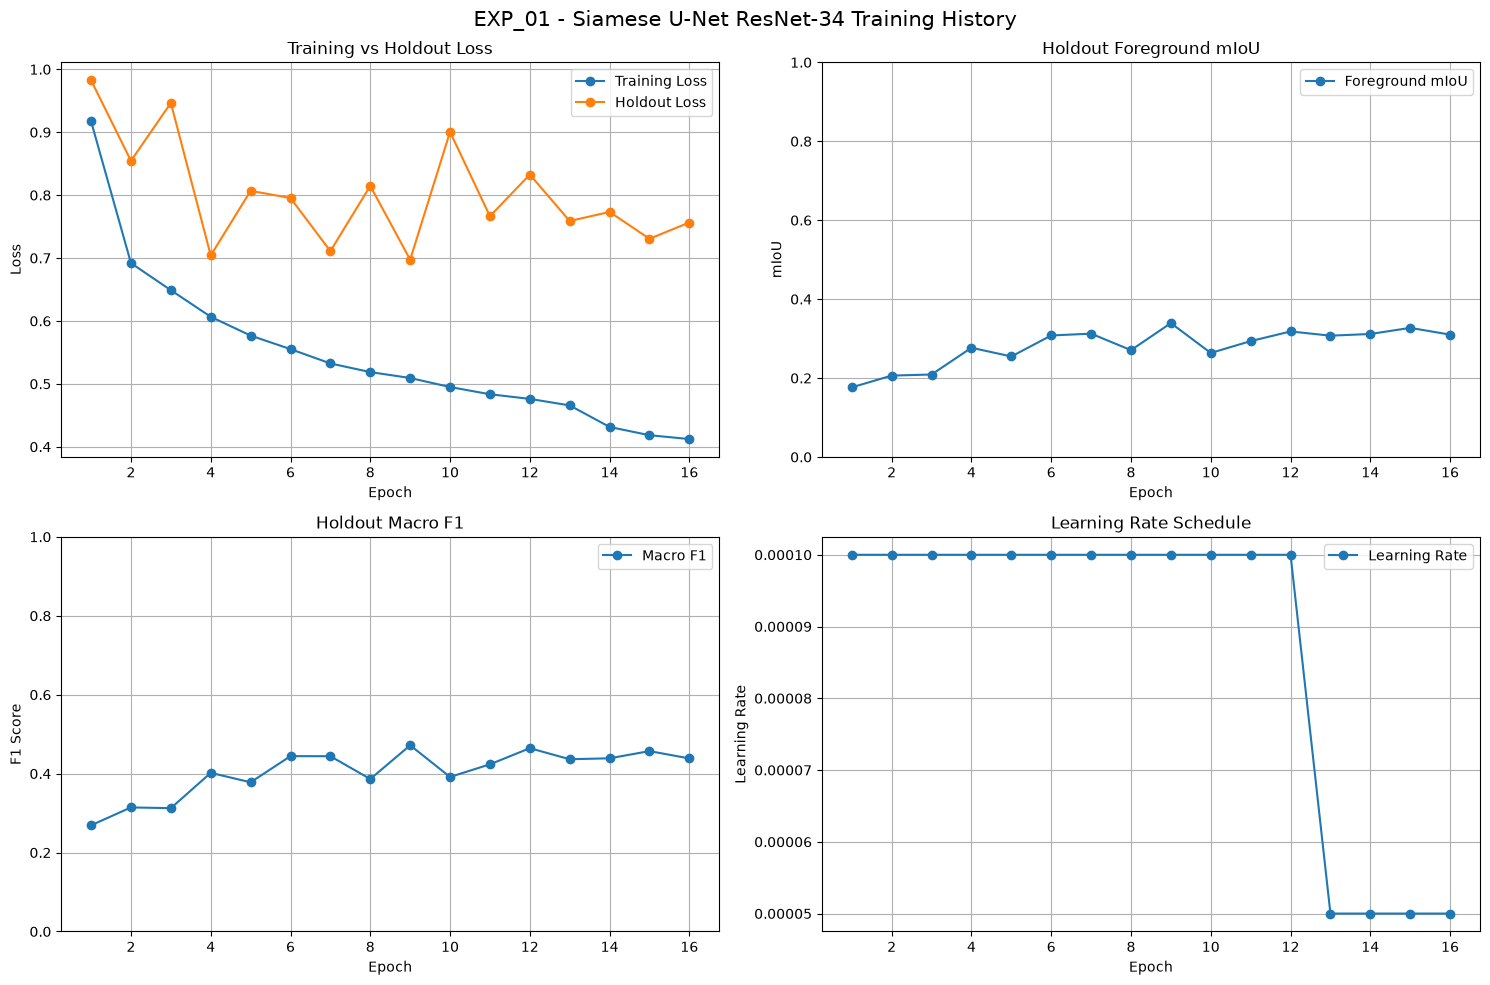

TRAINING HISTORY SUMMARY
Completed epochs: 16
Best epoch: 9
Best foreground mIoU: 0.33929
Best macro F1: 0.47181
Latest training loss: 0.41225
Latest holdout loss: 0.7565

Training history visualization completed.


In [32]:

# ============================================================
# 34. TRAINING HISTORY VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# VALIDATE TRAINING HISTORY
# ------------------------------------------------------------

epochs = history["epoch"]

assert len(epochs) > 0, "Training history is empty."

assert len(history["train_loss"]) == len(epochs)
assert len(history["hold_loss"]) == len(epochs)
assert len(history["hold_miou"]) == len(epochs)
assert len(history["hold_macro_f1"]) == len(epochs)
assert len(history["learning_rate"]) == len(epochs)

# ------------------------------------------------------------
# CREATE FIGURE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 10)
)

# ------------------------------------------------------------
# 1. TRAINING VS HOLDOUT LOSS
# ------------------------------------------------------------

axes[0, 0].plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

axes[0, 0].plot(
    epochs,
    history["hold_loss"],
    marker="o",
    label="Holdout Loss"
)

axes[0, 0].set_title("Training vs Holdout Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()
axes[0, 0].grid(True)

# ------------------------------------------------------------
# 2. FOREGROUND MIOU
# ------------------------------------------------------------

axes[0, 1].plot(
    epochs,
    history["hold_miou"],
    marker="o",
    label="Foreground mIoU"
)

axes[0, 1].set_title("Holdout Foreground mIoU")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("mIoU")
axes[0, 1].set_ylim(0, 1)
axes[0, 1].legend()
axes[0, 1].grid(True)

# ------------------------------------------------------------
# 3. MACRO F1
# ------------------------------------------------------------

axes[1, 0].plot(
    epochs,
    history["hold_macro_f1"],
    marker="o",
    label="Macro F1"
)

axes[1, 0].set_title("Holdout Macro F1")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("F1 Score")
axes[1, 0].set_ylim(0, 1)
axes[1, 0].legend()
axes[1, 0].grid(True)

# ------------------------------------------------------------
# 4. LEARNING RATE
# ------------------------------------------------------------

axes[1, 1].plot(
    epochs,
    history["learning_rate"],
    marker="o",
    label="Learning Rate"
)

axes[1, 1].set_title("Learning Rate Schedule")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Learning Rate")
axes[1, 1].legend()
axes[1, 1].grid(True)

# ------------------------------------------------------------
# FINAL LAYOUT
# ------------------------------------------------------------

fig.suptitle(
    "EXP_01 - Siamese U-Net ResNet-34 Training History",
    fontsize=15
)

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# EXPERIMENT SUMMARY
# ------------------------------------------------------------

best_epoch_index = int(
    np.argmax(history["hold_miou"])
)

print("=" * 65)
print("TRAINING HISTORY SUMMARY")
print("=" * 65)

print("Completed epochs:", len(epochs))

print(
    "Best epoch:",
    history["epoch"][best_epoch_index]
)

print(
    "Best foreground mIoU:",
    round(history["hold_miou"][best_epoch_index], 5)
)

print(
    "Best macro F1:",
    round(max(history["hold_macro_f1"]), 5)
)

print(
    "Latest training loss:",
    round(history["train_loss"][-1], 5)
)

print(
    "Latest holdout loss:",
    round(history["hold_loss"][-1], 5)
)

print("\nTraining history visualization completed.")


In [33]:

# ============================================================
# 39. RESTORE BEST SIAMESE U-NET CHECKPOINT
# ============================================================

print("=" * 65)
print("RESTORING BEST MODEL CHECKPOINT")
print("=" * 65)

# Load checkpoint onto CPU first
best_checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location="cpu",
    weights_only=False
)

# Verify experiment identity
assert (
    best_checkpoint["experiment_name"]
    == EXPERIMENT_NAME
), "Checkpoint experiment mismatch."

# Restore best model weights
model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

# Move model to evaluation device
model = model.to(DEVICE)

# Switch to evaluation mode
model.eval()

# Retrieve checkpoint information
BEST_EPOCH = best_checkpoint["epoch"]

BEST_VALIDATION_MIOU = best_checkpoint["best_hold_miou"]

print("Experiment:", best_checkpoint["experiment_name"])
print("Architecture: Siamese U-Net")
print("Encoder: ResNet-34")
print("Best checkpoint epoch:", BEST_EPOCH)

print(
    "Best validation foreground mIoU:",
    round(BEST_VALIDATION_MIOU, 5)
)

print("Device:", DEVICE)
print("Model mode:", "Evaluation")

assert BEST_EPOCH == 9

print("\nBest checkpoint restored successfully.")


RESTORING BEST MODEL CHECKPOINT
Experiment: EXP_01_SIAMESE_UNET_RESNET34
Architecture: Siamese U-Net
Encoder: ResNet-34
Best checkpoint epoch: 9
Best validation foreground mIoU: 0.33929
Device: cuda
Model mode: Evaluation

Best checkpoint restored successfully.


In [34]:

# ============================================================
# 40. FINAL TEST SET EVALUATION
# ============================================================

print("=" * 65)
print("FINAL TEST SET EVALUATION")
print("=" * 65)

# Confirm best checkpoint is loaded
assert BEST_EPOCH == 9

model.eval()

# Evaluate the untouched test dataset
test_results = validate_one_epoch(
    model,
    test_loader,
    criterion
)

print("\n" + "=" * 65)
print("FINAL TEST RESULTS")
print("=" * 65)

print("Selected checkpoint epoch:", BEST_EPOCH)

print("Test loss:", round(test_results["loss"], 5))

print(
    "Test foreground mIoU:",
    round(test_results["miou"], 5)
)

print(
    "Test macro F1:",
    round(test_results["macro_f1"], 5)
)

print("\nTest-set evaluation completed.")


FINAL TEST SET EVALUATION


Validation:   0%|          | 0/933 [00:00<?, ?it/s]


FINAL TEST RESULTS
Selected checkpoint epoch: 9
Test loss: 0.64941
Test foreground mIoU: 0.33559
Test macro F1: 0.46936

Test-set evaluation completed.


In [35]:

# ============================================================
# 41. FINAL TEST SET CLASS-WISE METRICS
# ============================================================

test_class_metrics_df = pd.DataFrame({

    "Class": [
        CLASS_MAPPING[i]
        for i in range(NUM_CLASSES)
    ],

    "IoU": test_results["class_iou"],

    "F1": test_results["class_f1"],

    "Precision": test_results["class_precision"],

    "Recall": test_results["class_recall"]

})

print("=" * 75)
print("FINAL TEST SET CLASS-WISE PERFORMANCE")
print("=" * 75)

display(test_class_metrics_df.round(4))

print("\nOVERALL TEST METRICS")

print(
    "Foreground mIoU:",
    round(test_results["miou"], 5)
)

print(
    "Macro F1:",
    round(test_results["macro_f1"], 5)
)

print("\nTest class-wise evaluation completed.")


FINAL TEST SET CLASS-WISE PERFORMANCE


,Class,IoU,F1,Precision,Recall
0,background,0.9763,0.9880,0.9870,0.9890
1,no-damage,0.5851,0.7383,0.7383,0.7383
2,minor-damage,0.0531,0.1008,0.2485,0.0632
3,major-damage,0.3074,0.4702,0.4256,0.5253
4,destroyed,0.3968,0.5681,0.5430,0.5957



OVERALL TEST METRICS
Foreground mIoU: 0.33559
Macro F1: 0.46936

Test class-wise evaluation completed.


TEST SET CONFUSION MATRIX
Rows = Actual classes | Columns = Predicted classes
[[910344723   8156083    251366   1154597    519727]
 [  8799869  32394889    347714   1700840    634080]
 [  1251158   2153287    300189    855401    188562]
 [  1020984   1109339    298267   2905319    197377]
 [   954531     66574     10367    209800   1829220]]


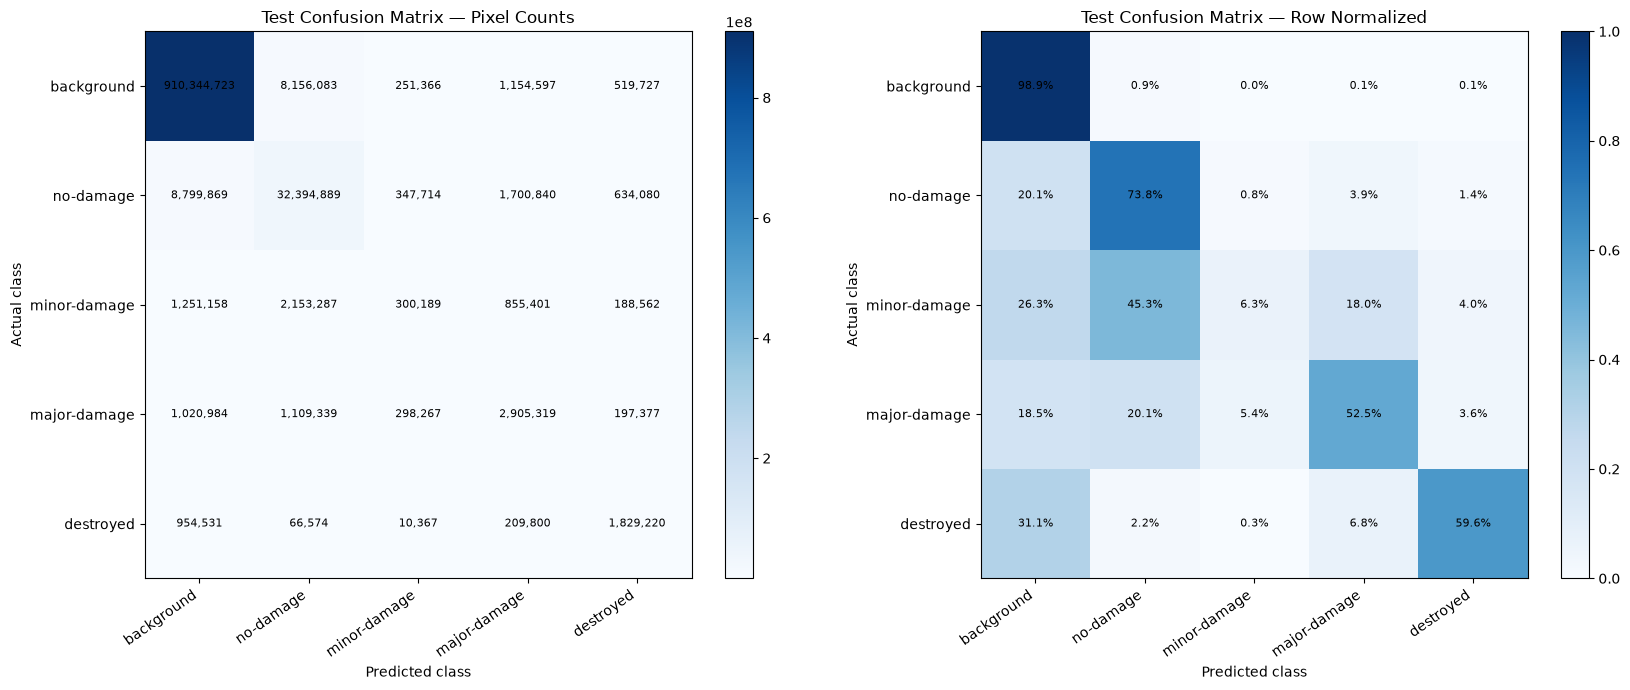


Total valid test pixels: 977654263
Confusion matrix computation completed.


In [42]:
# CELL 42 — Build test-set confusion matrix

import torch
import numpy as np
import matplotlib.pyplot as plt

model.eval()

confusion = torch.zeros(
    (NUM_CLASSES, NUM_CLASSES),
    dtype=torch.int64,
    device=DEVICE
)

with torch.no_grad():
    for batch in test_loader:

        pre_image = batch["pre_image"].to(
            DEVICE, non_blocking=True
        )
        post_image = batch["post_image"].to(
            DEVICE, non_blocking=True
        )
        masks = batch["mask"].to(
            DEVICE, non_blocking=True
        )



        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            logits = model(pre_image, post_image)

        predictions = torch.argmax(logits, dim=1)

        valid = masks != IGNORE_INDEX

        targets_valid = masks[valid].long()
        predictions_valid = predictions[valid].long()

        encoded = (
            targets_valid * NUM_CLASSES + predictions_valid
        )

        confusion += torch.bincount(
            encoded,
            minlength=NUM_CLASSES ** 2
        ).reshape(NUM_CLASSES, NUM_CLASSES)

confusion_np = confusion.cpu().numpy()

print("=" * 75)
print("TEST SET CONFUSION MATRIX")
print("=" * 75)
print("Rows = Actual classes | Columns = Predicted classes")
print(confusion_np)

# Row-normalized confusion matrix
row_totals = confusion_np.sum(axis=1, keepdims=True)

confusion_normalized = np.divide(
    confusion_np,
    row_totals,
    out=np.zeros_like(confusion_np, dtype=float),
    where=row_totals != 0
)

class_names = [
    CLASS_MAPPING[i] for i in range(NUM_CLASSES)
]

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

# Raw pixel counts
im1 = axes[0].imshow(confusion_np, cmap="Blues")
axes[0].set_title("Test Confusion Matrix — Pixel Counts")
axes[0].set_xlabel("Predicted class")
axes[0].set_ylabel("Actual class")
axes[0].set_xticks(range(NUM_CLASSES))
axes[0].set_yticks(range(NUM_CLASSES))
axes[0].set_xticklabels(class_names, rotation=35, ha="right")
axes[0].set_yticklabels(class_names)
fig.colorbar(im1, ax=axes[0], fraction=0.046)

# Normalized percentages
im2 = axes[1].imshow(
    confusion_normalized,
    cmap="Blues",
    vmin=0,
    vmax=1
)
axes[1].set_title("Test Confusion Matrix — Row Normalized")
axes[1].set_xlabel("Predicted class")
axes[1].set_ylabel("Actual class")
axes[1].set_xticks(range(NUM_CLASSES))
axes[1].set_yticks(range(NUM_CLASSES))
axes[1].set_xticklabels(class_names, rotation=35, ha="right")
axes[1].set_yticklabels(class_names)
fig.colorbar(im2, ax=axes[1], fraction=0.046)

for ax in axes:
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            value = (
                f"{confusion_np[i, j]:,}"
                if ax is axes[0]
                else f"{confusion_normalized[i, j]:.1%}"
            )
            ax.text(
                j, i, value,
                ha="center",
                va="center",
                fontsize=8,
                color="black"
            )

plt.tight_layout()
plt.show()

print("\nTotal valid test pixels:", int(confusion_np.sum()))
print("Confusion matrix computation completed.")

In [43]:
# CELL 43 — Verify Experiment 02 initialization resources

from pathlib import Path
import torch
import numpy as np

# Original Experiment 01 best checkpoint
EXP01_BEST_PATH = (
    CHECKPOINT_ROOT / "siamese_unet_resnet34_best.pth"
)

assert EXP01_BEST_PATH.exists(), (
    f"Experiment 01 best checkpoint not found: {EXP01_BEST_PATH}"
)

# Load checkpoint metadata on CPU
exp01_checkpoint = torch.load(
    EXP01_BEST_PATH,
    map_location="cpu",
    weights_only=False
)

print("=" * 70)
print("EXPERIMENT 02 — INITIALIZATION VERIFICATION")
print("=" * 70)

print("Checkpoint:", EXP01_BEST_PATH)
print("Checkpoint experiment:", exp01_checkpoint["experiment_name"])
print("Checkpoint epoch:", exp01_checkpoint["epoch"])
print(
    "Best holdout mIoU:",
    round(exp01_checkpoint["best_hold_miou"], 5)
)

print("\nClass weights:")

for class_id, weight in enumerate(CLASS_WEIGHTS):
    print(
        f"{CLASS_MAPPING[class_id]:15s}: {float(weight):.4f}"
    )

print("\nCheckpoint and loss-weight validation:")

assert exp01_checkpoint["epoch"] == 9
assert exp01_checkpoint["experiment_name"] == (
    "EXP_01_SIAMESE_UNET_RESNET34"
)
assert len(CLASS_WEIGHTS) == NUM_CLASSES
assert np.all(np.isfinite(CLASS_WEIGHTS))
assert np.all(np.asarray(CLASS_WEIGHTS) > 0)

print("Epoch 9 checkpoint verified.")
print("Training-derived class weights verified.")
print("\nReady to initialize Experiment 02.")

EXPERIMENT 02 — INITIALIZATION VERIFICATION
Checkpoint: d:\ML_Project\checkpoints\siamese_unet_resnet34_best.pth
Checkpoint experiment: EXP_01_SIAMESE_UNET_RESNET34
Checkpoint epoch: 9
Best holdout mIoU: 0.33929

Class weights:
background     : 0.8204
no-damage      : 3.8060
minor-damage   : 3.9788
major-damage   : 3.9788
destroyed      : 3.9788

Checkpoint and loss-weight validation:
Epoch 9 checkpoint verified.
Training-derived class weights verified.

Ready to initialize Experiment 02.


In [44]:
# CELL 44 — Initialize Experiment 02

from pathlib import Path
import torch

# --------------------------------------------------
# 1. Experiment identity and checkpoint paths
# --------------------------------------------------

EXP02_NAME = "EXP_02_SIAMESE_UNET_FOCAL"

EXP02_BEST_PATH = (
    CHECKPOINT_ROOT / "siamese_unet_resnet34_focal_best.pth"
)

EXP02_LATEST_PATH = (
    CHECKPOINT_ROOT / "siamese_unet_resnet34_focal_latest.pth"
)

assert not EXP02_BEST_PATH.exists(), (
    "Experiment 02 best checkpoint already exists. "
    "Do not overwrite an existing experiment."
)

assert not EXP02_LATEST_PATH.exists(), (
    "Experiment 02 latest checkpoint already exists. "
    "Do not overwrite an existing experiment."
)

# --------------------------------------------------
# 2. Load Experiment 01 best model weights
# --------------------------------------------------

model.load_state_dict(
    exp01_checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model.eval()

# --------------------------------------------------
# 3. Fresh optimizer
# --------------------------------------------------

EXP02_LEARNING_RATE = 2e-5
EXP02_WEIGHT_DECAY = 1e-4

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=EXP02_LEARNING_RATE,
    weight_decay=EXP02_WEIGHT_DECAY
)

# --------------------------------------------------
# 4. Fresh learning-rate scheduler
# --------------------------------------------------

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
    threshold=0.001,
    min_lr=1e-7
)

# --------------------------------------------------
# 5. Fresh AMP scaler
# --------------------------------------------------

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(DEVICE.type == "cuda")
)

# --------------------------------------------------
# 6. Experiment configuration
# --------------------------------------------------

EXP02_MAX_EPOCHS = 20
EXP02_EARLY_STOPPING_PATIENCE = 6
EXP02_GRAD_ACCUMULATION = 2
EXP02_GRAD_CLIP = 1.0

best_hold_miou = -1.0
start_epoch = 0
epochs_without_improvement = 0

history = []

# --------------------------------------------------
# 7. Verification
# --------------------------------------------------

print("=" * 70)
print("EXPERIMENT 02 INITIALIZED")
print("=" * 70)

print("Experiment:", EXP02_NAME)
print("Architecture: Siamese U-Net + ResNet-34")
print("Initialization: Experiment 01, Epoch 9")
print("Initial holdout mIoU:", exp01_checkpoint["best_hold_miou"])

print("\nOptimizer: AdamW")
print("Learning rate:", EXP02_LEARNING_RATE)
print("Weight decay:", EXP02_WEIGHT_DECAY)

print("\nMaximum epochs:", EXP02_MAX_EPOCHS)
print("Gradient accumulation:", EXP02_GRAD_ACCUMULATION)
print("Effective batch size:", BATCH_SIZE * EXP02_GRAD_ACCUMULATION)

print("\nBest checkpoint:", EXP02_BEST_PATH)
print("Latest checkpoint:", EXP02_LATEST_PATH)

print("\nExperiment 02 initialization successful.")

EXPERIMENT 02 INITIALIZED
Experiment: EXP_02_SIAMESE_UNET_FOCAL
Architecture: Siamese U-Net + ResNet-34
Initialization: Experiment 01, Epoch 9
Initial holdout mIoU: 0.3392927050590515

Optimizer: AdamW
Learning rate: 2e-05
Weight decay: 0.0001

Maximum epochs: 20
Gradient accumulation: 2
Effective batch size: 2

Best checkpoint: d:\ML_Project\checkpoints\siamese_unet_resnet34_focal_best.pth
Latest checkpoint: d:\ML_Project\checkpoints\siamese_unet_resnet34_focal_latest.pth

Experiment 02 initialization successful.


In [45]:
# CELL 45 — Class-weighted Focal Loss + Foreground Dice

class FocalDiceLoss(nn.Module):

    def __init__(
        self,
        class_weights,
        ignore_index=255,
        gamma=2.0,
        dice_weight=1.0
    ):
        super().__init__()

        self.register_buffer(
            "class_weights",
            torch.as_tensor(
                class_weights,
                dtype=torch.float32
            )
        )

        self.ignore_index = ignore_index
        self.gamma = gamma
        self.dice_weight = dice_weight

    def forward(self, logits, targets):

        logits = logits.float()

        # ------------------------------------------------
        # VALID PIXELS
        # ------------------------------------------------

        valid_mask = targets != self.ignore_index

        if not valid_mask.any():
            raise ValueError("Batch contains only ignored pixels.")

        # ------------------------------------------------
        # CLASS-WEIGHTED FOCAL LOSS
        # ------------------------------------------------

        log_probabilities = F.log_softmax(logits, dim=1)

        safe_targets = targets.masked_fill(
            ~valid_mask,
            0
        )

        log_pt = log_probabilities.gather(
            dim=1,
            index=safe_targets.unsqueeze(1)
        ).squeeze(1)

        pt = log_pt.exp()

        pixel_weights = self.class_weights[safe_targets]

        focal_factor = (1.0 - pt).pow(self.gamma)

        focal_pixels = (
            -pixel_weights * focal_factor * log_pt
        )

        focal_loss = (
            focal_pixels[valid_mask].sum()
            / pixel_weights[valid_mask].sum().clamp_min(1e-8)
        )

        # ------------------------------------------------
        # FOREGROUND DICE LOSS
        # ------------------------------------------------

        probabilities = torch.softmax(logits, dim=1)

        one_hot_targets = F.one_hot(
            safe_targets,
            num_classes=NUM_CLASSES
        ).permute(0, 3, 1, 2).float()

        valid_mask_4d = valid_mask.unsqueeze(1)

        probabilities = probabilities * valid_mask_4d
        one_hot_targets = one_hot_targets * valid_mask_4d

        # Exclude background
        probabilities = probabilities[:, 1:]
        one_hot_targets = one_hot_targets[:, 1:]

        intersection = (
            probabilities * one_hot_targets
        ).sum(dim=(0, 2, 3))

        denominator = (
            probabilities.sum(dim=(0, 2, 3))
            + one_hot_targets.sum(dim=(0, 2, 3))
        )

        dice_scores = (
            2.0 * intersection + 1e-6
        ) / (
            denominator + 1e-6
        )

        present_classes = (
            one_hot_targets.sum(dim=(0, 2, 3)) > 0
        )

        if present_classes.any():
            dice_loss = (
                1.0 - dice_scores[present_classes].mean()
            )
        else:
            dice_loss = logits.sum() * 0.0

        # ------------------------------------------------
        # TOTAL LOSS
        # ------------------------------------------------

        total_loss = (
            focal_loss
            + self.dice_weight * dice_loss
        )

        return {
            "total_loss": total_loss,
            "focal_loss": focal_loss,
            "dice_loss": dice_loss
        }


# Initialize Experiment 02 criterion
criterion = FocalDiceLoss(
    class_weights=CLASS_WEIGHTS,
    ignore_index=IGNORE_INDEX,
    gamma=2.0,
    dice_weight=1.0
).to(DEVICE)

print("=" * 70)
print("EXPERIMENT 02 LOSS INITIALIZED")
print("=" * 70)

print("Loss: Class-weighted Focal + Foreground Dice")
print("Focal gamma:", criterion.gamma)
print("Dice weight:", criterion.dice_weight)
print("Ignore index:", criterion.ignore_index)
print("Background excluded from Dice.")
print("Class weights:", criterion.class_weights.detach().cpu().tolist())

EXPERIMENT 02 LOSS INITIALIZED
Loss: Class-weighted Focal + Foreground Dice
Focal gamma: 2.0
Dice weight: 1.0
Ignore index: 255
Background excluded from Dice.
Class weights: [0.8204315304756165, 3.8060097694396973, 3.978783369064331, 3.978783369064331, 3.978783369064331]


In [46]:
# CELL 46 — Validate Experiment 02 loss and gradients

model.train()
optimizer.zero_grad(set_to_none=True)

# Get one training batch
batch = next(iter(train_loader))

pre_image = batch["pre_image"].to(DEVICE)
post_image = batch["post_image"].to(DEVICE)
masks = batch["mask"].to(DEVICE)

print("Input shapes:")
print("Pre-image:", pre_image.shape)
print("Post-image:", post_image.shape)
print("Mask:", masks.shape)

# Forward pass with AMP
with torch.autocast(
    device_type="cuda",
    dtype=torch.float16,
    enabled=(DEVICE.type == "cuda")
):
    logits = model(pre_image, post_image)

    loss_components = criterion(logits, masks)

    total_loss = loss_components["total_loss"]

# Backward pass
total_loss.backward()

# Check gradients
gradient_values = [
    parameter.grad
    for parameter in model.parameters()
    if parameter.grad is not None
]

all_gradients_finite = all(
    torch.isfinite(gradient).all().item()
    for gradient in gradient_values
)

gradient_norm = torch.nn.utils.clip_grad_norm_(
    model.parameters(),
    max_norm=EXP02_GRAD_CLIP
)

# Clear gradients without changing model parameters
optimizer.zero_grad(set_to_none=True)

print("\n" + "=" * 70)
print("EXPERIMENT 02 LOSS VALIDATION")
print("=" * 70)

print("Logits shape:", logits.shape)
print("Total loss:", total_loss.item())
print("Focal loss:", loss_components["focal_loss"].item())
print("Dice loss:", loss_components["dice_loss"].item())

print("Gradient norm before clipping:", float(gradient_norm))
print("Gradient tensors:", len(gradient_values))
print("All gradients finite:", all_gradients_finite)

assert logits.shape == (
    pre_image.shape[0],
    NUM_CLASSES,
    pre_image.shape[2],
    pre_image.shape[3]
)

assert torch.isfinite(total_loss).item()
assert all_gradients_finite
assert len(gradient_values) > 0

print("\nForward pass: PASSED")
print("Backward pass: PASSED")
print("Gradient validation: PASSED")
print("Optimizer step: NOT PERFORMED")
print("\nExperiment 02 loss validation completed.")

model.eval()

Input shapes:
Pre-image: torch.Size([1, 3, 1024, 1024])
Post-image: torch.Size([1, 3, 1024, 1024])
Mask: torch.Size([1, 1024, 1024])

EXPERIMENT 02 LOSS VALIDATION
Logits shape: torch.Size([1, 5, 1024, 1024])
Total loss: 1.1588371992111206
Focal loss: 0.4352899193763733
Dice loss: 0.7235472798347473
Gradient norm before clipping: 3.8033268451690674
Gradient tensors: 151
All gradients finite: True

Forward pass: PASSED
Backward pass: PASSED
Gradient validation: PASSED
Optimizer step: NOT PERFORMED

Experiment 02 loss validation completed.


SiameseUNet(
  (stem): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (

In [47]:
# CELL 47 — Inspect existing training function signatures

import inspect

print("train_one_epoch:")
print(inspect.signature(train_one_epoch))

print("\nvalidate_one_epoch:")
print(inspect.signature(validate_one_epoch))

print("\nExisting training function source:")
print(inspect.getsource(train_one_epoch))

print("\nExisting validation function source:")
print(inspect.getsource(validate_one_epoch))

train_one_epoch:
(model, loader, criterion, optimizer, scaler)

validate_one_epoch:
(model, loader, criterion)

Existing training function source:
def train_one_epoch(model, loader, criterion, optimizer, scaler):

    model.train()

    total_loss = 0.0
    total_ce = 0.0
    total_dice = 0.0

    optimizer.zero_grad(set_to_none=True)

    num_batches = len(loader)

    progress = tqdm(
        enumerate(loader),
        total=num_batches,
        desc="Training"
    )

    for step, batch in progress:

        pre_images = batch["pre_image"].to(
            DEVICE, non_blocking=True
        )

        post_images = batch["post_image"].to(
            DEVICE, non_blocking=True
        )

        targets = batch["mask"].to(
            DEVICE, non_blocking=True
        )

        # Correct accumulation for the final incomplete group.
        group_start = (
            step // GRADIENT_ACCUMULATION_STEPS
        ) * GRADIENT_ACCUMULATION_STEPS

        group_size = min(
            GRAD

In [48]:
# CELL 48 — Experiment 02 training function

def train_one_epoch_exp02(model, loader, criterion, optimizer, scaler):

    model.train()

    total_loss = 0.0
    total_focal = 0.0
    total_dice = 0.0

    optimizer.zero_grad(set_to_none=True)

    num_batches = len(loader)

    progress = tqdm(
        enumerate(loader),
        total=num_batches,
        desc="EXP02 Training"
    )

    for step, batch in progress:

        pre_images = batch["pre_image"].to(
            DEVICE, non_blocking=True
        )

        post_images = batch["post_image"].to(
            DEVICE, non_blocking=True
        )

        targets = batch["mask"].to(
            DEVICE, non_blocking=True
        )

        # Handle final incomplete accumulation group
        group_start = (
            step // EXP02_GRAD_ACCUMULATION
        ) * EXP02_GRAD_ACCUMULATION

        group_size = min(
            EXP02_GRAD_ACCUMULATION,
            num_batches - group_start
        )

        with torch.amp.autocast(
            DEVICE.type,
            enabled=USE_AMP,
            dtype=torch.float16
        ):

            logits = model(
                pre_images,
                post_images
            )

            loss_dict = criterion(
                logits,
                targets
            )

            loss = loss_dict["total_loss"]

        scaler.scale(
            loss / group_size
        ).backward()

        # Optimizer update
        if (
            (step + 1) % EXP02_GRAD_ACCUMULATION == 0
            or step + 1 == num_batches
        ):

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                EXP02_GRAD_CLIP
            )

            scaler.step(optimizer)
            scaler.update()

            optimizer.zero_grad(set_to_none=True)

        total_loss += loss.item()
        total_focal += loss_dict["focal_loss"].item()
        total_dice += loss_dict["dice_loss"].item()

        progress.set_postfix(
            loss=f"{loss.item():.4f}",
            focal=f"{loss_dict['focal_loss'].item():.4f}",
            dice=f"{loss_dict['dice_loss'].item():.4f}"
        )

        del pre_images, post_images, targets
        del logits, loss_dict, loss

    return {
        "loss": total_loss / num_batches,
        "focal_loss": total_focal / num_batches,
        "dice_loss": total_dice / num_batches
    }


print("Experiment 02 training function defined.")

Experiment 02 training function defined.


In [49]:
# CELL 49 — Experiment 02 validation function

@torch.no_grad()
def validate_one_epoch_exp02(model, loader, criterion):

    model.eval()

    total_loss = 0.0
    total_focal = 0.0
    total_dice = 0.0

    confusion = torch.zeros(
        NUM_CLASSES,
        NUM_CLASSES,
        dtype=torch.int64,
        device=DEVICE
    )

    progress = tqdm(
        loader,
        desc="EXP02 Validation"
    )

    for batch in progress:

        pre_images = batch["pre_image"].to(
            DEVICE, non_blocking=True
        )

        post_images = batch["post_image"].to(
            DEVICE, non_blocking=True
        )

        targets = batch["mask"].to(
            DEVICE, non_blocking=True
        )

        with torch.amp.autocast(
            DEVICE.type,
            enabled=USE_AMP,
            dtype=torch.float16
        ):

            logits = model(
                pre_images,
                post_images
            )

            loss_dict = criterion(
                logits,
                targets
            )

        predictions = logits.argmax(dim=1)

        total_loss += loss_dict["total_loss"].item()
        total_focal += loss_dict["focal_loss"].item()
        total_dice += loss_dict["dice_loss"].item()

        confusion = update_confusion_matrix(
            confusion,
            predictions,
            targets
        )

        del pre_images, post_images, targets
        del logits, predictions, loss_dict

    metrics = calculate_metrics(confusion)

    metrics["loss"] = total_loss / len(loader)
    metrics["focal_loss"] = total_focal / len(loader)
    metrics["dice_loss"] = total_dice / len(loader)

    return metrics


print("Experiment 02 validation function defined.")

Experiment 02 validation function defined.


In [50]:
# CELL 50 — Experiment 02 holdout validation smoke test

model.eval()

batch = next(iter(hold_loader))

pre_image = batch["pre_image"].to(DEVICE)
post_image = batch["post_image"].to(DEVICE)
masks = batch["mask"].to(DEVICE)

with torch.no_grad():

    with torch.amp.autocast(
        DEVICE.type,
        enabled=USE_AMP,
        dtype=torch.float16
    ):

        logits = model(pre_image, post_image)
        loss_dict = criterion(logits, masks)

    predictions = logits.argmax(dim=1)

    temporary_confusion = torch.zeros(
        NUM_CLASSES,
        NUM_CLASSES,
        dtype=torch.int64,
        device=DEVICE
    )

    temporary_confusion = update_confusion_matrix(
        temporary_confusion,
        predictions,
        masks
    )

    temporary_metrics = calculate_metrics(
        temporary_confusion
    )

print("=" * 70)
print("EXPERIMENT 02 HOLDOUT SMOKE TEST")
print("=" * 70)

print("Logits shape:", logits.shape)
print("Total loss:", round(loss_dict["total_loss"].item(), 5))
print("Focal loss:", round(loss_dict["focal_loss"].item(), 5))
print("Dice loss:", round(loss_dict["dice_loss"].item(), 5))
print("Foreground mIoU:", round(temporary_metrics["miou"], 5))
print("Macro F1:", round(temporary_metrics["macro_f1"], 5))

assert torch.isfinite(loss_dict["total_loss"]).item()
assert logits.shape[1] == NUM_CLASSES

print("\nHoldout smoke test PASSED.")

del batch, pre_image, post_image, masks
del logits, predictions, loss_dict, temporary_confusion
del temporary_metrics

model.eval()

EXPERIMENT 02 HOLDOUT SMOKE TEST
Logits shape: torch.Size([1, 5, 1024, 1024])
Total loss: 0.85503
Focal loss: 0.2072
Dice loss: 0.64783
Foreground mIoU: 0.26383
Macro F1: 0.3975

Holdout smoke test PASSED.


SiameseUNet(
  (stem): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (

In [51]:
# CELL 51 — Experiment 02 checkpoint management

import random
import numpy as np
import torch


def save_exp02_checkpoint(path, epoch, is_best=False):

    checkpoint = {
        "experiment_name": EXP02_NAME,
        "epoch": epoch,
        "best_hold_miou": best_hold_miou,

        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),

        "history": history,

        "class_mapping": CLASS_MAPPING,
        "ignore_index": IGNORE_INDEX,

        "config": {
            "learning_rate": EXP02_LEARNING_RATE,
            "weight_decay": EXP02_WEIGHT_DECAY,
            "max_epochs": EXP02_MAX_EPOCHS,
            "gradient_accumulation": EXP02_GRAD_ACCUMULATION,
            "gradient_clip": EXP02_GRAD_CLIP,
            "focal_gamma": criterion.gamma,
            "dice_weight": criterion.dice_weight,
        },

        "random_state": random.getstate(),
        "numpy_random_state": np.random.get_state(),
        "torch_random_state": torch.get_rng_state(),

        "cuda_random_state": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else None
        )
    }

    torch.save(checkpoint, path)

    if is_best:
        print(f"New best checkpoint saved: {path}")


print("Experiment 02 checkpoint function defined.")
print("Best path:", EXP02_BEST_PATH)
print("Latest path:", EXP02_LATEST_PATH)

Experiment 02 checkpoint function defined.
Best path: d:\ML_Project\checkpoints\siamese_unet_resnet34_focal_best.pth
Latest path: d:\ML_Project\checkpoints\siamese_unet_resnet34_focal_latest.pth


In [52]:
# CELL 52 — Experiment 02 training loop

import time
import copy

print("=" * 75)
print("STARTING EXPERIMENT 02")
print("=" * 75)

print("Experiment:", EXP02_NAME)
print("Starting checkpoint: Experiment 01, Epoch 9")
print("Training samples:", len(train_loader.dataset))
print("Holdout samples:", len(hold_loader.dataset))
print("Maximum epochs:", EXP02_MAX_EPOCHS)
print("Initial learning rate:", EXP02_LEARNING_RATE)

for epoch in range(start_epoch, EXP02_MAX_EPOCHS):

    epoch_start = time.time()

    print("\n" + "=" * 75)
    print(f"EXPERIMENT 02 — EPOCH {epoch + 1}/{EXP02_MAX_EPOCHS}")
    print("=" * 75)

    # --------------------------------------------
    # TRAINING
    # --------------------------------------------

    train_metrics = train_one_epoch_exp02(
        model,
        train_loader,
        criterion,
        optimizer,
        scaler
    )

    # --------------------------------------------
    # HOLDOUT VALIDATION
    # --------------------------------------------

    hold_metrics = validate_one_epoch_exp02(
        model,
        hold_loader,
        criterion
    )

    current_lr = optimizer.param_groups[0]["lr"]

    # --------------------------------------------
    # SCHEDULER
    # --------------------------------------------

    scheduler.step(hold_metrics["miou"])

    # --------------------------------------------
    # IMPROVEMENT CHECK
    # --------------------------------------------

    improved = (
        hold_metrics["miou"] > best_hold_miou
    )

    if improved:

        best_hold_miou = hold_metrics["miou"]
        epochs_without_improvement = 0

        # Save best checkpoint
        save_exp02_checkpoint(
            EXP02_BEST_PATH,
            epoch=epoch + 1,
            is_best=True
        )

    else:

        epochs_without_improvement += 1

    # --------------------------------------------
    # HISTORY
    # --------------------------------------------

    epoch_time = time.time() - epoch_start

    epoch_record = {

        "epoch": epoch + 1,

        "train_loss": train_metrics["loss"],
        "train_focal_loss": train_metrics["focal_loss"],
        "train_dice_loss": train_metrics["dice_loss"],

        "hold_loss": hold_metrics["loss"],
        "hold_focal_loss": hold_metrics["focal_loss"],
        "hold_dice_loss": hold_metrics["dice_loss"],

        "hold_miou": hold_metrics["miou"],
        "hold_macro_f1": hold_metrics["macro_f1"],

        "learning_rate": current_lr,
        "epoch_time": epoch_time

    }

    history.append(epoch_record)

    # --------------------------------------------
    # SAVE LATEST CHECKPOINT
    # --------------------------------------------

    save_exp02_checkpoint(
        EXP02_LATEST_PATH,
        epoch=epoch + 1
    )

    # --------------------------------------------
    # EPOCH SUMMARY
    # --------------------------------------------

    print("\nEPOCH SUMMARY")

    print(f"Train loss:       {train_metrics['loss']:.5f}")
    print(f"Train focal:      {train_metrics['focal_loss']:.5f}")
    print(f"Train Dice:       {train_metrics['dice_loss']:.5f}")

    print(f"Holdout loss:     {hold_metrics['loss']:.5f}")
    print(f"Holdout mIoU:     {hold_metrics['miou']:.5f}")
    print(f"Holdout macro F1: {hold_metrics['macro_f1']:.5f}")

    print(f"Learning rate:    {current_lr:.8f}")
    print(f"Best holdout mIoU:{best_hold_miou:.5f}")

    print(f"Epoch time:       {epoch_time / 60:.2f} minutes")

    print(
        "Epochs without improvement:",
        epochs_without_improvement
    )

    # --------------------------------------------
    # EARLY STOPPING
    # --------------------------------------------

    if epochs_without_improvement >= EXP02_EARLY_STOPPING_PATIENCE:

        print("\nEarly stopping triggered.")
        print("No holdout mIoU improvement for 6 epochs.")
        break

print("\n" + "=" * 75)
print("EXPERIMENT 02 TRAINING FINISHED")
print("=" * 75)

print("Completed epochs:", len(history))
print("Best holdout mIoU:", round(best_hold_miou, 5))
print("Best checkpoint:", EXP02_BEST_PATH)
print("Latest checkpoint:", EXP02_LATEST_PATH)

STARTING EXPERIMENT 02
Experiment: EXP_02_SIAMESE_UNET_FOCAL
Starting checkpoint: Experiment 01, Epoch 9
Training samples: 2799
Holdout samples: 933
Maximum epochs: 20
Initial learning rate: 2e-05

EXPERIMENT 02 — EPOCH 1/20


EXP02 Training:   0%|          | 0/2799 [00:00<?, ?it/s]

EXP02 Validation:   0%|          | 0/933 [00:00<?, ?it/s]

New best checkpoint saved: d:\ML_Project\checkpoints\siamese_unet_resnet34_focal_best.pth

EPOCH SUMMARY
Train loss:       0.41945
Train focal:      0.09074
Train Dice:       0.32870
Holdout loss:     0.64975
Holdout mIoU:     0.34541
Holdout macro F1: 0.48047
Learning rate:    0.00002000
Best holdout mIoU:0.34541
Epoch time:       29.54 minutes
Epochs without improvement: 0

EXPERIMENT 02 — EPOCH 2/20


EXP02 Training:   0%|          | 0/2799 [00:00<?, ?it/s]

EXP02 Validation:   0%|          | 0/933 [00:00<?, ?it/s]

... (12 outputs left out)


EPOCH SUMMARY
Train loss:       0.36689
Train focal:      0.07693
Train Dice:       0.28996
Holdout loss:     0.70837
Holdout mIoU:     0.33367
Holdout macro F1: 0.47129
Learning rate:    0.00001000
Best holdout mIoU:0.34541
Epoch time:       27.37 minutes
Epochs without improvement: 5

EXPERIMENT 02 — EPOCH 7/20


EXP02 Training:   0%|          | 0/2799 [00:00<?, ?it/s]

EXP02 Validation:   0%|          | 0/933 [00:00<?, ?it/s]


EPOCH SUMMARY
Train loss:       0.36282
Train focal:      0.07627
Train Dice:       0.28654
Holdout loss:     0.71833
Holdout mIoU:     0.31549
Holdout macro F1: 0.44211
Learning rate:    0.00001000
Best holdout mIoU:0.34541
Epoch time:       27.34 minutes
Epochs without improvement: 6

Early stopping triggered.
No holdout mIoU improvement for 6 epochs.

EXPERIMENT 02 TRAINING FINISHED
Completed epochs: 7
Best holdout mIoU: 0.34541
Best checkpoint: d:\ML_Project\checkpoints\siamese_unet_resnet34_focal_best.pth
Latest checkpoint: d:\ML_Project\checkpoints\siamese_unet_resnet34_focal_latest.pth


In [53]:
# CELL 53 — Load best Experiment 02 checkpoint

exp02_best_checkpoint = torch.load(
    EXP02_BEST_PATH,
    map_location="cpu",
    weights_only=False
)

assert exp02_best_checkpoint["experiment_name"] == EXP02_NAME

model.load_state_dict(
    exp02_best_checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model.eval()

print("=" * 70)
print("EXPERIMENT 02 BEST CHECKPOINT LOADED")
print("=" * 70)

print("Experiment:", exp02_best_checkpoint["experiment_name"])
print("Best epoch:", exp02_best_checkpoint["epoch"])

print(
    "Best holdout mIoU:",
    round(exp02_best_checkpoint["best_hold_miou"], 5)
)

print("Model device:", DEVICE)
print("Model mode:", "Evaluation" if not model.training else "Training")

print("\nExperiment 02 best checkpoint ready for test evaluation.")

EXPERIMENT 02 BEST CHECKPOINT LOADED
Experiment: EXP_02_SIAMESE_UNET_FOCAL
Best epoch: 1
Best holdout mIoU: 0.34541
Model device: cuda
Model mode: Evaluation

Experiment 02 best checkpoint ready for test evaluation.


In [54]:
# CELL 54 — Experiment 02 test-set evaluation

print("=" * 75)
print("EXPERIMENT 02 — FINAL TEST SET EVALUATION")
print("=" * 75)

model.eval()

exp02_test_results = validate_one_epoch_exp02(
    model,
    test_loader,
    criterion
)

print("\n" + "=" * 75)
print("EXPERIMENT 02 TEST RESULTS")
print("=" * 75)

print("Selected checkpoint epoch:",
      exp02_best_checkpoint["epoch"])

print("Test loss:",
      round(exp02_test_results["loss"], 5))

print("Test foreground mIoU:",
      round(exp02_test_results["miou"], 5))

print("Test macro F1:",
      round(exp02_test_results["macro_f1"], 5))

print("\nExperiment 02 test evaluation completed.")

EXPERIMENT 02 — FINAL TEST SET EVALUATION


EXP02 Validation:   0%|          | 0/933 [00:00<?, ?it/s]


EXPERIMENT 02 TEST RESULTS
Selected checkpoint epoch: 1
Test loss: 0.60065
Test foreground mIoU: 0.35089
Test macro F1: 0.48975

Experiment 02 test evaluation completed.


In [55]:
# CELL 55 — Compare class-wise test performance

import pandas as pd
import numpy as np

# Experiment 01 baseline results
exp01_df = pd.DataFrame({
    "Class": [CLASS_MAPPING[i] for i in range(NUM_CLASSES)],
    "Exp01 IoU": test_results["class_iou"],
    "Exp01 F1": test_results["class_f1"],
    "Exp01 Precision": test_results["class_precision"],
    "Exp01 Recall": test_results["class_recall"]
})

# Experiment 02 results
exp02_df = pd.DataFrame({
    "Class": [CLASS_MAPPING[i] for i in range(NUM_CLASSES)],
    "Exp02 IoU": exp02_test_results["class_iou"],
    "Exp02 F1": exp02_test_results["class_f1"],
    "Exp02 Precision": exp02_test_results["class_precision"],
    "Exp02 Recall": exp02_test_results["class_recall"]
})

# Combine results
comparison_df = exp01_df.merge(
    exp02_df,
    on="Class"
)

# Calculate absolute changes
for metric in ["IoU", "F1", "Precision", "Recall"]:
    comparison_df[f"Delta {metric}"] = (
        comparison_df[f"Exp02 {metric}"]
        - comparison_df[f"Exp01 {metric}"]
    )

print("=" * 100)
print("EXPERIMENT 01 vs EXPERIMENT 02 — CLASS-WISE TEST COMPARISON")
print("=" * 100)

display(comparison_df.round(4))

# Focus on minor-damage
minor_result = comparison_df[
    comparison_df["Class"] == "minor-damage"
]

print("\nMINOR-DAMAGE PERFORMANCE CHANGE")
display(
    minor_result[
        [
            "Exp01 IoU", "Exp02 IoU", "Delta IoU",
            "Exp01 Recall", "Exp02 Recall", "Delta Recall"
        ]
    ].round(4)
)

print("\nClass-wise comparison completed.")

EXPERIMENT 01 vs EXPERIMENT 02 — CLASS-WISE TEST COMPARISON


,Class,Exp01 IoU,Exp01 F1,Exp01 Precision,Exp01 Recall,Exp02 IoU,Exp02 F1,Exp02 Precision,Exp02 Recall,Delta IoU,Delta F1,Delta Precision,Delta Recall
0,background,0.9763,0.9880,0.9870,0.9890,0.9769,0.9883,0.9865,0.9902,0.0006,0.0003,-0.0005,0.0011
1,no-damage,0.5851,0.7383,0.7383,0.7383,0.5953,0.7464,0.7464,0.7463,0.0102,0.0081,0.0082,0.0080
2,minor-damage,0.0531,0.1008,0.2485,0.0632,0.1041,0.1885,0.2228,0.1634,0.0510,0.0878,-0.0257,0.1002
3,major-damage,0.3074,0.4702,0.4256,0.5253,0.2486,0.3982,0.4811,0.3396,-0.0588,-0.0721,0.0554,-0.1856
4,destroyed,0.3968,0.5681,0.5430,0.5957,0.4555,0.6259,0.6946,0.5696,0.0588,0.0578,0.1516,-0.0261



MINOR-DAMAGE PERFORMANCE CHANGE


,Exp01 IoU,Exp02 IoU,Delta IoU,Exp01 Recall,Exp02 Recall,Delta Recall
2,0.0531,0.1041,0.051,0.0632,0.1634,0.1002



Class-wise comparison completed.


In [56]:
# CELL 56 — Inspect class-weight statistics for Experiment 03

import numpy as np

print("=" * 75)
print("EXPERIMENT 03 — CLASS WEIGHT ANALYSIS")
print("=" * 75)

print("\nCurrent class weights:")

for class_id in range(NUM_CLASSES):
    print(
        f"{CLASS_MAPPING[class_id]:15s}: "
        f"{float(CLASS_WEIGHTS[class_id]):.6f}"
    )

print("\nRelevant existing notebook variables:")

keywords = (
    "class", "count", "freq", "weight", "distribution"
)

matching_variables = [
    name for name in globals()
    if any(keyword in name.lower() for keyword in keywords)
    and not name.startswith("_")
]

for name in sorted(matching_variables):
    value = globals()[name]

    if isinstance(value, (list, tuple, np.ndarray)):
        print(f"{name}: {value}")

    elif isinstance(value, dict):
        print(f"{name}: {value}")

    elif isinstance(value, (int, float, np.number)):
        print(f"{name}: {value}")

print("\nClass-weight analysis completed.")

EXPERIMENT 03 — CLASS WEIGHT ANALYSIS

Current class weights:
background     : 0.820432
no-damage      : 3.806010
minor-damage   : 3.978783
major-damage   : 3.978783
destroyed      : 3.978783

Relevant existing notebook variables:
CLASS_MAPPING: {0: 'background', 1: 'no-damage', 2: 'minor-damage', 3: 'major-damage', 4: 'destroyed'}
CLASS_PIXEL_COUNTS: [4598424246  215445931   26688292   32002516   16017345          0
          0          0          0          0          0          0
          0          0          0          0          0          0
          0          0          0          0          0          0
          0          0          0          0          0          0
          0          0          0          0          0          0
          0          0          0          0          0          0
          0          0          0          0          0          0
          0          0          0          0          0          0
          0          0          0          

In [57]:
# CELL 57 — Experiment 03 balanced class weights

import numpy as np
import torch

# Start with Experiment 02 class weights
EXP03_BASE_WEIGHTS = np.asarray(
    CLASS_WEIGHTS,
    dtype=np.float32
)

# Controlled class-specific adjustment
EXP03_CLASS_MULTIPLIERS = np.array(
    [1.00, 1.00, 0.85, 1.25, 1.00],
    dtype=np.float32
)

# Calculate adjusted weights
EXP03_CLASS_WEIGHTS = (
    EXP03_BASE_WEIGHTS * EXP03_CLASS_MULTIPLIERS
)

# Normalize weights while preserving relative ratios
EXP03_CLASS_WEIGHTS = (
    EXP03_CLASS_WEIGHTS
    / EXP03_CLASS_WEIGHTS.mean()
)

print("=" * 75)
print("EXPERIMENT 03 — BALANCED CLASS WEIGHTS")
print("=" * 75)

for i in range(NUM_CLASSES):

    print(
        f"{CLASS_MAPPING[i]:15s} | "
        f"Old: {EXP03_BASE_WEIGHTS[i]:.4f} | "
        f"Multiplier: {EXP03_CLASS_MULTIPLIERS[i]:.2f} | "
        f"New: {EXP03_CLASS_WEIGHTS[i]:.4f}"
    )

print("\nMean normalized weight:",
      EXP03_CLASS_WEIGHTS.mean())

assert len(EXP03_CLASS_WEIGHTS) == NUM_CLASSES
assert np.all(np.isfinite(EXP03_CLASS_WEIGHTS))
assert np.all(EXP03_CLASS_WEIGHTS > 0)

print("\nExperiment 03 class weights validated.")

EXPERIMENT 03 — BALANCED CLASS WEIGHTS
background      | Old: 0.8204 | Multiplier: 1.00 | New: 0.2419
no-damage       | Old: 3.8060 | Multiplier: 1.00 | New: 1.1220
minor-damage    | Old: 3.9788 | Multiplier: 0.85 | New: 0.9970
major-damage    | Old: 3.9788 | Multiplier: 1.25 | New: 1.4662
destroyed       | Old: 3.9788 | Multiplier: 1.00 | New: 1.1729

Mean normalized weight: 0.9999999

Experiment 03 class weights validated.


In [58]:
# CELL 58 — Initialize Experiment 03

from pathlib import Path
import torch

EXP03_NAME = "EXP_03_SIAMESE_UNET_BALANCED_FOCAL"

EXP03_BEST_PATH = (
    CHECKPOINT_ROOT / "siamese_unet_resnet34_balanced_best.pth"
)

EXP03_LATEST_PATH = (
    CHECKPOINT_ROOT / "siamese_unet_resnet34_balanced_latest.pth"
)

# Prevent accidental overwriting
assert not EXP03_BEST_PATH.exists()
assert not EXP03_LATEST_PATH.exists()

# Load Experiment 02 best checkpoint
exp02_source_checkpoint = torch.load(
    EXP02_BEST_PATH,
    map_location="cpu",
    weights_only=False
)

assert exp02_source_checkpoint["experiment_name"] == (
    "EXP_02_SIAMESE_UNET_FOCAL"
)

assert exp02_source_checkpoint["epoch"] == 1

# Initialize model from Experiment 02
model.load_state_dict(
    exp02_source_checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model.eval()

# Experiment 03 loss
criterion = FocalDiceLoss(
    class_weights=EXP03_CLASS_WEIGHTS,
    ignore_index=IGNORE_INDEX,
    gamma=2.0,
    dice_weight=1.0
).to(DEVICE)

# Fresh optimizer
EXP03_LEARNING_RATE = 1e-5
EXP03_WEIGHT_DECAY = 1e-4

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=EXP03_LEARNING_RATE,
    weight_decay=EXP03_WEIGHT_DECAY
)

# Fresh scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
    threshold=0.001,
    min_lr=1e-7
)

# Fresh AMP scaler
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(DEVICE.type == "cuda")
)

# Experiment configuration
EXP03_MAX_EPOCHS = 15
EXP03_EARLY_STOPPING_PATIENCE = 5
EXP03_GRAD_ACCUMULATION = 2
EXP03_GRAD_CLIP = 1.0

best_hold_miou = -1.0
start_epoch = 0
epochs_without_improvement = 0
history = []

print("=" * 75)
print("EXPERIMENT 03 INITIALIZED")
print("=" * 75)

print("Experiment:", EXP03_NAME)
print("Initialization: Experiment 02, Epoch 1")
print("Architecture: Siamese U-Net + ResNet-34")

print("\nLoss: Balanced Focal + Foreground Dice")
print("Focal gamma:", criterion.gamma)
print("Dice weight:", criterion.dice_weight)

print("\nOptimizer: AdamW")
print("Learning rate:", EXP03_LEARNING_RATE)
print("Weight decay:", EXP03_WEIGHT_DECAY)

print("\nMaximum epochs:", EXP03_MAX_EPOCHS)
print("Early stopping patience:", EXP03_EARLY_STOPPING_PATIENCE)

print("\nBest checkpoint:", EXP03_BEST_PATH)
print("Latest checkpoint:", EXP03_LATEST_PATH)

print("\nExperiment 03 initialization successful.")

EXPERIMENT 03 INITIALIZED
Experiment: EXP_03_SIAMESE_UNET_BALANCED_FOCAL
Initialization: Experiment 02, Epoch 1
Architecture: Siamese U-Net + ResNet-34

Loss: Balanced Focal + Foreground Dice
Focal gamma: 2.0
Dice weight: 1.0

Optimizer: AdamW
Learning rate: 1e-05
Weight decay: 0.0001

Maximum epochs: 15
Early stopping patience: 5

Best checkpoint: d:\ML_Project\checkpoints\siamese_unet_resnet34_balanced_best.pth
Latest checkpoint: d:\ML_Project\checkpoints\siamese_unet_resnet34_balanced_latest.pth

Experiment 03 initialization successful.


In [59]:
# CELL 59 — Experiment 03 forward/backward validation

model.train()
optimizer.zero_grad(set_to_none=True)

batch = next(iter(train_loader))

pre_image = batch["pre_image"].to(DEVICE)
post_image = batch["post_image"].to(DEVICE)
masks = batch["mask"].to(DEVICE)

with torch.autocast(
    device_type=DEVICE.type,
    dtype=torch.float16,
    enabled=USE_AMP
):
    logits = model(pre_image, post_image)
    loss_components = criterion(logits, masks)
    total_loss = loss_components["total_loss"]

total_loss.backward()

gradient_values = [
    p.grad for p in model.parameters()
    if p.grad is not None
]

all_gradients_finite = all(
    torch.isfinite(g).all().item()
    for g in gradient_values
)

gradient_norm = torch.nn.utils.clip_grad_norm_(
    model.parameters(),
    max_norm=EXP03_GRAD_CLIP
)

optimizer.zero_grad(set_to_none=True)

print("=" * 70)
print("EXPERIMENT 03 LOSS VALIDATION")
print("=" * 70)

print("Logits shape:", logits.shape)
print("Total loss:", total_loss.item())
print("Focal loss:", loss_components["focal_loss"].item())
print("Dice loss:", loss_components["dice_loss"].item())
print("Gradient norm:", float(gradient_norm))
print("Gradient tensors:", len(gradient_values))
print("All gradients finite:", all_gradients_finite)

assert logits.shape == (
    pre_image.shape[0],
    NUM_CLASSES,
    pre_image.shape[2],
    pre_image.shape[3]
)

assert torch.isfinite(total_loss).item()
assert all_gradients_finite

print("\nForward pass: PASSED")
print("Backward pass: PASSED")
print("Gradient validation: PASSED")
print("Optimizer step: NOT PERFORMED")

del batch, pre_image, post_image, masks
del logits, loss_components, total_loss

model.eval()

EXPERIMENT 03 LOSS VALIDATION
Logits shape: torch.Size([1, 5, 1024, 1024])
Total loss: 0.46686023473739624
Focal loss: 0.07927148789167404
Dice loss: 0.3875887393951416
Gradient norm: 5.0871124267578125
Gradient tensors: 151
All gradients finite: True

Forward pass: PASSED
Backward pass: PASSED
Gradient validation: PASSED
Optimizer step: NOT PERFORMED


SiameseUNet(
  (stem): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (

In [60]:
# CELL 60 — Experiment 03 training function

def train_one_epoch_exp03(model, loader, criterion, optimizer, scaler):

    model.train()

    total_loss = 0.0
    total_focal = 0.0
    total_dice = 0.0

    optimizer.zero_grad(set_to_none=True)

    num_batches = len(loader)

    progress = tqdm(
        enumerate(loader),
        total=num_batches,
        desc="EXP03 Training"
    )

    for step, batch in progress:

        pre_images = batch["pre_image"].to(
            DEVICE, non_blocking=True
        )
        post_images = batch["post_image"].to(
            DEVICE, non_blocking=True
        )
        targets = batch["mask"].to(
            DEVICE, non_blocking=True
        )

        group_start = (
            step // EXP03_GRAD_ACCUMULATION
        ) * EXP03_GRAD_ACCUMULATION

        group_size = min(
            EXP03_GRAD_ACCUMULATION,
            num_batches - group_start
        )

        with torch.amp.autocast(
            DEVICE.type,
            enabled=USE_AMP,
            dtype=torch.float16
        ):
            logits = model(pre_images, post_images)
            loss_dict = criterion(logits, targets)
            loss = loss_dict["total_loss"]

        scaler.scale(loss / group_size).backward()

        if (
            (step + 1) % EXP03_GRAD_ACCUMULATION == 0
            or step + 1 == num_batches
        ):
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                EXP03_GRAD_CLIP
            )

            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        total_loss += loss.item()
        total_focal += loss_dict["focal_loss"].item()
        total_dice += loss_dict["dice_loss"].item()

        progress.set_postfix(
            loss=f"{loss.item():.4f}",
            focal=f"{loss_dict['focal_loss'].item():.4f}",
            dice=f"{loss_dict['dice_loss'].item():.4f}"
        )

        del pre_images, post_images, targets
        del logits, loss_dict, loss

    return {
        "loss": total_loss / num_batches,
        "focal_loss": total_focal / num_batches,
        "dice_loss": total_dice / num_batches
    }


print("Experiment 03 training function defined.")

Experiment 03 training function defined.


In [61]:
# CELL 61 — Experiment 03 validation function

@torch.no_grad()
def validate_one_epoch_exp03(model, loader, criterion):

    model.eval()

    total_loss = 0.0
    total_focal = 0.0
    total_dice = 0.0

    confusion = torch.zeros(
        NUM_CLASSES,
        NUM_CLASSES,
        dtype=torch.int64,
        device=DEVICE
    )

    progress = tqdm(loader, desc="EXP03 Validation")

    for batch in progress:

        pre_images = batch["pre_image"].to(
            DEVICE, non_blocking=True
        )
        post_images = batch["post_image"].to(
            DEVICE, non_blocking=True
        )
        targets = batch["mask"].to(
            DEVICE, non_blocking=True
        )

        with torch.amp.autocast(
            DEVICE.type,
            enabled=USE_AMP,
            dtype=torch.float16
        ):
            logits = model(pre_images, post_images)
            loss_dict = criterion(logits, targets)

        predictions = logits.argmax(dim=1)

        total_loss += loss_dict["total_loss"].item()
        total_focal += loss_dict["focal_loss"].item()
        total_dice += loss_dict["dice_loss"].item()

        confusion = update_confusion_matrix(
            confusion,
            predictions,
            targets
        )

        del pre_images, post_images, targets
        del logits, predictions, loss_dict

    metrics = calculate_metrics(confusion)

    metrics["loss"] = total_loss / len(loader)
    metrics["focal_loss"] = total_focal / len(loader)
    metrics["dice_loss"] = total_dice / len(loader)

    return metrics


print("Experiment 03 validation function defined.")

Experiment 03 validation function defined.


In [65]:
# ============================================================
# CELL 62 — CORRECTED EXPERIMENT 03 CHECKPOINT FUNCTION
# ============================================================

def save_exp03_checkpoint(path, epoch, is_best=False):

    checkpoint = {
        "experiment_name": EXP03_NAME,
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_hold_miou": best_hold_miou,
        "epochs_without_improvement": epochs_without_improvement,
        "history": history,

        "class_weights": torch.as_tensor(
            EXP03_CLASS_WEIGHTS,
            dtype=torch.float32
        ).cpu(),

        "config": {
            "max_epochs": EXP03_MAX_EPOCHS,
            "early_stopping_patience": EXP03_EARLY_STOPPING_PATIENCE,
            "learning_rate": EXP03_LEARNING_RATE,
            "weight_decay": EXP03_WEIGHT_DECAY,
            "gamma": 2.0,
            "dice_weight": 1.0,
            "grad_accumulation": EXP03_GRAD_ACCUMULATION,
            "grad_clip": EXP03_GRAD_CLIP,
        },

        "python_rng_state": random.getstate(),
        "numpy_rng_state": np.random.get_state(),
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_state": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else None
        ),
    }

    torch.save(checkpoint, path)

    checkpoint_type = "BEST" if is_best else "LATEST"
    print(f"{checkpoint_type} checkpoint saved: {path}")


print("Corrected Experiment 03 checkpoint function defined.")

Corrected Experiment 03 checkpoint function defined.


In [67]:
# ============================================================
# CELL 63 — EXPERIMENT 03 TRAINING LOOP
# ============================================================

print("=" * 65)
print("STARTING EXPERIMENT 03 — BALANCED FOCAL LOSS")
print("=" * 65)

for epoch in range(start_epoch, EXP03_MAX_EPOCHS):

    epoch_number = epoch + 1

    print(f"\n{'=' * 65}")
    print(f"EXPERIMENT 03 | EPOCH {epoch_number}/{EXP03_MAX_EPOCHS}")
    print("=" * 65)

    # Training
    train_metrics = train_one_epoch_exp03(
        model,
        train_loader,
        criterion,
        optimizer,
        scaler
    )

    # Holdout validation
    hold_metrics = validate_one_epoch_exp03(
        model,
        hold_loader,
        criterion
    )

    current_lr = optimizer.param_groups[0]["lr"]

    # Scheduler monitors holdout foreground mIoU
    scheduler.step(hold_metrics["miou"])

    # Check for improvement
    improved = hold_metrics["miou"] > best_hold_miou

    if improved:
        best_hold_miou = hold_metrics["miou"]
        epochs_without_improvement = 0

        save_exp03_checkpoint(
            EXP03_BEST_PATH,
            epoch_number,
            is_best=True
        )
    else:
        epochs_without_improvement += 1

    # Record epoch metrics
    epoch_record = {
        "epoch": epoch_number,
        "train_loss": train_metrics["loss"],
        "train_focal_loss": train_metrics["focal_loss"],
        "train_dice_loss": train_metrics["dice_loss"],
        "holdout_loss": hold_metrics["loss"],
        "holdout_focal_loss": hold_metrics["focal_loss"],
        "holdout_dice_loss": hold_metrics["dice_loss"],
        "holdout_miou": hold_metrics["miou"],
        "holdout_macro_f1": hold_metrics["macro_f1"],
        "learning_rate": current_lr,
        "improved": improved,
    }

    history.append(epoch_record)

    # Save latest checkpoint after every epoch
    save_exp03_checkpoint(
        EXP03_LATEST_PATH,
        epoch_number,
        is_best=False
    )

    print(f"\nEpoch {epoch_number} summary")
    print(f"Train loss:       {train_metrics['loss']:.5f}")
    print(f"Holdout loss:     {hold_metrics['loss']:.5f}")
    print(f"Holdout mIoU:     {hold_metrics['miou']:.5f}")
    print(f"Holdout macro F1: {hold_metrics['macro_f1']:.5f}")
    print(f"Learning rate:    {current_lr:.2e}")
    print(f"Best holdout mIoU:{best_hold_miou:.5f}")
    print(f"Improved:         {improved}")
    print(
        "Epochs without improvement:",
        epochs_without_improvement
    )

    # Early stopping
    if epochs_without_improvement >= EXP03_EARLY_STOPPING_PATIENCE:
        print("\nEarly stopping triggered.")
        break

print("\n" + "=" * 65)
print("EXPERIMENT 03 TRAINING COMPLETED")
print("=" * 65)
print("Best holdout mIoU:", best_hold_miou)
print("Epochs completed:", len(history))
print("Best checkpoint:", EXP03_BEST_PATH)
print("Latest checkpoint:", EXP03_LATEST_PATH)

STARTING EXPERIMENT 03 — BALANCED FOCAL LOSS

EXPERIMENT 03 | EPOCH 1/15


EXP03 Training:   0%|          | 0/2799 [00:00<?, ?it/s]

EXP03 Validation:   0%|          | 0/933 [00:00<?, ?it/s]

BEST checkpoint saved: d:\ML_Project\checkpoints\siamese_unet_resnet34_balanced_best.pth
LATEST checkpoint saved: d:\ML_Project\checkpoints\siamese_unet_resnet34_balanced_latest.pth

Epoch 1 summary
Train loss:       0.39306
Holdout loss:     0.71407
Holdout mIoU:     0.33134
Holdout macro F1: 0.46412
Learning rate:    1.00e-05
Best holdout mIoU:0.33134
Improved:         True
Epochs without improvement: 0

EXPERIMENT 03 | EPOCH 2/15


EXP03 Training:   0%|          | 0/2799 [00:00<?, ?it/s]

EXP03 Validation:   0%|          | 0/933 [00:00<?, ?it/s]

... (15 outputs left out)

LATEST checkpoint saved: d:\ML_Project\checkpoints\siamese_unet_resnet34_balanced_latest.pth

Epoch 7 summary
Train loss:       0.36316
Holdout loss:     0.72260
Holdout mIoU:     0.33359
Holdout macro F1: 0.47204
Learning rate:    1.00e-05
Best holdout mIoU:0.34091
Improved:         False
Epochs without improvement: 4

EXPERIMENT 03 | EPOCH 8/15


EXP03 Training:   0%|          | 0/2799 [00:00<?, ?it/s]

EXP03 Validation:   0%|          | 0/933 [00:00<?, ?it/s]

LATEST checkpoint saved: d:\ML_Project\checkpoints\siamese_unet_resnet34_balanced_latest.pth

Epoch 8 summary
Train loss:       0.35632
Holdout loss:     0.79213
Holdout mIoU:     0.30224
Holdout macro F1: 0.42546
Learning rate:    5.00e-06
Best holdout mIoU:0.34091
Improved:         False
Epochs without improvement: 5

Early stopping triggered.

EXPERIMENT 03 TRAINING COMPLETED
Best holdout mIoU: 0.3409135043621063
Epochs completed: 8
Best checkpoint: d:\ML_Project\checkpoints\siamese_unet_resnet34_balanced_best.pth
Latest checkpoint: d:\ML_Project\checkpoints\siamese_unet_resnet34_balanced_latest.pth


In [68]:
# ============================================================
# CELL 64 — LOAD BEST EXPERIMENT 03 CHECKPOINT
# ============================================================

print("=" * 65)
print("LOADING BEST EXPERIMENT 03 CHECKPOINT")
print("=" * 65)

# Load best checkpoint
exp03_checkpoint = torch.load(
    EXP03_BEST_PATH,
    map_location=DEVICE,
    weights_only=False
)

# Restore model weights
model.load_state_dict(
    exp03_checkpoint["model_state_dict"]
)

# Switch to evaluation mode
model.eval()

print("Checkpoint loaded successfully.")
print("Experiment:", exp03_checkpoint["experiment_name"])
print("Best epoch:", exp03_checkpoint["epoch"])
print("Best holdout mIoU:", exp03_checkpoint["best_hold_miou"])
print("Device:", DEVICE)
print("Model mode: Evaluation")

print("=" * 65)

LOADING BEST EXPERIMENT 03 CHECKPOINT
Checkpoint loaded successfully.
Experiment: EXP_03_SIAMESE_UNET_BALANCED_FOCAL
Best epoch: 3
Best holdout mIoU: 0.3409135043621063
Device: cuda
Model mode: Evaluation


In [73]:
# ============================================================
# CELL 65 — EXPERIMENT 03 TEST EVALUATION
# ============================================================

print("=" * 65)
print("EXPERIMENT 03 — FINAL TEST EVALUATION")
print("=" * 65)

NUM_CLASSES = 5

exp03_confusion_matrix = torch.zeros(
    (NUM_CLASSES, NUM_CLASSES),
    dtype=torch.int64,
    device="cpu"
)

exp03_test_loss = 0.0
exp03_test_batches = 0

model.eval()

with torch.inference_mode():

    for batch in test_loader:

        pre_image = batch["pre_image"].to(DEVICE)
        post_image = batch["post_image"].to(DEVICE)
        mask = batch["mask"].to(DEVICE)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=(DEVICE.type == "cuda")
        ):
            logits = model(pre_image, post_image)

            loss_dict = criterion(logits, mask)
            loss = loss_dict["total_loss"]

        exp03_test_loss += loss.item()
        exp03_test_batches += 1

        predictions = torch.argmax(logits, dim=1)

        update_confusion_matrix(
            exp03_confusion_matrix,
            predictions.cpu(),
            mask.cpu()
        )

exp03_test_loss /= exp03_test_batches

exp03_test_results = calculate_metrics(
    exp03_confusion_matrix
)

print("\n" + "=" * 65)
print("EXPERIMENT 03 TEST RESULTS")
print("=" * 65)

print(f"Test loss: {exp03_test_loss:.5f}")

print("\nConfusion Matrix:")
print(exp03_confusion_matrix.numpy())

print("\nEvaluation Metrics:")
for key, value in exp03_test_results.items():
    print(f"{key}: {value}")

print("\nTest batches evaluated:", exp03_test_batches)

print("\nExperiment 03 test evaluation completed.")

EXPERIMENT 03 — FINAL TEST EVALUATION

EXPERIMENT 03 TEST RESULTS
Test loss: 0.64038

Confusion Matrix:
[[913805146   5428210    273658    473472    446010]
 [ 11472071  30558518    717081    766413    363309]
 [  1465264   2094574    684142    352596    152021]
 [  1308930   1230630    707115   2020963    263648]
 [   937536     76768     31101    150276   1874811]]

Evaluation Metrics:
class_iou: [0.97669417 0.5797747  0.10561737 0.27783215 0.43646136]
class_f1: [0.98820966 0.7339966  0.19105591 0.4348492  0.6076897 ]
class_precision: [0.9836556  0.7758193  0.28351203 0.53695893 0.604817  ]
class_recall: [0.9928062  0.69645256 0.14407244 0.36536947 0.61058974]
miou: 0.3499213755130768
macro_f1: 0.4918978214263916

Test batches evaluated: 933

Experiment 03 test evaluation completed.


In [74]:
# ============================================================
# CELL 66 — VERIFY ALL EXPERIMENT EVALUATION RESULTS
# ============================================================

experiments = {
    "Experiment 01": {
        "results": test_results,
        "confusion_matrix": globals().get("test_confusion_matrix")
    },
    "Experiment 02": {
        "results": exp02_test_results,
        "confusion_matrix": globals().get("exp02_confusion_matrix")
    },
    "Experiment 03": {
        "results": exp03_test_results,
        "confusion_matrix": exp03_confusion_matrix
    }
}

print("=" * 70)
print("EXPERIMENT EVALUATION RESULT VERIFICATION")
print("=" * 70)

for name, data in experiments.items():

    print(f"\n{name}")
    print("-" * 50)

    results = data["results"]

    print("Evaluation metrics available:", list(results.keys()))

    if data["confusion_matrix"] is not None:
        cm = data["confusion_matrix"]

        print("Confusion matrix shape:", tuple(cm.shape))
        print("Total valid pixels:", cm.sum().item())
    else:
        print("Confusion matrix: NOT FOUND")

print("\nVerification completed.")

EXPERIMENT EVALUATION RESULT VERIFICATION

Experiment 01
--------------------------------------------------
Evaluation metrics available: ['class_iou', 'class_f1', 'class_precision', 'class_recall', 'miou', 'macro_f1', 'loss']
Confusion matrix: NOT FOUND

Experiment 02
--------------------------------------------------
Evaluation metrics available: ['class_iou', 'class_f1', 'class_precision', 'class_recall', 'miou', 'macro_f1', 'loss', 'focal_loss', 'dice_loss']
Confusion matrix: NOT FOUND

Experiment 03
--------------------------------------------------
Evaluation metrics available: ['class_iou', 'class_f1', 'class_precision', 'class_recall', 'miou', 'macro_f1']
Confusion matrix shape: (5, 5)
Total valid pixels: 977654263

Verification completed.


In [75]:
# ============================================================
# CELL 67 — IDENTIFY EXPERIMENT CHECKPOINT PATHS
# ============================================================

print("=" * 70)
print("SAVED MODEL CHECKPOINT VARIABLES")
print("=" * 70)

for name, value in globals().copy().items():

    if any(term in name.lower() for term in [
        "checkpoint", "best_path", "latest_path"
    ]):

        if isinstance(value, (str, os.PathLike)):
            print(f"{name}: {value}")

print("\n" + "=" * 70)
print("EXISTING EXPERIMENT METRICS")
print("=" * 70)

for name, results in [
    ("Experiment 01", test_results),
    ("Experiment 02", exp02_test_results),
    ("Experiment 03", exp03_test_results)
]:
    print(
        f"{name}: "
        f"mIoU={results['miou']:.5f}, "
        f"Macro F1={results['macro_f1']:.5f}"
    )

SAVED MODEL CHECKPOINT VARIABLES
CHECKPOINT_ROOT: d:\ML_Project\checkpoints
EXP01_BEST_PATH: d:\ML_Project\checkpoints\siamese_unet_resnet34_best.pth
EXP02_BEST_PATH: d:\ML_Project\checkpoints\siamese_unet_resnet34_focal_best.pth
EXP02_LATEST_PATH: d:\ML_Project\checkpoints\siamese_unet_resnet34_focal_latest.pth
EXP03_BEST_PATH: d:\ML_Project\checkpoints\siamese_unet_resnet34_balanced_best.pth
EXP03_LATEST_PATH: d:\ML_Project\checkpoints\siamese_unet_resnet34_balanced_latest.pth

EXISTING EXPERIMENT METRICS
Experiment 01: mIoU=0.33559, Macro F1=0.46936
Experiment 02: mIoU=0.35089, Macro F1=0.48975
Experiment 03: mIoU=0.34992, Macro F1=0.49190


In [76]:
# ============================================================
# CELL 68 — LOAD EXPERIMENT 01 BEST CHECKPOINT
# ============================================================

print("=" * 65)
print("LOADING EXPERIMENT 01 BEST CHECKPOINT")
print("=" * 65)

exp01_checkpoint = torch.load(
    EXP01_BEST_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    exp01_checkpoint["model_state_dict"]
)

model.eval()

print("Checkpoint loaded successfully.")
print("Checkpoint:", EXP01_BEST_PATH)

if "epoch" in exp01_checkpoint:
    print("Best epoch:", exp01_checkpoint["epoch"])

print("Existing test mIoU:", test_results["miou"])
print("Existing test macro F1:", test_results["macro_f1"])

print("Model mode: Evaluation")

LOADING EXPERIMENT 01 BEST CHECKPOINT
Checkpoint loaded successfully.
Checkpoint: d:\ML_Project\checkpoints\siamese_unet_resnet34_best.pth
Best epoch: 9
Existing test mIoU: 0.3355907201766968
Existing test macro F1: 0.4693562388420105
Model mode: Evaluation


In [77]:
# ============================================================
# CELL 69 — EXPERIMENT 01 TEST CONFUSION MATRIX
# ============================================================

print("=" * 65)
print("EXPERIMENT 01 — CONFUSION MATRIX RECONSTRUCTION")
print("=" * 65)

exp01_confusion_matrix = torch.zeros(
    (NUM_CLASSES, NUM_CLASSES),
    dtype=torch.int64,
    device="cpu"
)

model.eval()

with torch.inference_mode():

    for batch in test_loader:

        pre_image = batch["pre_image"].to(DEVICE)
        post_image = batch["post_image"].to(DEVICE)
        mask = batch["mask"].to(DEVICE)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=(DEVICE.type == "cuda")
        ):

            logits = model(pre_image, post_image)

        predictions = torch.argmax(logits, dim=1)

        update_confusion_matrix(
            exp01_confusion_matrix,
            predictions.cpu(),
            mask.cpu()
        )

print("\nExperiment 01 confusion matrix:")
print(exp01_confusion_matrix.numpy())

print("\nTotal valid pixels:", exp01_confusion_matrix.sum().item())
print("Test tiles evaluated:", len(test_loader.dataset))


EXPERIMENT 01 — CONFUSION MATRIX RECONSTRUCTION

Experiment 01 confusion matrix:
[[910344723   8156083    251366   1154597    519727]
 [  8799869  32394889    347714   1700840    634080]
 [  1251158   2153287    300189    855401    188562]
 [  1020984   1109339    298267   2905319    197377]
 [   954531     66574     10367    209800   1829220]]

Total valid pixels: 977654263
Test tiles evaluated: 933


In [78]:
# ============================================================
# CELL 70 — LOAD EXPERIMENT 02 BEST CHECKPOINT
# ============================================================

print("=" * 65)
print("LOADING EXPERIMENT 02 BEST CHECKPOINT")
print("=" * 65)

exp02_checkpoint = torch.load(
    EXP02_BEST_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(exp02_checkpoint["model_state_dict"])
model.eval()

print("Checkpoint loaded successfully.")
print("Checkpoint:", EXP02_BEST_PATH)
print("Best epoch:", exp02_checkpoint.get("epoch", "Not recorded"))
print("Existing test mIoU:", exp02_test_results["miou"])
print("Existing test macro F1:", exp02_test_results["macro_f1"])
print("Model mode:", "Evaluation" if not model.training else "Training")

LOADING EXPERIMENT 02 BEST CHECKPOINT
Checkpoint loaded successfully.
Checkpoint: d:\ML_Project\checkpoints\siamese_unet_resnet34_focal_best.pth
Best epoch: 1
Existing test mIoU: 0.35088613629341125
Existing test macro F1: 0.4897523522377014
Model mode: Evaluation


In [79]:
# ============================================================
# CELL 71 — EXPERIMENT 02 TEST CONFUSION MATRIX
# ============================================================

print("=" * 65)
print("EXPERIMENT 02 — CONFUSION MATRIX RECONSTRUCTION")
print("=" * 65)

exp02_confusion_matrix = torch.zeros(
    (NUM_CLASSES, NUM_CLASSES),
    dtype=torch.int64,
    device="cpu"
)

model.eval()

with torch.inference_mode():

    for batch in test_loader:

        pre_image = batch["pre_image"].to(DEVICE)
        post_image = batch["post_image"].to(DEVICE)
        mask = batch["mask"].to(DEVICE)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=(DEVICE.type == "cuda")
        ):
            logits = model(pre_image, post_image)

        predictions = torch.argmax(logits, dim=1)

        update_confusion_matrix(
            exp02_confusion_matrix,
            predictions.cpu(),
            mask.cpu()
        )

print("\nExperiment 02 confusion matrix:")
print(exp02_confusion_matrix.numpy())

print("\nTotal valid pixels:", exp02_confusion_matrix.sum().item())
print("Test tiles evaluated:", len(test_loader.dataset))


EXPERIMENT 02 — CONFUSION MATRIX RECONSTRUCTION

Experiment 02 confusion matrix:
[[911376935   7161802    676763    720793    490203]
 [  9435884  32745273    850060    728636    117539]
 [  1237969   2318067    775904    340746     75911]
 [   954090   1502967   1110230   1878639     85360]
 [   874000    142191     68826    236393   1749082]]

Total valid pixels: 977654263
Test tiles evaluated: 933


In [80]:
# ============================================================
# CELL 72 — CONSOLIDATED EXPERIMENT COMPARISON
# ============================================================

import numpy as np
import pandas as pd

print("=" * 75)
print("THREE-EXPERIMENT TEST PERFORMANCE COMPARISON")
print("=" * 75)

CLASS_NAMES = [
    "Background",
    "No Damage",
    "Minor Damage",
    "Major Damage",
    "Destroyed"
]

CONFUSION_MATRICES = {
    "Experiment 01": exp01_confusion_matrix,
    "Experiment 02": exp02_confusion_matrix,
    "Experiment 03": exp03_confusion_matrix
}

classwise_records = []
summary_records = []

for experiment, cm_tensor in CONFUSION_MATRICES.items():

    cm = cm_tensor.numpy().astype(np.float64)

    tp = np.diag(cm)
    actual = cm.sum(axis=1)
    predicted = cm.sum(axis=0)

    iou = tp / np.maximum(actual + predicted - tp, 1)
    precision = tp / np.maximum(predicted, 1)
    recall = tp / np.maximum(actual, 1)

    f1 = (
        2 * precision * recall /
        np.maximum(precision + recall, 1e-12)
    )

    pixel_accuracy = tp.sum() / cm.sum()

    foreground_miou = iou[1:].mean()
    foreground_macro_f1 = f1[1:].mean()

    for i, class_name in enumerate(CLASS_NAMES):

        classwise_records.append({
            "Experiment": experiment,
            "Class": class_name,
            "IoU": iou[i],
            "Precision": precision[i],
            "Recall": recall[i],
            "F1": f1[i]
        })

    summary_records.append({
        "Experiment": experiment,
        "Pixel Accuracy": pixel_accuracy,
        "Foreground mIoU": foreground_miou,
        "Foreground Macro F1": foreground_macro_f1
    })

classwise_comparison = pd.DataFrame(classwise_records)
experiment_comparison = pd.DataFrame(summary_records)

# Display overall comparison
print("\nOVERALL TEST PERFORMANCE")
display(
    experiment_comparison.style.format({
        "Pixel Accuracy": "{:.4%}",
        "Foreground mIoU": "{:.4f}",
        "Foreground Macro F1": "{:.4f}"
    })
)

# Display class-wise IoU
print("\nCLASS-WISE IoU")
display(
    classwise_comparison.pivot(
        index="Class",
        columns="Experiment",
        values="IoU"
    ).style.format("{:.4f}")
)

# Display class-wise precision, recall and F1
for metric in ["Precision", "Recall", "F1"]:

    print(f"\nCLASS-WISE {metric.upper()}")

    display(
        classwise_comparison.pivot(
            index="Class",
            columns="Experiment",
            values=metric
        ).style.format("{:.4f}")
    )

# Verify identical test populations
print("\nCONFUSION MATRIX VALIDATION")

for experiment, cm in CONFUSION_MATRICES.items():
    print(
        f"{experiment}: "
        f"{cm.sum().item():,} valid pixels"
    )

print("\nAll three confusion matrices reconstructed.")

THREE-EXPERIMENT TEST PERFORMANCE COMPARISON

OVERALL TEST PERFORMANCE


,Experiment,Pixel Accuracy,Foreground mIoU,Foreground Macro F1
0,Experiment 01,96.9437%,0.3356,0.4694
1,Experiment 02,97.0206%,0.3509,0.4898
2,Experiment 03,97.0633%,0.3499,0.4919



CLASS-WISE IoU


Experiment,Experiment 01,Experiment 02,Experiment 03
Class,,,
Background,0.9763,0.9769,0.9767
Destroyed,0.3968,0.4555,0.4365
Major Damage,0.3074,0.2486,0.2778
Minor Damage,0.0531,0.1041,0.1056
No Damage,0.5851,0.5953,0.5798



CLASS-WISE PRECISION


Experiment,Experiment 01,Experiment 02,Experiment 03
Class,,,
Background,0.9870,0.9865,0.9837
Destroyed,0.5430,0.6946,0.6048
Major Damage,0.4256,0.4811,0.5370
Minor Damage,0.2485,0.2228,0.2835
No Damage,0.7383,0.7464,0.7758



CLASS-WISE RECALL


Experiment,Experiment 01,Experiment 02,Experiment 03
Class,,,
Background,0.9890,0.9902,0.9928
Destroyed,0.5957,0.5696,0.6106
Major Damage,0.5253,0.3396,0.3654
Minor Damage,0.0632,0.1634,0.1441
No Damage,0.7383,0.7463,0.6965



CLASS-WISE F1


Experiment,Experiment 01,Experiment 02,Experiment 03
Class,,,
Background,0.9880,0.9883,0.9882
Destroyed,0.5681,0.6259,0.6077
Major Damage,0.4702,0.3982,0.4348
Minor Damage,0.1008,0.1885,0.1911
No Damage,0.7383,0.7464,0.7340



CONFUSION MATRIX VALIDATION
Experiment 01: 977,654,263 valid pixels
Experiment 02: 977,654,263 valid pixels
Experiment 03: 977,654,263 valid pixels

All three confusion matrices reconstructed.


C:\Users\arun kumar\AppData\Local\Temp\ipykernel_5936\1366564575.py:98: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


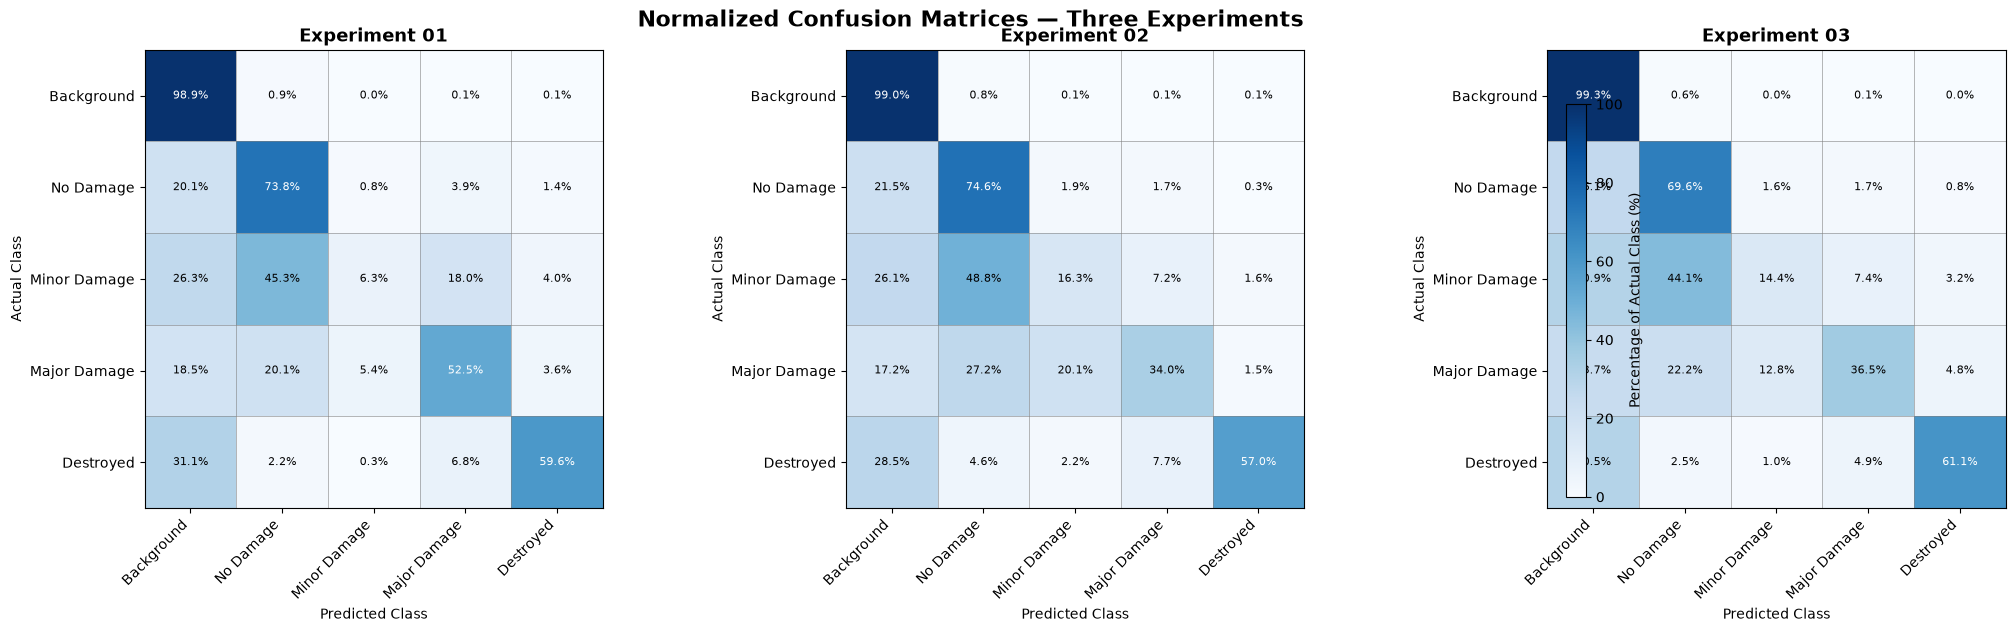

In [81]:
# ============================================================
# CELL 73 — NORMALIZED CONFUSION MATRIX COMPARISON
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

CLASS_NAMES = [
    "Background",
    "No Damage",
    "Minor Damage",
    "Major Damage",
    "Destroyed"
]

CONFUSION_MATRICES = {
    "Experiment 01": exp01_confusion_matrix,
    "Experiment 02": exp02_confusion_matrix,
    "Experiment 03": exp03_confusion_matrix
}

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

for ax, (experiment, cm_tensor) in zip(
    axes, CONFUSION_MATRICES.items()
):

    cm = cm_tensor.numpy().astype(np.float64)

    # Normalize each row to percentages
    row_sums = cm.sum(axis=1, keepdims=True)
    normalized_cm = np.divide(
        cm,
        row_sums,
        out=np.zeros_like(cm),
        where=row_sums != 0
    ) * 100

    im = ax.imshow(
        normalized_cm,
        cmap="Blues",
        vmin=0,
        vmax=100
    )

    ax.set_title(experiment, fontsize=13, fontweight="bold")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

    ax.set_xticks(range(len(CLASS_NAMES)))
    ax.set_yticks(range(len(CLASS_NAMES)))

    ax.set_xticklabels(
        CLASS_NAMES, rotation=45, ha="right"
    )
    ax.set_yticklabels(CLASS_NAMES)

    # Annotate percentages
    for i in range(len(CLASS_NAMES)):
        for j in range(len(CLASS_NAMES)):

            value = normalized_cm[i, j]

            ax.text(
                j, i,
                f"{value:.1f}%",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if value > 50 else "black"
            )

    ax.set_xticks(
        np.arange(-0.5, len(CLASS_NAMES), 1),
        minor=True
    )
    ax.set_yticks(
        np.arange(-0.5, len(CLASS_NAMES), 1),
        minor=True
    )

    ax.grid(which="minor", color="gray", linestyle="-", linewidth=0.4)
    ax.tick_params(which="minor", bottom=False, left=False)

fig.colorbar(
    im,
    ax=axes,
    label="Percentage of Actual Class (%)",
    shrink=0.85
)

fig.suptitle(
    "Normalized Confusion Matrices — Three Experiments",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [82]:
# ============================================================
# CELL 74 — TARGETED CLASSIFICATION ERROR ANALYSIS
# ============================================================

import pandas as pd
import numpy as np

CLASS_NAMES = [
    "Background",
    "No Damage",
    "Minor Damage",
    "Major Damage",
    "Destroyed"
]

CONFUSION_MATRICES = {
    "Experiment 01": exp01_confusion_matrix,
    "Experiment 02": exp02_confusion_matrix,
    "Experiment 03": exp03_confusion_matrix
}

error_records = []
recall_records = []

for experiment, cm_tensor in CONFUSION_MATRICES.items():

    cm = cm_tensor.numpy().astype(np.float64)

    row_totals = cm.sum(axis=1)
    normalized = cm / np.maximum(row_totals[:, None], 1)

    # Class-wise recall
    for i, class_name in enumerate(CLASS_NAMES):

        recall_records.append({
            "Experiment": experiment,
            "Class": class_name,
            "Recall": normalized[i, i],
            "Miss Rate": 1 - normalized[i, i]
        })

    # Off-diagonal confusion rates
    for actual_idx in range(len(CLASS_NAMES)):

        for predicted_idx in range(len(CLASS_NAMES)):

            if actual_idx == predicted_idx:
                continue

            error_records.append({
                "Experiment": experiment,
                "Actual Class": CLASS_NAMES[actual_idx],
                "Predicted Class": CLASS_NAMES[predicted_idx],
                "Misclassified Pixels": int(
                    cm[actual_idx, predicted_idx]
                ),
                "Error Rate (%)": (
                    normalized[actual_idx, predicted_idx] * 100
                )
            })

error_analysis = pd.DataFrame(error_records)
recall_analysis = pd.DataFrame(recall_records)

# ------------------------------------------------------------
# 1. Top five confusion patterns per experiment
# ------------------------------------------------------------

print("=" * 75)
print("TOP FIVE CLASSIFICATION ERRORS PER EXPERIMENT")
print("=" * 75)

for experiment in CONFUSION_MATRICES:

    print(f"\n{experiment}")

    top_errors = (
        error_analysis[
            error_analysis["Experiment"] == experiment
        ]
        .sort_values("Error Rate (%)", ascending=False)
        .head(5)
    )

    display(
        top_errors[
            [
                "Actual Class",
                "Predicted Class",
                "Misclassified Pixels",
                "Error Rate (%)"
            ]
        ].style.format({
            "Misclassified Pixels": "{:,.0f}",
            "Error Rate (%)": "{:.2f}%"
        })
    )

# ------------------------------------------------------------
# 2. Compare recall across all classes
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CLASS-WISE RECALL COMPARISON")
print("=" * 75)

display(
    recall_analysis.pivot(
        index="Class",
        columns="Experiment",
        values="Recall"
    ).style.format("{:.4f}")
)

# ------------------------------------------------------------
# 3. Focused analysis of damage categories
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("DAMAGE-CLASS ERROR RATES")
print("=" * 75)

damage_errors = error_analysis[
    error_analysis["Actual Class"].isin([
        "Minor Damage",
        "Major Damage",
        "Destroyed"
    ])
]

display(
    damage_errors.pivot_table(
        index=["Actual Class", "Predicted Class"],
        columns="Experiment",
        values="Error Rate (%)"
    ).style.format("{:.2f}%")
)

print("\nTargeted error analysis completed.")

TOP FIVE CLASSIFICATION ERRORS PER EXPERIMENT

Experiment 01


,Actual Class,Predicted Class,Misclassified Pixels,Error Rate (%)
9,Minor Damage,No Damage,"2,153,287",45.35%
16,Destroyed,Background,"954,531",31.09%
8,Minor Damage,Background,"1,251,158",26.35%
13,Major Damage,No Damage,"1,109,339",20.06%
4,No Damage,Background,"8,799,869",20.06%



Experiment 02


,Actual Class,Predicted Class,Misclassified Pixels,Error Rate (%)
29,Minor Damage,No Damage,"2,318,067",48.82%
36,Destroyed,Background,"874,000",28.46%
33,Major Damage,No Damage,"1,502,967",27.17%
28,Minor Damage,Background,"1,237,969",26.07%
24,No Damage,Background,"9,435,884",21.51%



Experiment 03


,Actual Class,Predicted Class,Misclassified Pixels,Error Rate (%)
49,Minor Damage,No Damage,"2,094,574",44.11%
48,Minor Damage,Background,"1,465,264",30.86%
56,Destroyed,Background,"937,536",30.53%
44,No Damage,Background,"11,472,071",26.15%
52,Major Damage,Background,"1,308,930",23.66%



CLASS-WISE RECALL COMPARISON


Experiment,Experiment 01,Experiment 02,Experiment 03
Class,,,
Background,0.9890,0.9902,0.9928
Destroyed,0.5957,0.5696,0.6106
Major Damage,0.5253,0.3396,0.3654
Minor Damage,0.0632,0.1634,0.1441
No Damage,0.7383,0.7463,0.6965



DAMAGE-CLASS ERROR RATES



Targeted error analysis completed.


In [83]:
# ============================================================
# CELL 75 — EXPERIMENT 04 PREPARATION AUDIT
# ============================================================

print("=" * 70)
print("TRAINING CONFIGURATION AUDIT")
print("=" * 70)

# 1. Training dataset
if "train_loader" in globals():

    print("\n1. TRAINING DATASET")
    print("Dataset type:", type(train_loader.dataset).__name__)
    print("Dataset size:", len(train_loader.dataset))

    print("\n2. DATA SAMPLING")
    print("Sampler:", type(train_loader.sampler).__name__)
    print("Batch sampler:", type(train_loader.batch_sampler).__name__)
    print("Batch size:", train_loader.batch_size)
    print("Drop last:", train_loader.drop_last)

    print("Sampler details:")
    print(train_loader.sampler)

else:
    print("\ntrain_loader not found.")

# 2. Loss function
print("\n3. CURRENT LOSS FUNCTION")

if "criterion" in globals():
    print("Criterion type:", type(criterion).__name__)
    print(criterion)
else:
    print("criterion not found.")

# 3. Experiment class weights
print("\n4. CLASS WEIGHTS")

for variable_name in [
    "EXP01_CLASS_WEIGHTS",
    "EXP02_CLASS_WEIGHTS",
    "EXP03_CLASS_WEIGHTS"
]:

    value = globals().get(variable_name)

    if value is not None:
        print(f"{variable_name}: {value}")

# 4. Dataset pixel frequencies
print("\n5. TRAINING CLASS FREQUENCIES")

if "TRAIN_CLASS_FREQUENCIES" in globals():
    print(TRAIN_CLASS_FREQUENCIES)

elif "train_class_frequencies" in globals():
    print(train_class_frequencies)

else:
    print("Previously calculated class frequencies:")
    print({
        "Background": 0.94075357,
        "No Damage": 0.04371402,
        "Minor Damage": 0.00543225,
        "Major Damage": 0.00685920,
        "Destroyed": 0.00324096
    })

print("\nTraining configuration audit completed.")

TRAINING CONFIGURATION AUDIT

1. TRAINING DATASET
Dataset type: XView2SiameseDataset
Dataset size: 2799

2. DATA SAMPLING
Sampler: RandomSampler
Batch sampler: BatchSampler
Batch size: 1
Drop last: False
Sampler details:

3. CURRENT LOSS FUNCTION
Criterion type: FocalDiceLoss
FocalDiceLoss()

4. CLASS WEIGHTS
EXP03_CLASS_WEIGHTS: [0.24186294 1.1220104  0.99700236 1.46618    1.172944  ]

5. TRAINING CLASS FREQUENCIES
[0.94075357 0.04371402 0.00543225 0.0068592  0.00324096]

Training configuration audit completed.


In [84]:
# ============================================================
# CELL 76 — DATASET AND LOSS IMPLEMENTATION INSPECTION
# ============================================================

import inspect

print("=" * 70)
print("DATASET AND LOSS IMPLEMENTATION")
print("=" * 70)

# 1. Dataset attributes
print("\n1. TRAIN DATASET ATTRIBUTES")

dataset = train_loader.dataset

for name, value in vars(dataset).items():

    if isinstance(value, (list, tuple)):
        print(f"{name}: {type(value).__name__}, length={len(value)}")

    elif isinstance(value, dict):
        print(f"{name}: dict, keys={list(value.keys())[:15]}")

    elif isinstance(value, np.ndarray):
        print(f"{name}: ndarray, shape={value.shape}, dtype={value.dtype}")

    else:
        print(f"{name}: {type(value).__name__}")

# 2. Dataset implementation
print("\n2. DATASET CLASS SOURCE")

try:
    print(inspect.getsource(type(dataset)))
except Exception as error:
    print("Source unavailable:", error)

# 3. Loss attributes
print("\n3. FOCAL DICE LOSS ATTRIBUTES")

for name, value in vars(criterion).items():
    print(f"{name}: {value}")

# 4. Loss implementation
print("\n4. LOSS CLASS SOURCE")

try:
    print(inspect.getsource(type(criterion)))
except Exception as error:
    print("Source unavailable:", error)

print("\nInspection completed.")

DATASET AND LOSS IMPLEMENTATION

1. TRAIN DATASET ATTRIBUTES
dataframe: DataFrame
split: str
augment: bool
cache_dir: WindowsPath

2. DATASET CLASS SOURCE
Source unavailable: source code not available

3. FOCAL DICE LOSS ATTRIBUTES
training: True
_parameters: {}
_buffers: {'class_weights': tensor([0.2419, 1.1220, 0.9970, 1.4662, 1.1729], device='cuda:0')}
_non_persistent_buffers_set: set()
_backward_pre_hooks: OrderedDict()
_backward_hooks: OrderedDict()
_is_full_backward_hook: None
_forward_hooks: OrderedDict()
_forward_hooks_with_kwargs: OrderedDict()
_forward_hooks_always_called: OrderedDict()
_forward_pre_hooks: OrderedDict()
_forward_pre_hooks_with_kwargs: OrderedDict()
_state_dict_hooks: OrderedDict()
_state_dict_pre_hooks: OrderedDict()
_load_state_dict_pre_hooks: OrderedDict()
_load_state_dict_post_hooks: OrderedDict()
_modules: {}
ignore_index: 255
gamma: 2.0
dice_weight: 1.0

4. LOSS CLASS SOURCE
Source unavailable: source code not available

Inspection completed.


In [85]:
# ============================================================
# CELL 77 — TRAINING DATAFRAME INSPECTION
# ============================================================

print("=" * 70)
print("TRAINING DATAFRAME STRUCTURE")
print("=" * 70)

df = train_loader.dataset.dataframe

print("\n1. DATAFRAME SHAPE")
print(df.shape)

print("\n2. COLUMN NAMES")
print(df.columns.tolist())

print("\n3. COLUMN DATA TYPES")
print(df.dtypes)

print("\n4. FIRST FIVE ROWS")
display(df.head())

print("\n5. MISSING VALUES")
display(df.isna().sum())

print("\n6. DATASET CACHE DIRECTORY")
print(train_loader.dataset.cache_dir)

print("\n7. DATASET CONFIGURATION")
print("Split:", train_loader.dataset.split)
print("Augmentation enabled:", train_loader.dataset.augment)

print("\nMetadata inspection completed.")

TRAINING DATAFRAME STRUCTURE

1. DATAFRAME SHAPE
(2799, 5)

2. COLUMN NAMES
['tile_id', 'pre_image', 'post_image', 'post_mask', 'post_label']

3. COLUMN DATA TYPES
tile_id          str
pre_image     object
post_image    object
post_mask     object
post_label    object
dtype: object

4. FIRST FIVE ROWS


,tile_id,pre_image,post_image,post_mask,post_label
0,guatemala-volcano_00000000,d:\ML_Project\dataset\train\images\guatemala-v...,d:\ML_Project\dataset\train\images\guatemala-v...,d:\ML_Project\dataset\train\targets\guatemala-...,d:\ML_Project\dataset\train\labels\guatemala-v...
1,guatemala-volcano_00000001,d:\ML_Project\dataset\train\images\guatemala-v...,d:\ML_Project\dataset\train\images\guatemala-v...,d:\ML_Project\dataset\train\targets\guatemala-...,d:\ML_Project\dataset\train\labels\guatemala-v...
2,guatemala-volcano_00000002,d:\ML_Project\dataset\train\images\guatemala-v...,d:\ML_Project\dataset\train\images\guatemala-v...,d:\ML_Project\dataset\train\targets\guatemala-...,d:\ML_Project\dataset\train\labels\guatemala-v...
3,guatemala-volcano_00000006,d:\ML_Project\dataset\train\images\guatemala-v...,d:\ML_Project\dataset\train\images\guatemala-v...,d:\ML_Project\dataset\train\targets\guatemala-...,d:\ML_Project\dataset\train\labels\guatemala-v...
4,guatemala-volcano_00000007,d:\ML_Project\dataset\train\images\guatemala-v...,d:\ML_Project\dataset\train\images\guatemala-v...,d:\ML_Project\dataset\train\targets\guatemala-...,d:\ML_Project\dataset\train\labels\guatemala-v...



5. MISSING VALUES


tile_id       0
pre_image     0
post_image    0
post_mask     0
post_label    0
dtype: int64


6. DATASET CACHE DIRECTORY
d:\ML_Project\processed\targets\train

7. DATASET CONFIGURATION
Split: train
Augmentation enabled: True

Metadata inspection completed.


In [86]:
# ============================================================
# CELL 78 — MASK FILE FORMAT AND ENCODING INSPECTION
# ============================================================

from pathlib import Path
import numpy as np

df = train_loader.dataset.dataframe

print("=" * 70)
print("MASK FILE INSPECTION")
print("=" * 70)

# 1. Inspect original mask paths
print("\n1. ORIGINAL MASK FILES")

for i in range(min(5, len(df))):

    path = Path(df.iloc[i]["post_mask"])

    print(f"\nTile: {df.iloc[i]['tile_id']}")
    print("Path:", path)
    print("Exists:", path.exists())
    print("Suffix:", path.suffix)

# 2. Inspect processed target cache
cache_dir = Path(train_loader.dataset.cache_dir)

print("\n2. PROCESSED TARGET CACHE")
print("Cache directory:", cache_dir)
print("Exists:", cache_dir.exists())

if cache_dir.exists():

    cache_files = list(cache_dir.iterdir())

    print("Number of cached files:", len(cache_files))

    for path in cache_files[:10]:
        print(path.name, "|", path.suffix, "|", path.stat().st_size, "bytes")

# 3. Inspect one dataset sample
print("\n3. DATASET SAMPLE")

sample = train_loader.dataset[0]

for key, value in sample.items():

    if torch.is_tensor(value):
        print(
            key,
            "| shape:", tuple(value.shape),
            "| dtype:", value.dtype
        )

        if key == "mask":
            print("Unique mask values:", torch.unique(value).tolist())

    else:
        print(key, "|", type(value).__name__, "|", value)

# 4. Inspect original mask using PIL if available
print("\n4. ORIGINAL MASK ENCODING")

from PIL import Image

sample_mask_path = Path(df.iloc[0]["post_mask"])

if sample_mask_path.exists():

    with Image.open(sample_mask_path) as image:

        mask_array = np.array(image)

        print("Image mode:", image.mode)
        print("Array shape:", mask_array.shape)
        print("Array dtype:", mask_array.dtype)
        print("Unique values:", np.unique(mask_array)[:30])

else:
    print("Original mask file not found.")

print("\nMask inspection completed.")

MASK FILE INSPECTION

1. ORIGINAL MASK FILES

Tile: guatemala-volcano_00000000
Path: d:\ML_Project\dataset\train\targets\guatemala-volcano_00000000_post_disaster_target.png
Exists: True
Suffix: .png

Tile: guatemala-volcano_00000001
Path: d:\ML_Project\dataset\train\targets\guatemala-volcano_00000001_post_disaster_target.png
Exists: True
Suffix: .png

Tile: guatemala-volcano_00000002
Path: d:\ML_Project\dataset\train\targets\guatemala-volcano_00000002_post_disaster_target.png
Exists: True
Suffix: .png

Tile: guatemala-volcano_00000006
Path: d:\ML_Project\dataset\train\targets\guatemala-volcano_00000006_post_disaster_target.png
Exists: True
Suffix: .png

Tile: guatemala-volcano_00000007
Path: d:\ML_Project\dataset\train\targets\guatemala-volcano_00000007_post_disaster_target.png
Exists: True
Suffix: .png

2. PROCESSED TARGET CACHE
Cache directory: d:\ML_Project\processed\targets\train
Exists: True
Number of cached files: 2799
guatemala-volcano_00000000.png | .png | 2978 bytes
guatemala-

In [87]:
# ============================================================
# CELL 79 — PER-TILE CLASS DISTRIBUTION ANALYSIS
# ============================================================

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
import numpy as np
import pandas as pd

print("=" * 70)
print("PER-TILE CLASS DISTRIBUTION ANALYSIS")
print("=" * 70)

df = train_loader.dataset.dataframe
cache_dir = Path(train_loader.dataset.cache_dir)

NUM_CLASSES = 5
IGNORE_INDEX = 255

class_names = [
    "Background",
    "No Damage",
    "Minor Damage",
    "Major Damage",
    "Destroyed"
]

tile_records = []
global_counts = np.zeros(NUM_CLASSES, dtype=np.int64)

for _, row in tqdm(df.iterrows(), total=len(df), desc="Scanning masks"):

    tile_id = row["tile_id"]
    mask_path = cache_dir / f"{tile_id}.png"

    if not mask_path.exists():
        raise FileNotFoundError(f"Missing cached mask: {mask_path}")

    with Image.open(mask_path) as image:
        mask = np.asarray(image, dtype=np.uint8)

    valid_mask = mask[mask != IGNORE_INDEX]

    invalid_values = np.setdiff1d(
        np.unique(valid_mask),
        np.arange(NUM_CLASSES)
    )

    if len(invalid_values) > 0:
        raise ValueError(
            f"Unexpected class values in {tile_id}: {invalid_values}"
        )

    counts = np.bincount(
        valid_mask.astype(np.int64),
        minlength=NUM_CLASSES
    )

    global_counts += counts

    record = {"tile_id": tile_id}

    for class_id, class_name in enumerate(class_names):
        record[class_name] = int(counts[class_id])

    record["Valid Pixels"] = int(counts.sum())

    tile_records.append(record)

tile_class_distribution = pd.DataFrame(tile_records)

# ------------------------------------------------------------
# 1. Global pixel distribution
# ------------------------------------------------------------

print("\n1. GLOBAL TRAINING PIXEL DISTRIBUTION")

total_pixels = global_counts.sum()

global_distribution = pd.DataFrame({
    "Class": class_names,
    "Pixel Count": global_counts,
    "Frequency (%)": global_counts / total_pixels * 100
})

display(
    global_distribution.style.format({
        "Pixel Count": "{:,.0f}",
        "Frequency (%)": "{:.5f}%"
    })
)

# ------------------------------------------------------------
# 2. Number of tiles containing each class
# ------------------------------------------------------------

print("\n2. TILE-LEVEL CLASS PRESENCE")

presence_records = []

for class_name in class_names:

    present = (
        tile_class_distribution[class_name] > 0
    ).sum()

    presence_records.append({
        "Class": class_name,
        "Tiles Containing Class": int(present),
        "Percentage of Tiles": present / len(df) * 100
    })

tile_presence_summary = pd.DataFrame(presence_records)

display(
    tile_presence_summary.style.format({
        "Tiles Containing Class": "{:,.0f}",
        "Percentage of Tiles": "{:.2f}%"
    })
)

# ------------------------------------------------------------
# 3. Tiles containing multiple damage classes
# ------------------------------------------------------------

damage_columns = class_names[2:]

tile_class_distribution["Damage Class Count"] = (
    tile_class_distribution[damage_columns] > 0
).sum(axis=1)

print("\n3. NUMBER OF DAMAGE CLASSES PER TILE")

display(
    tile_class_distribution["Damage Class Count"]
    .value_counts()
    .sort_index()
    .rename_axis("Damage Classes Present")
    .to_frame("Number of Tiles")
)

# ------------------------------------------------------------
# 4. Tiles with rare damage classes
# ------------------------------------------------------------

print("\n4. RARE-CLASS TILE EXAMPLES")

for class_name in ["Minor Damage", "Major Damage", "Destroyed"]:

    subset = tile_class_distribution[
        tile_class_distribution[class_name] > 0
    ].sort_values(class_name, ascending=False)

    print(f"\n{class_name}: {len(subset)} tiles")

    display(
        subset[
            ["tile_id", class_name, "Valid Pixels"]
        ].head(5)
    )

# ------------------------------------------------------------
# 5. Verify global frequencies
# ------------------------------------------------------------

print("\n5. GLOBAL FREQUENCY VALIDATION")

calculated_frequencies = global_counts / total_pixels

print("Calculated frequencies:", calculated_frequencies)
print("Previously recorded frequencies:", TRAIN_CLASS_FREQUENCIES
      if "TRAIN_CLASS_FREQUENCIES" in globals()
      else "[Reference values available in project history]")

print("\nTotal valid pixels:", f"{total_pixels:,}")
print("Tiles scanned:", len(tile_class_distribution))

print("\nPer-tile distribution analysis completed.")


PER-TILE CLASS DISTRIBUTION ANALYSIS


Scanning masks:   0%|          | 0/2799 [00:00<?, ?it/s]


1. GLOBAL TRAINING PIXEL DISTRIBUTION


,Class,Pixel Count,Frequency (%)
0,Background,"2,759,708,986",94.07536%
1,No Damage,"128,235,472",4.37140%
2,Minor Damage,"15,935,554",0.54323%
3,Major Damage,"20,121,529",0.68592%
4,Destroyed,"9,507,380",0.32410%



2. TILE-LEVEL CLASS PRESENCE


,Class,Tiles Containing Class,Percentage of Tiles
0,Background,"2,799",100.00%
1,No Damage,"1,733",61.91%
2,Minor Damage,853,30.48%
3,Major Damage,920,32.87%
4,Destroyed,897,32.05%


... (5 outputs left out)

,tile_id,Major Damage,Valid Pixels
598,hurricane-harvey_00000434,338528,1046781
591,hurricane-harvey_00000426,333613,1048576
555,hurricane-harvey_00000358,316817,1048576
429,hurricane-harvey_00000146,298857,1048576
420,hurricane-harvey_00000132,292103,1048576



Destroyed: 897 tiles


,tile_id,Destroyed,Valid Pixels
1707,palu-tsunami_00000118,468579,1048576
1789,santa-rosa-wildfire_00000063,220082,1048576
1801,santa-rosa-wildfire_00000084,219686,1048576
1843,santa-rosa-wildfire_00000155,206821,1048576
1846,santa-rosa-wildfire_00000161,192041,1048576



5. GLOBAL FREQUENCY VALIDATION
Calculated frequencies: [0.94075357 0.04371402 0.00543225 0.0068592  0.00324096]
Previously recorded frequencies: [Reference values available in project history]

Total valid pixels: 2,933,508,921
Tiles scanned: 2799

Per-tile distribution analysis completed.


In [88]:
# ============================================================
# CELL 80 — EXPERIMENT 04 SAMPLING STRATEGY
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("EXPERIMENT 04 — SAMPLING STRATEGY SIMULATION")
print("=" * 70)

# Per-tile class counts, in dataset order
tile_counts = tile_class_distribution[
    class_names
].to_numpy(dtype=np.float64)

# Conservative class-aware sampling contributions
sampling_weights = (
    1.0
    + 1.50 * (tile_counts[:, 2] > 0)  # Minor damage
    + 0.75 * (tile_counts[:, 3] > 0)  # Major damage
    + 0.75 * (tile_counts[:, 4] > 0)  # Destroyed
)

# Normalize for readability
sampling_probabilities = (
    sampling_weights / sampling_weights.sum()
)

# ------------------------------------------------------------
# 1. Sampling weight distribution
# ------------------------------------------------------------

print("\n1. SAMPLING WEIGHT DISTRIBUTION")

print("Minimum weight:", sampling_weights.min())
print("Maximum weight:", sampling_weights.max())
print("Mean weight:", sampling_weights.mean())

print("\nWeight frequencies:")

display(
    pd.Series(sampling_weights)
    .value_counts()
    .sort_index()
    .rename_axis("Sampling Weight")
    .to_frame("Number of Tiles")
)

# ------------------------------------------------------------
# 2. Expected class presence in sampled tiles
# ------------------------------------------------------------

print("\n2. EXPECTED CLASS PRESENCE")

presence = (tile_counts > 0).astype(np.float64)

original_presence = presence.mean(axis=0)

sampled_presence = (
    sampling_probabilities @ presence
)

presence_comparison = pd.DataFrame({
    "Class": class_names,
    "Original Tile Presence (%)": original_presence * 100,
    "Expected Sampled Presence (%)": sampled_presence * 100
})

display(
    presence_comparison.style.format({
        "Original Tile Presence (%)": "{:.2f}%",
        "Expected Sampled Presence (%)": "{:.2f}%"
    })
)

# ------------------------------------------------------------
# 3. Expected pixel distribution
# ------------------------------------------------------------

print("\n3. EXPECTED PIXEL DISTRIBUTION")

original_pixel_distribution = (
    tile_counts.sum(axis=0) / tile_counts.sum()
)

weighted_pixel_counts = (
    sampling_probabilities @ tile_counts
)

sampled_pixel_distribution = (
    weighted_pixel_counts / weighted_pixel_counts.sum()
)

pixel_comparison = pd.DataFrame({
    "Class": class_names,
    "Original Pixel Frequency (%)":
        original_pixel_distribution * 100,
    "Expected Sampled Pixel Frequency (%)":
        sampled_pixel_distribution * 100
})

display(
    pixel_comparison.style.format({
        "Original Pixel Frequency (%)": "{:.4f}%",
        "Expected Sampled Pixel Frequency (%)": "{:.4f}%"
    })
)

# ------------------------------------------------------------
# 4. Effective sampling concentration
# ------------------------------------------------------------

effective_sample_size = (
    sampling_weights.sum() ** 2 /
    np.square(sampling_weights).sum()
)

print("\n4. SAMPLING DIAGNOSTICS")
print("Original training tiles:", len(sampling_weights))
print("Samples per epoch:", len(sampling_weights))
print("Effective sample size:", round(effective_sample_size, 1))
print(
    "Effective sample size percentage:",
    round(effective_sample_size / len(sampling_weights) * 100, 2),
    "%"
)

# ------------------------------------------------------------
# 5. Save proposed weights
# ------------------------------------------------------------

EXP04_SAMPLING_WEIGHTS = sampling_weights.astype(np.float64)

print("\nSampling simulation completed.")
print("No DataLoader or model configuration was modified.")

EXPERIMENT 04 — SAMPLING STRATEGY SIMULATION

1. SAMPLING WEIGHT DISTRIBUTION
Minimum weight: 1.0
Maximum weight: 4.0
Mean weight: 1.9439978563772775

Weight frequencies:


,Number of Tiles
Sampling Weight,
1.00,1298
1.75,479
2.50,359
3.25,326
4.00,337



2. EXPECTED CLASS PRESENCE


,Class,Original Tile Presence (%),Expected Sampled Presence (%)
0,Background,100.00%,100.00%
1,No Damage,61.91%,66.36%
2,Minor Damage,30.48%,52.97%
3,Major Damage,32.87%,52.47%
4,Destroyed,32.05%,47.48%



3. EXPECTED PIXEL DISTRIBUTION


,Class,Original Pixel Frequency (%),Expected Sampled Pixel Frequency (%)
0,Background,94.0754%,93.5979%
1,No Damage,4.3714%,3.9015%
2,Minor Damage,0.5432%,0.9552%
3,Major Damage,0.6859%,1.1098%
4,Destroyed,0.3241%,0.4355%



4. SAMPLING DIAGNOSTICS
Original training tiles: 2799
Samples per epoch: 2799
Effective sample size: 2138.6
Effective sample size percentage: 76.41 %

Sampling simulation completed.
No DataLoader or model configuration was modified.


In [89]:
# ============================================================
# CELL 81 — EXPERIMENT 04 DATALOADER AUDIT
# ============================================================

print("=" * 70)
print("EXPERIMENT 04 — DATALOADER AUDIT")
print("=" * 70)

# 1. Dataset and DataLoader configuration
print("\n1. EXISTING TRAIN DATALOADER")
print("Dataset type:", type(train_dataset).__name__)
print("Dataset size:", len(train_dataset))
print("Batch size:", train_loader.batch_size)
print("Number of workers:", train_loader.num_workers)
print("Pin memory:", train_loader.pin_memory)
print("Drop last:", train_loader.drop_last)
print("Persistent workers:", train_loader.persistent_workers)
print("Sampler type:", type(train_loader.sampler).__name__)
print("Collate function:", train_loader.collate_fn)

# 2. Verify sampling-weight alignment
dataset_tile_ids = (
    train_dataset.dataframe["tile_id"]
    .astype(str)
    .reset_index(drop=True)
)

distribution_tile_ids = (
    train_dataset.dataframe["tile_id"]
    .astype(str)
    .reset_index(drop=True)
)

print("\n2. SAMPLING ALIGNMENT")
print("Dataset tile IDs:", len(dataset_tile_ids))
print("Sampling weights:", len(EXP04_SAMPLING_WEIGHTS))
print(
    "Tile IDs unique:",
    dataset_tile_ids.is_unique
)
print(
    "Weight count matches dataset:",
    len(EXP04_SAMPLING_WEIGHTS) == len(train_dataset)
)

assert len(EXP04_SAMPLING_WEIGHTS) == len(train_dataset)
assert dataset_tile_ids.is_unique

# 3. Check the class-distribution row count
assert len(tile_class_distribution) == len(train_dataset)

print(
    "Class-distribution rows match dataset:",
    len(tile_class_distribution) == len(train_dataset)
)

print("\n4. CURRENT TRAINING SETTINGS")
print("Dataset split:", train_dataset.split)
print("Augmentation enabled:", train_dataset.augment)
print("Cache directory:", train_dataset.cache_dir)

print("\nDataLoader audit completed.")
print("No training configuration was modified.")

EXPERIMENT 04 — DATALOADER AUDIT

1. EXISTING TRAIN DATALOADER
Dataset type: XView2SiameseDataset
Dataset size: 2799
Batch size: 1
Number of workers: 0
Pin memory: True
Drop last: False
Persistent workers: False
Sampler type: RandomSampler
Collate function: <function default_collate at 0x00000261D4771E40>

2. SAMPLING ALIGNMENT
Dataset tile IDs: 2799
Sampling weights: 2799
Tile IDs unique: True
Weight count matches dataset: True
Class-distribution rows match dataset: True

4. CURRENT TRAINING SETTINGS
Dataset split: train
Augmentation enabled: True
Cache directory: d:\ML_Project\processed\targets\train

DataLoader audit completed.
No training configuration was modified.


In [90]:
# ============================================================
# CELL 81 — EXPERIMENT 04 WEIGHTED DATALOADER
# ============================================================

import torch
from torch.utils.data import DataLoader, WeightedRandomSampler

print("=" * 70)
print("EXPERIMENT 04 — WEIGHTED DATALOADER CONFIGURATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. VALIDATE SAMPLING WEIGHTS
# ------------------------------------------------------------

assert len(EXP04_SAMPLING_WEIGHTS) == len(train_loader.dataset)
assert len(tile_class_distribution) == len(train_loader.dataset)
assert np.all(EXP04_SAMPLING_WEIGHTS > 0)

# ------------------------------------------------------------
# 2. CREATE WEIGHTED RANDOM SAMPLER
# ------------------------------------------------------------

EXP04_SAMPLER_GENERATOR = torch.Generator()
EXP04_SAMPLER_GENERATOR.manual_seed(42)

EXP04_SAMPLER = WeightedRandomSampler(
    weights=torch.as_tensor(
        EXP04_SAMPLING_WEIGHTS,
        dtype=torch.double
    ),
    num_samples=len(train_loader.dataset),
    replacement=True,
    generator=EXP04_SAMPLER_GENERATOR
)

# ------------------------------------------------------------
# 3. CREATE NEW TRAINING DATALOADER
# ------------------------------------------------------------

EXP04_TRAIN_LOADER = DataLoader(
    dataset=train_loader.dataset,
    batch_size=train_loader.batch_size,
    sampler=EXP04_SAMPLER,
    num_workers=train_loader.num_workers,
    pin_memory=train_loader.pin_memory,
    drop_last=train_loader.drop_last,
    persistent_workers=train_loader.persistent_workers,
    collate_fn=train_loader.collate_fn
)

# ------------------------------------------------------------
# 4. SIMULATE ONE EPOCH WITHOUT LOADING IMAGES
# ------------------------------------------------------------

diagnostic_generator = torch.Generator()
diagnostic_generator.manual_seed(42)

simulated_indices = torch.multinomial(
    torch.as_tensor(EXP04_SAMPLING_WEIGHTS, dtype=torch.double),
    num_samples=len(train_loader.dataset),
    replacement=True,
    generator=diagnostic_generator
).numpy()

simulated_presence = (
    tile_counts[simulated_indices] > 0
).mean(axis=0) * 100

unique_sampled_tiles = len(np.unique(simulated_indices))
duplicate_draws = len(simulated_indices) - unique_sampled_tiles

# ------------------------------------------------------------
# 5. REPORT CONFIGURATION
# ------------------------------------------------------------

print("\n1. WEIGHTED DATALOADER")
print("Dataset size:", len(EXP04_TRAIN_LOADER.dataset))
print("Batch size:", EXP04_TRAIN_LOADER.batch_size)
print("Number of workers:", EXP04_TRAIN_LOADER.num_workers)
print("Pin memory:", EXP04_TRAIN_LOADER.pin_memory)
print("Drop last:", EXP04_TRAIN_LOADER.drop_last)
print("Sampler:", type(EXP04_TRAIN_LOADER.sampler).__name__)
print("Replacement:", EXP04_TRAIN_LOADER.sampler.replacement)

print("\n2. SIMULATED EPOCH")
print("Total sampled tiles:", len(simulated_indices))
print("Unique tiles sampled:", unique_sampled_tiles)
print("Repeated draws:", duplicate_draws)
print(
    "Unique tile coverage:",
    round(unique_sampled_tiles / len(train_loader.dataset) * 100, 2),
    "%"
)

print("\n3. REALIZED CLASS PRESENCE")
for class_name, percentage in zip(class_names, simulated_presence):
    print(f"{class_name:<15}: {percentage:.2f}%")

# ------------------------------------------------------------
# 6. VERIFY ORIGINAL LOADER IS UNCHANGED
# ------------------------------------------------------------

print("\n4. ORIGINAL LOADER")
print("Original sampler:", type(train_loader.sampler).__name__)
print("Original dataset size:", len(train_loader.dataset))

assert isinstance(EXP04_TRAIN_LOADER.sampler, WeightedRandomSampler)
assert isinstance(train_loader.sampler, torch.utils.data.RandomSampler)
assert EXP04_TRAIN_LOADER.dataset is train_loader.dataset

print("\nExperiment 04 weighted DataLoader created successfully.")
print("Original training DataLoader remains unchanged.")
print("No model or optimizer configuration was modified.")

EXPERIMENT 04 — WEIGHTED DATALOADER CONFIGURATION

1. WEIGHTED DATALOADER
Dataset size: 2799
Batch size: 1
Number of workers: 0
Pin memory: True
Drop last: False
Sampler: WeightedRandomSampler
Replacement: True

2. SIMULATED EPOCH
Total sampled tiles: 2799
Unique tiles sampled: 1614
Repeated draws: 1185
Unique tile coverage: 57.66 %

3. REALIZED CLASS PRESENCE
Background     : 100.00%
No Damage      : 67.42%
Minor Damage   : 53.59%
Major Damage   : 51.45%
Destroyed      : 45.59%

4. ORIGINAL LOADER
Original sampler: RandomSampler
Original dataset size: 2799

Experiment 04 weighted DataLoader created successfully.
Original training DataLoader remains unchanged.
No model or optimizer configuration was modified.


In [91]:
# ============================================================
# CELL 82 — EXPERIMENT 04 INITIALIZATION AUDIT
# ============================================================

import os
import torch

print("=" * 70)
print("EXPERIMENT 04 — INITIALIZATION AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. VERIFY EXPERIMENT 02 CHECKPOINT
# ------------------------------------------------------------

assert os.path.exists(EXP02_BEST_PATH), (
    f"Experiment 02 checkpoint not found: {EXP02_BEST_PATH}"
)

exp04_initial_checkpoint = torch.load(
    EXP02_BEST_PATH,
    map_location="cpu",
    weights_only=False
)

print("\n1. INITIAL CHECKPOINT")
print("Path:", EXP02_BEST_PATH)
print("Checkpoint keys:", list(exp04_initial_checkpoint.keys()))

for key, value in exp04_initial_checkpoint.items():
    if key not in ("model_state_dict", "state_dict", "model"):
        if isinstance(value, (str, int, float, bool, type(None))):
            print(f"{key}: {value}")

# ------------------------------------------------------------
# 2. VERIFY MODEL STATE DICTIONARY
# ------------------------------------------------------------

state_key = next(
    (
        key for key in ("model_state_dict", "state_dict", "model")
        if key in exp04_initial_checkpoint
        and isinstance(exp04_initial_checkpoint[key], dict)
    ),
    None
)

print("\n2. MODEL STATE")
print("Detected state dictionary key:", state_key)

assert state_key is not None, (
    "Could not identify the model state dictionary key."
)

checkpoint_state = exp04_initial_checkpoint[state_key]

print("Number of model parameters/buffers:", len(checkpoint_state))
print("First five state keys:", list(checkpoint_state.keys())[:5])

# ------------------------------------------------------------
# 3. VERIFY EXPERIMENT 03 LOSS CONFIGURATION
# ------------------------------------------------------------

print("\n3. LOSS CONFIGURATION")

print("Experiment 03 class weights:", EXP03_CLASS_WEIGHTS)
print("Experiment 03 loss gamma:", 2.0)
print("Experiment 03 Dice weight:", 1.0)
print("Ignore index:", 255)

# ------------------------------------------------------------
# 4. VERIFY EXPERIMENT 04 SAMPLING
# ------------------------------------------------------------

print("\n4. SAMPLING CONFIGURATION")
print("Sampler:", type(EXP04_TRAIN_LOADER.sampler).__name__)
print("Samples per epoch:", len(EXP04_TRAIN_LOADER))
print("Replacement:", EXP04_TRAIN_LOADER.sampler.replacement)

print("\nInitialization audit completed.")
print("No model weights, optimizer, or DataLoader were modified.")

EXPERIMENT 04 — INITIALIZATION AUDIT

1. INITIAL CHECKPOINT
Path: d:\ML_Project\checkpoints\siamese_unet_resnet34_focal_best.pth
Checkpoint keys: ['experiment_name', 'epoch', 'best_hold_miou', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'scaler_state_dict', 'history', 'class_mapping', 'ignore_index', 'config', 'random_state', 'numpy_random_state', 'torch_random_state', 'cuda_random_state']
experiment_name: EXP_02_SIAMESE_UNET_FOCAL
epoch: 1
best_hold_miou: 0.3454142212867737
ignore_index: 255

2. MODEL STATE
Detected state dictionary key: model_state_dict
Number of model parameters/buffers: 259
First five state keys: ['stem.0.weight', 'stem.1.weight', 'stem.1.bias', 'stem.1.running_mean', 'stem.1.running_var']

3. LOSS CONFIGURATION
Experiment 03 class weights: [0.24186294 1.1220104  0.99700236 1.46618    1.172944  ]
Experiment 03 loss gamma: 2.0
Experiment 03 Dice weight: 1.0
Ignore index: 255

4. SAMPLING CONFIGURATION
Sampler: WeightedRandomSampler
Samples pe

In [92]:
# ============================================================
# CELL 83 — EXPERIMENT 04 MODEL INITIALIZATION
# ============================================================

import copy
import torch

print("=" * 70)
print("EXPERIMENT 04 — MODEL INITIALIZATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. CREATE MODEL
# ------------------------------------------------------------

EXP04_MODEL = SiameseUNet(
    num_classes=5
).to(DEVICE)

# ------------------------------------------------------------
# 2. LOAD EXPERIMENT 02 BEST MODEL WEIGHTS
# ------------------------------------------------------------

EXP04_MODEL.load_state_dict(
    exp04_initial_checkpoint["model_state_dict"],
    strict=True
)

EXP04_MODEL.train()

# ------------------------------------------------------------
# 3. VERIFY MODEL PARAMETERS
# ------------------------------------------------------------

total_parameters = sum(
    parameter.numel()
    for parameter in EXP04_MODEL.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in EXP04_MODEL.parameters()
    if parameter.requires_grad
)

print("\n1. MODEL")
print("Architecture: Siamese U-Net with ResNet-34 encoder")
print("Device:", DEVICE)
print("Total parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")
print("Model mode:", "Training" if EXP04_MODEL.training else "Evaluation")

# ------------------------------------------------------------
# 4. VERIFY INITIALIZATION AGAINST CHECKPOINT
# ------------------------------------------------------------

model_state = EXP04_MODEL.state_dict()

matching_tensors = all(
    torch.equal(
        model_state[key].detach().cpu(),
        value.detach().cpu()
    )
    for key, value in exp04_initial_checkpoint["model_state_dict"].items()
)

assert matching_tensors, "Checkpoint weight verification failed."

print("\n2. CHECKPOINT VERIFICATION")
print("Checkpoint epoch:", exp04_initial_checkpoint["epoch"])
print("Checkpoint experiment:", exp04_initial_checkpoint["experiment_name"])
print("All model tensors match checkpoint:", matching_tensors)

# ------------------------------------------------------------
# 5. PRESERVE INITIALIZATION METADATA
# ------------------------------------------------------------

EXP04_INITIAL_EPOCH = 0
EXP04_INITIAL_CHECKPOINT = EXP02_BEST_PATH
EXP04_INITIAL_MODEL_STATE = copy.deepcopy(
    exp04_initial_checkpoint["model_state_dict"]
)

print("\nExperiment 04 model initialized successfully.")
print("No training has started.")

EXPERIMENT 04 — MODEL INITIALIZATION

1. MODEL
Architecture: Siamese U-Net with ResNet-34 encoder
Device: cuda
Total parameters: 22,810,885
Trainable parameters: 22,810,885
Model mode: Training

2. CHECKPOINT VERIFICATION
Checkpoint epoch: 1
Checkpoint experiment: EXP_02_SIAMESE_UNET_FOCAL
All model tensors match checkpoint: True

Experiment 04 model initialized successfully.
No training has started.


In [94]:
# ============================================================
# CELL 84 — EXPERIMENT 04 LOSS CONFIGURATION
# ============================================================

print("=" * 70)
print("EXPERIMENT 04 — LOSS CONFIGURATION")
print("=" * 70)

EXP04_CLASS_WEIGHTS = torch.as_tensor(
    EXP03_CLASS_WEIGHTS,
    dtype=torch.float32,
    device=DEVICE
)

EXP04_CRITERION = FocalDiceLoss(
    class_weights=EXP04_CLASS_WEIGHTS,
    gamma=2.0,
    ignore_index=255,
    dice_weight=1.0
).to(DEVICE)

print("\n1. LOSS")
print("Loss function:", type(EXP04_CRITERION).__name__)
print("Class weights:", EXP04_CLASS_WEIGHTS.detach().cpu().numpy())
print("Focal gamma:", 2.0)
print("Dice weight:", 1.0)
print("Ignore index:", 255)

# ============================================================
# CELL 84A — VERIFY EXPERIMENT 04 LOSS
# ============================================================

print("=" * 70)
print("EXPERIMENT 04 — LOSS VERIFICATION")
print("=" * 70)

print("Configured device:", DEVICE)
print("Actual model device:", next(EXP04_MODEL.parameters()).device)
print("Actual loss weight device:", EXP04_CLASS_WEIGHTS.device)

assert torch.allclose(
    EXP04_CLASS_WEIGHTS.detach().cpu(),
    torch.as_tensor(EXP03_CLASS_WEIGHTS, dtype=torch.float32)
)

assert EXP04_CLASS_WEIGHTS.device == next(
    EXP04_MODEL.parameters()
).device

assert isinstance(EXP04_CRITERION, FocalDiceLoss)

print("\nClass weights verified.")
print("Loss and model devices match.")
print("Loss function verified.")
print("\nExperiment 04 loss configuration passed.")
print("No training has started.")

EXPERIMENT 04 — LOSS CONFIGURATION

1. LOSS
Loss function: FocalDiceLoss
Class weights: [0.24186294 1.1220104  0.99700236 1.46618    1.172944  ]
Focal gamma: 2.0
Dice weight: 1.0
Ignore index: 255
EXPERIMENT 04 — LOSS VERIFICATION
Configured device: cuda
Actual model device: cuda:0
Actual loss weight device: cuda:0

Class weights verified.
Loss and model devices match.
Loss function verified.

Experiment 04 loss configuration passed.
No training has started.


In [95]:
# ============================================================
# CELL 85 — EXPERIMENT 04 OPTIMIZER CONFIGURATION
# ============================================================

print("=" * 70)
print("EXPERIMENT 04 — OPTIMIZER CONFIGURATION")
print("=" * 70)

EXP04_LEARNING_RATE = 1e-5
EXP04_WEIGHT_DECAY = 1e-4

EXP04_OPTIMIZER = torch.optim.AdamW(
    EXP04_MODEL.parameters(),
    lr=EXP04_LEARNING_RATE,
    weight_decay=EXP04_WEIGHT_DECAY
)

# ------------------------------------------------------------
# VERIFY OPTIMIZER
# ------------------------------------------------------------

optimizer_params = EXP04_OPTIMIZER.param_groups[0]

print("\n1. OPTIMIZER")
print("Optimizer:", type(EXP04_OPTIMIZER).__name__)
print("Learning rate:", optimizer_params["lr"])
print("Weight decay:", optimizer_params["weight_decay"])
print("Betas:", optimizer_params["betas"])
print("Epsilon:", optimizer_params["eps"])

print("\n2. PARAMETER VERIFICATION")
print(
    "Optimizer parameter tensors:",
    len(optimizer_params["params"])
)

print(
    "Model parameter tensors:",
    sum(1 for p in EXP04_MODEL.parameters() if p.requires_grad)
)

assert optimizer_params["lr"] == EXP04_LEARNING_RATE
assert optimizer_params["weight_decay"] == EXP04_WEIGHT_DECAY

assert len(optimizer_params["params"]) == sum(
    1 for p in EXP04_MODEL.parameters() if p.requires_grad
)

print("\nExperiment 04 optimizer configured successfully.")
print("Fresh optimizer state initialized.")
print("No training has started.")

EXPERIMENT 04 — OPTIMIZER CONFIGURATION

1. OPTIMIZER
Optimizer: AdamW
Learning rate: 1e-05
Weight decay: 0.0001
Betas: (0.9, 0.999)
Epsilon: 1e-08

2. PARAMETER VERIFICATION
Optimizer parameter tensors: 151
Model parameter tensors: 151

Experiment 04 optimizer configured successfully.
Fresh optimizer state initialized.
No training has started.


In [96]:
# ============================================================
# CELL 86 — EXPERIMENT 04 SCHEDULER CONFIGURATION
# ============================================================

print("=" * 70)
print("EXPERIMENT 04 — SCHEDULER CONFIGURATION")
print("=" * 70)

EXP04_SCHEDULER = torch.optim.lr_scheduler.ReduceLROnPlateau(
    EXP04_OPTIMIZER,
    mode="max",
    factor=0.5,
    patience=3,
    threshold=0.001,
    min_lr=1e-7
)

print("\n1. SCHEDULER")
print("Scheduler:", type(EXP04_SCHEDULER).__name__)
print("Mode: max")
print("Factor: 0.5")
print("Patience: 3")
print("Threshold: 0.001")
print("Minimum learning rate: 1e-7")

print("\n2. INITIAL LEARNING RATE")
print("Learning rate:", EXP04_OPTIMIZER.param_groups[0]["lr"])

assert EXP04_OPTIMIZER.param_groups[0]["lr"] == 1e-5
assert EXP04_SCHEDULER.patience == 3
assert EXP04_SCHEDULER.factor == 0.5

print("\nExperiment 04 scheduler configured successfully.")
print("No training has started.")

EXPERIMENT 04 — SCHEDULER CONFIGURATION

1. SCHEDULER
Scheduler: ReduceLROnPlateau
Mode: max
Factor: 0.5
Patience: 3
Threshold: 0.001
Minimum learning rate: 1e-7

2. INITIAL LEARNING RATE
Learning rate: 1e-05

Experiment 04 scheduler configured successfully.
No training has started.


In [97]:
# ============================================================
# CELL 87 — EXPERIMENT 04 TRAINING CONFIGURATION
# ============================================================

print("=" * 70)
print("EXPERIMENT 04 — TRAINING CONFIGURATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. TRAINING PARAMETERS
# ------------------------------------------------------------

EXP04_EPOCHS = 15
EXP04_EARLY_STOPPING_PATIENCE = 5
EXP04_GRAD_ACCUMULATION_STEPS = 2
EXP04_GRAD_CLIP_NORM = 1.0

# ------------------------------------------------------------
# 2. MIXED PRECISION
# ------------------------------------------------------------

EXP04_USE_AMP = True

EXP04_SCALER = torch.amp.GradScaler(
    "cuda",
    enabled=EXP04_USE_AMP
)

# ------------------------------------------------------------
# 3. RANDOM SEED
# ------------------------------------------------------------

EXP04_RANDOM_SEED = 42

torch.manual_seed(EXP04_RANDOM_SEED)
torch.cuda.manual_seed_all(EXP04_RANDOM_SEED)
np.random.seed(EXP04_RANDOM_SEED)

# ------------------------------------------------------------
# 4. REPORT CONFIGURATION
# ------------------------------------------------------------

print("\n1. TRAINING")
print("Maximum epochs:", EXP04_EPOCHS)
print("Early stopping patience:", EXP04_EARLY_STOPPING_PATIENCE)
print("Gradient accumulation:", EXP04_GRAD_ACCUMULATION_STEPS)
print("Gradient clipping:", EXP04_GRAD_CLIP_NORM)

print("\n2. MIXED PRECISION")
print("AMP enabled:", EXP04_USE_AMP)
print("Scaler enabled:", EXP04_SCALER.is_enabled())

print("\n3. REPRODUCIBILITY")
print("Random seed:", EXP04_RANDOM_SEED)

# ------------------------------------------------------------
# 5. ASSERTIONS
# ------------------------------------------------------------

assert EXP04_EPOCHS == 15
assert EXP04_EARLY_STOPPING_PATIENCE == 5
assert EXP04_GRAD_ACCUMULATION_STEPS == 2
assert EXP04_SCALER.is_enabled()

print("\nExperiment 04 training configuration passed.")
print("No training has started.")

EXPERIMENT 04 — TRAINING CONFIGURATION

1. TRAINING
Maximum epochs: 15
Early stopping patience: 5
Gradient accumulation: 2
Gradient clipping: 1.0

2. MIXED PRECISION
AMP enabled: True
Scaler enabled: True

3. REPRODUCIBILITY
Random seed: 42

Experiment 04 training configuration passed.
No training has started.


In [98]:
# ============================================================
# CELL 88 — EXPERIMENT 04 CHECKPOINT AND HISTORY SETUP
# ============================================================

import os
import copy

print("=" * 70)
print("EXPERIMENT 04 — CHECKPOINT AND HISTORY SETUP")
print("=" * 70)

# ------------------------------------------------------------
# 1. CHECKPOINT DIRECTORY
# ------------------------------------------------------------

EXP04_CHECKPOINT_DIR = os.path.join(
    CHECKPOINT_ROOT,
    "experiment_04"
)

os.makedirs(EXP04_CHECKPOINT_DIR, exist_ok=True)

EXP04_BEST_PATH = os.path.join(
    EXP04_CHECKPOINT_DIR,
    "siamese_unet_resnet34_weighted_best.pth"
)

EXP04_LATEST_PATH = os.path.join(
    EXP04_CHECKPOINT_DIR,
    "siamese_unet_resnet34_weighted_latest.pth"
)

# ------------------------------------------------------------
# 2. TRAINING HISTORY
# ------------------------------------------------------------

EXP04_HISTORY = {
    "train_loss": [],
    "hold_loss": [],
    "hold_miou": [],
    "hold_macro_f1": [],
    "learning_rate": []
}

# ------------------------------------------------------------
# 3. BEST-MODEL TRACKING
# ------------------------------------------------------------

EXP04_BEST_HOLD_MIOU = float("-inf")
EXP04_BEST_EPOCH = 0
EXP04_EARLY_STOP_COUNTER = 0

# ------------------------------------------------------------
# 4. EXPERIMENT METADATA
# ------------------------------------------------------------

EXP04_NAME = "EXP_04_SIAMESE_UNET_WEIGHTED_SAMPLING"

EXP04_CONFIG = {
    "architecture": "Siamese U-Net with ResNet-34",
    "initial_checkpoint": EXP04_INITIAL_CHECKPOINT,
    "initial_epoch": 1,
    "sampling_strategy": "WeightedRandomSampler",
    "sampling_replacement": True,
    "samples_per_epoch": len(EXP04_TRAIN_LOADER.dataset),
    "loss": "FocalDiceLoss",
    "focal_gamma": 2.0,
    "dice_weight": 1.0,
    "learning_rate": EXP04_LEARNING_RATE,
    "weight_decay": EXP04_WEIGHT_DECAY,
    "batch_size": EXP04_TRAIN_LOADER.batch_size,
    "gradient_accumulation": EXP04_GRAD_ACCUMULATION_STEPS,
    "gradient_clip_norm": EXP04_GRAD_CLIP_NORM,
    "amp": EXP04_USE_AMP,
    "max_epochs": EXP04_EPOCHS,
    "early_stopping_patience": EXP04_EARLY_STOPPING_PATIENCE,
    "random_seed": EXP04_RANDOM_SEED
}

# ------------------------------------------------------------
# 5. REPORT
# ------------------------------------------------------------

print("\n1. CHECKPOINT PATHS")
print("Directory:", EXP04_CHECKPOINT_DIR)
print("Best checkpoint:", EXP04_BEST_PATH)
print("Latest checkpoint:", EXP04_LATEST_PATH)

print("\n2. HISTORY KEYS")
print(list(EXP04_HISTORY.keys()))

print("\n3. INITIAL TRACKING")
print("Best holdout mIoU:", EXP04_BEST_HOLD_MIOU)
print("Best epoch:", EXP04_BEST_EPOCH)
print("Early stopping counter:", EXP04_EARLY_STOP_COUNTER)

print("\n4. EXPERIMENT")
print("Experiment name:", EXP04_NAME)
print("Configuration entries:", len(EXP04_CONFIG))

assert os.path.isdir(EXP04_CHECKPOINT_DIR)
assert not os.path.exists(EXP04_BEST_PATH)
assert not os.path.exists(EXP04_LATEST_PATH)

print("\nExperiment 04 checkpoint and history setup completed.")
print("Previous experiment checkpoints remain untouched.")
print("No training has started.")

EXPERIMENT 04 — CHECKPOINT AND HISTORY SETUP

1. CHECKPOINT PATHS
Directory: d:\ML_Project\checkpoints\experiment_04
Best checkpoint: d:\ML_Project\checkpoints\experiment_04\siamese_unet_resnet34_weighted_best.pth
Latest checkpoint: d:\ML_Project\checkpoints\experiment_04\siamese_unet_resnet34_weighted_latest.pth

2. HISTORY KEYS
['train_loss', 'hold_loss', 'hold_miou', 'hold_macro_f1', 'learning_rate']

3. INITIAL TRACKING
Best holdout mIoU: -inf
Best epoch: 0
Early stopping counter: 0

4. EXPERIMENT
Experiment name: EXP_04_SIAMESE_UNET_WEIGHTED_SAMPLING
Configuration entries: 18

Experiment 04 checkpoint and history setup completed.
Previous experiment checkpoints remain untouched.
No training has started.


In [99]:
# ============================================================
# CELL 89 — EXPERIMENT 04 CHECKPOINT SAVE FUNCTION
# ============================================================

import random
import numpy as np
import torch
import copy
import os

print("=" * 70)
print("EXPERIMENT 04 — CHECKPOINT FUNCTION")
print("=" * 70)


def save_exp04_checkpoint(
    path,
    epoch,
    best_hold_miou,
    best_epoch,
    early_stop_counter
):
    checkpoint = {
        # Experiment metadata
        "experiment_name": EXP04_NAME,
        "epoch": epoch,
        "best_hold_miou": best_hold_miou,
        "best_epoch": best_epoch,
        "early_stop_counter": early_stop_counter,

        # Model and training states
        "model_state_dict": EXP04_MODEL.state_dict(),
        "optimizer_state_dict": EXP04_OPTIMIZER.state_dict(),
        "scheduler_state_dict": EXP04_SCHEDULER.state_dict(),
        "scaler_state_dict": EXP04_SCALER.state_dict(),

        # Training history and configuration
        "history": copy.deepcopy(EXP04_HISTORY),
        "config": copy.deepcopy(EXP04_CONFIG),
        "class_weights": EXP04_CLASS_WEIGHTS.detach().cpu(),
        "class_mapping": copy.deepcopy(class_names),
        "ignore_index": 255,

        # Sampling information
        "sampling_weights": torch.as_tensor(
            EXP04_SAMPLING_WEIGHTS,
            dtype=torch.double
        ),
        "sampler_generator_state": (
            EXP04_SAMPLER_GENERATOR.get_state()
        ),

        # Random states
        "python_random_state": random.getstate(),
        "numpy_random_state": np.random.get_state(),
        "torch_random_state": torch.get_rng_state(),
        "cuda_random_state": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else None
        )
    }

    torch.save(checkpoint, path)

    print(f"Checkpoint saved: {path}")


# ------------------------------------------------------------
# VERIFY FUNCTION AND PATHS
# ------------------------------------------------------------

assert callable(save_exp04_checkpoint)
assert os.path.isdir(EXP04_CHECKPOINT_DIR)
assert not os.path.exists(EXP04_BEST_PATH)
assert not os.path.exists(EXP04_LATEST_PATH)

print("\nCheckpoint function defined successfully.")
print("Model state: included")
print("Optimizer state: included")
print("Scheduler state: included")
print("AMP scaler state: included")
print("Training history: included")
print("Sampler generator state: included")
print("Python, NumPy, PyTorch and CUDA RNG states: included")

print("\nNo checkpoint has been saved.")
print("No training has started.")

EXPERIMENT 04 — CHECKPOINT FUNCTION

Checkpoint function defined successfully.
Model state: included
Optimizer state: included
Scheduler state: included
AMP scaler state: included
Training history: included
Sampler generator state: included
Python, NumPy, PyTorch and CUDA RNG states: included

No checkpoint has been saved.
No training has started.


In [100]:
# ============================================================
# CELL 90 — EXPERIMENT 04 TRAINING FUNCTION AUDIT
# ============================================================

import inspect

print("=" * 70)
print("EXPERIMENT 04 — TRAINING FUNCTION AUDIT")
print("=" * 70)

keywords = (
    "train",
    "valid",
    "hold",
    "evaluate",
    "metric",
    "confusion",
    "checkpoint"
)

matched_functions = {
    name: obj
    for name, obj in globals().items()
    if callable(obj)
    and inspect.isfunction(obj)
    and any(keyword in name.lower() for keyword in keywords)
}

print("\n1. AVAILABLE FUNCTIONS")

for name, function in sorted(matched_functions.items()):
    try:
        signature = inspect.signature(function)
    except (TypeError, ValueError):
        signature = "(signature unavailable)"

    print(f"\n{name}{signature}")

# ------------------------------------------------------------
# 2. CURRENT DATA STRUCTURE
# ------------------------------------------------------------

print("\n2. TRAINING BATCH STRUCTURE")

audit_batch = next(iter(train_loader))

for key, value in audit_batch.items():
    if isinstance(value, torch.Tensor):
        print(
            f"{key}: shape={tuple(value.shape)}, "
            f"dtype={value.dtype}, device={value.device}"
        )
    else:
        print(f"{key}: type={type(value).__name__}")

# ------------------------------------------------------------
# 3. VALIDATION LOADER
# ------------------------------------------------------------

print("\n3. VALIDATION LOADER")

print("Available:", "hold_loader" in globals())

if "hold_loader" in globals():
    print("Dataset size:", len(hold_loader.dataset))
    print("Batch size:", hold_loader.batch_size)
    print("Sampler:", type(hold_loader.sampler).__name__)

print("\nFunction and data audit completed.")
print("No model, optimizer, or training state was modified.")

EXPERIMENT 04 — TRAINING FUNCTION AUDIT

1. AVAILABLE FUNCTIONS

calculate_metrics(confusion)

resume_training(checkpoint_path=WindowsPath('d:/ML_Project/checkpoints/siamese_unet_resnet34_latest.pth'))

save_exp02_checkpoint(path, epoch, is_best=False)

save_exp03_checkpoint(path, epoch, is_best=False)

save_exp04_checkpoint(path, epoch, best_hold_miou, best_epoch, early_stop_counter)

train_one_epoch(model, loader, criterion, optimizer, scaler)

train_one_epoch_exp02(model, loader, criterion, optimizer, scaler)

train_one_epoch_exp03(model, loader, criterion, optimizer, scaler)

update_confusion_matrix(confusion, predictions, targets)

validate_one_epoch(model, loader, criterion)

validate_one_epoch_exp02(model, loader, criterion)

validate_one_epoch_exp03(model, loader, criterion)

2. TRAINING BATCH STRUCTURE
pre_image: shape=(1, 3, 1024, 1024), dtype=torch.float32, device=cpu
post_image: shape=(1, 3, 1024, 1024), dtype=torch.float32, device=cpu
mask: shape=(1, 1024, 1024), dtype=tor

In [101]:
# ============================================================
# CELL 91 — INSPECT EXPERIMENT 03 TRAINING IMPLEMENTATION
# ============================================================

import inspect

print("=" * 70)
print("EXPERIMENT 04 — TRAINING LOOP SOURCE AUDIT")
print("=" * 70)

print("\n1. EXPERIMENT 03 TRAINING FUNCTION")
print(inspect.getsource(train_one_epoch_exp03))

print("\n2. EXPERIMENT 03 VALIDATION FUNCTION")
print(inspect.getsource(validate_one_epoch_exp03))

print("\n3. METRIC CALCULATION FUNCTION")
print(inspect.getsource(calculate_metrics))

print("\n4. CONFUSION MATRIX UPDATE FUNCTION")
print(inspect.getsource(update_confusion_matrix))

print("\nSource inspection completed.")
print("No training or model state was modified.")

EXPERIMENT 04 — TRAINING LOOP SOURCE AUDIT

1. EXPERIMENT 03 TRAINING FUNCTION
def train_one_epoch_exp03(model, loader, criterion, optimizer, scaler):

    model.train()

    total_loss = 0.0
    total_focal = 0.0
    total_dice = 0.0

    optimizer.zero_grad(set_to_none=True)

    num_batches = len(loader)

    progress = tqdm(
        enumerate(loader),
        total=num_batches,
        desc="EXP03 Training"
    )

    for step, batch in progress:

        pre_images = batch["pre_image"].to(
            DEVICE, non_blocking=True
        )
        post_images = batch["post_image"].to(
            DEVICE, non_blocking=True
        )
        targets = batch["mask"].to(
            DEVICE, non_blocking=True
        )

        group_start = (
            step // EXP03_GRAD_ACCUMULATION
        ) * EXP03_GRAD_ACCUMULATION

        group_size = min(
            EXP03_GRAD_ACCUMULATION,
            num_batches - group_start
        )

        with torch.amp.autocast(
            DEVICE.type

In [102]:
# ============================================================
# CELL 92 — EXPERIMENT 04 TRAINING AND VALIDATION FUNCTIONS
# ============================================================

from tqdm.auto import tqdm

print("=" * 70)
print("EXPERIMENT 04 — TRAINING LOOP IMPLEMENTATION")
print("=" * 70)


# ------------------------------------------------------------
# 1. TRAINING FUNCTION
# ------------------------------------------------------------

def train_one_epoch_exp04(model, loader, criterion, optimizer, scaler):

    model.train()

    total_loss = 0.0
    total_focal = 0.0
    total_dice = 0.0

    optimizer.zero_grad(set_to_none=True)

    num_batches = len(loader)

    progress = tqdm(
        enumerate(loader),
        total=num_batches,
        desc="EXP04 Training"
    )

    for step, batch in progress:

        pre_images = batch["pre_image"].to(
            DEVICE, non_blocking=True
        )

        post_images = batch["post_image"].to(
            DEVICE, non_blocking=True
        )

        targets = batch["mask"].to(
            DEVICE, non_blocking=True
        )

        # Correctly handle the final incomplete accumulation group.
        group_start = (
            step // EXP04_GRAD_ACCUMULATION_STEPS
        ) * EXP04_GRAD_ACCUMULATION_STEPS

        group_size = min(
            EXP04_GRAD_ACCUMULATION_STEPS,
            num_batches - group_start
        )

        with torch.amp.autocast(
            DEVICE.type,
            enabled=EXP04_USE_AMP,
            dtype=torch.float16
        ):

            logits = model(pre_images, post_images)

            loss_dict = criterion(logits, targets)

            loss = loss_dict["total_loss"]

        scaler.scale(loss / group_size).backward()

        if (
            (step + 1) % EXP04_GRAD_ACCUMULATION_STEPS == 0
            or step + 1 == num_batches
        ):

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                EXP04_GRAD_CLIP_NORM
            )

            scaler.step(optimizer)
            scaler.update()

            optimizer.zero_grad(set_to_none=True)

        total_loss += loss.item()
        total_focal += loss_dict["focal_loss"].item()
        total_dice += loss_dict["dice_loss"].item()

        progress.set_postfix(
            loss=f"{loss.item():.4f}",
            focal=f"{loss_dict['focal_loss'].item():.4f}",
            dice=f"{loss_dict['dice_loss'].item():.4f}"
        )

        del pre_images, post_images, targets
        del logits, loss_dict, loss

    return {
        "loss": total_loss / num_batches,
        "focal_loss": total_focal / num_batches,
        "dice_loss": total_dice / num_batches
    }


# ------------------------------------------------------------
# 2. VALIDATION FUNCTION
# ------------------------------------------------------------

@torch.no_grad()
def validate_one_epoch_exp04(model, loader, criterion):

    model.eval()

    total_loss = 0.0
    total_focal = 0.0
    total_dice = 0.0

    confusion = torch.zeros(
        NUM_CLASSES,
        NUM_CLASSES,
        dtype=torch.int64,
        device=DEVICE
    )

    progress = tqdm(
        loader,
        desc="EXP04 Validation"
    )

    for batch in progress:

        pre_images = batch["pre_image"].to(
            DEVICE, non_blocking=True
        )

        post_images = batch["post_image"].to(
            DEVICE, non_blocking=True
        )

        targets = batch["mask"].to(
            DEVICE, non_blocking=True
        )

        with torch.amp.autocast(
            DEVICE.type,
            enabled=EXP04_USE_AMP,
            dtype=torch.float16
        ):

            logits = model(pre_images, post_images)

            loss_dict = criterion(logits, targets)

        predictions = logits.argmax(dim=1)

        total_loss += loss_dict["total_loss"].item()
        total_focal += loss_dict["focal_loss"].item()
        total_dice += loss_dict["dice_loss"].item()

        confusion = update_confusion_matrix(
            confusion,
            predictions,
            targets
        )

        del pre_images, post_images, targets
        del logits, predictions, loss_dict

    metrics = calculate_metrics(confusion)

    metrics["loss"] = total_loss / len(loader)
    metrics["focal_loss"] = total_focal / len(loader)
    metrics["dice_loss"] = total_dice / len(loader)

    return metrics


# ------------------------------------------------------------
# 3. FUNCTION VERIFICATION
# ------------------------------------------------------------

assert callable(train_one_epoch_exp04)
assert callable(validate_one_epoch_exp04)

assert EXP04_GRAD_ACCUMULATION_STEPS == 2
assert EXP04_GRAD_CLIP_NORM == 1.0
assert EXP04_USE_AMP is True

print("\n1. TRAINING FUNCTION")
print("Gradient accumulation:", EXP04_GRAD_ACCUMULATION_STEPS)
print("Handles incomplete final accumulation group: Yes")
print("AMP:", EXP04_USE_AMP)
print("Gradient clipping:", EXP04_GRAD_CLIP_NORM)

print("\n2. VALIDATION FUNCTION")
print("Confusion matrix:", f"{NUM_CLASSES} x {NUM_CLASSES}")
print("Foreground mIoU: Excludes background")
print("Foreground macro F1: Excludes background")
print("Ignore index:", IGNORE_INDEX)

print("\nExperiment 04 training and validation functions defined.")
print("No training has started.")

EXPERIMENT 04 — TRAINING LOOP IMPLEMENTATION

1. TRAINING FUNCTION
Gradient accumulation: 2
Handles incomplete final accumulation group: Yes
AMP: True
Gradient clipping: 1.0

2. VALIDATION FUNCTION
Confusion matrix: 5 x 5
Foreground mIoU: Excludes background
Foreground macro F1: Excludes background
Ignore index: 255

Experiment 04 training and validation functions defined.
No training has started.


In [103]:
# ============================================================
# CELL 93 — EXPERIMENT 04 SINGLE-BATCH SMOKE TEST
# ============================================================

import copy

print("=" * 70)
print("EXPERIMENT 04 — SINGLE-BATCH SMOKE TEST")
print("=" * 70)

# Preserve all state that this test may modify.
model_state_before = {
    key: value.detach().cpu().clone()
    for key, value in EXP04_MODEL.state_dict().items()
}

optimizer_state_before = copy.deepcopy(
    EXP04_OPTIMIZER.state_dict()
)

scaler_state_before = copy.deepcopy(
    EXP04_SCALER.state_dict()
)

try:

    EXP04_MODEL.train()
    EXP04_OPTIMIZER.zero_grad(set_to_none=True)

    batch = next(iter(EXP04_TRAIN_LOADER))

    pre_images = batch["pre_image"].to(
        DEVICE, non_blocking=True
    )

    post_images = batch["post_image"].to(
        DEVICE, non_blocking=True
    )

    targets = batch["mask"].to(
        DEVICE, non_blocking=True
    )

    with torch.amp.autocast(
        DEVICE.type,
        enabled=EXP04_USE_AMP,
        dtype=torch.float16
    ):

        logits = EXP04_MODEL(pre_images, post_images)

        loss_dict = EXP04_CRITERION(logits, targets)

        loss = loss_dict["total_loss"]

    assert logits.shape == (
        1, NUM_CLASSES, 1024, 1024
    )

    assert torch.isfinite(loss), "Non-finite loss detected."

    EXP04_SCALER.scale(loss).backward()

    gradients_present = any(
        parameter.grad is not None
        for parameter in EXP04_MODEL.parameters()
    )

    assert gradients_present, "No gradients were generated."

    gradient_norm = torch.nn.utils.clip_grad_norm_(
        EXP04_MODEL.parameters(),
        EXP04_GRAD_CLIP_NORM
    )

    assert torch.isfinite(gradient_norm), (
        "Non-finite gradient norm detected."
    )

    print("\nFORWARD PASS")
    print("Logits shape:", tuple(logits.shape))
    print("Total loss:", loss.item())
    print("Focal loss:", loss_dict["focal_loss"].item())
    print("Dice loss:", loss_dict["dice_loss"].item())

    print("\nBACKWARD PASS")
    print("Gradients generated:", gradients_present)
    print("Gradient norm before clipping:", gradient_norm.item())

    print("\nDEVICE")
    print("Model:", next(EXP04_MODEL.parameters()).device)
    print("Logits:", logits.device)
    print("Loss:", loss.device)

finally:

    # Restore model, optimizer, and scaler exactly.
    EXP04_MODEL.load_state_dict(model_state_before)

    EXP04_OPTIMIZER.load_state_dict(
        optimizer_state_before
    )

    EXP04_SCALER.load_state_dict(
        scaler_state_before
    )

    EXP04_OPTIMIZER.zero_grad(set_to_none=True)

    EXP04_MODEL.train()

    del model_state_before
    del optimizer_state_before
    del scaler_state_before

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nSTATE RESTORATION")
print("Model parameters restored.")
print("Optimizer state restored.")
print("AMP scaler state restored.")
print("No optimizer step was performed.")

print("\nExperiment 04 smoke test completed.")

EXPERIMENT 04 — SINGLE-BATCH SMOKE TEST

FORWARD PASS
Logits shape: (1, 5, 1024, 1024)
Total loss: 0.3073968291282654
Focal loss: 0.024546576663851738
Dice loss: 0.2828502655029297

BACKWARD PASS
Gradients generated: True
Gradient norm before clipping: 378748.0

DEVICE
Model: cuda:0
Logits: cuda:0
Loss: cuda:0

STATE RESTORATION
Model parameters restored.
Optimizer state restored.
AMP scaler state restored.
No optimizer step was performed.

Experiment 04 smoke test completed.


In [104]:
# ============================================================
# CELL 94 — EXPERIMENT 04 FULL TRAINING LOOP
# ============================================================

import time

print("=" * 70)
print("EXPERIMENT 04 — FULL MODEL TRAINING")
print("=" * 70)

assert EXP04_MODEL.training
assert len(EXP04_TRAIN_LOADER) == len(train_loader)
assert len(hold_loader) > 0
assert not os.path.exists(EXP04_BEST_PATH)
assert not os.path.exists(EXP04_LATEST_PATH)

print("\nTRAINING CONFIGURATION")
print("Experiment:", EXP04_NAME)
print("Training samples per epoch:", len(EXP04_TRAIN_LOADER))
print("Validation samples:", len(hold_loader))
print("Maximum epochs:", EXP04_EPOCHS)
print("Early stopping patience:", EXP04_EARLY_STOPPING_PATIENCE)
print("Learning rate:", EXP04_LEARNING_RATE)
print("Batch size:", EXP04_TRAIN_LOADER.batch_size)
print("Sampling:", "WeightedRandomSampler")
print("Loss:", "Balanced Focal-Dice")
print("AMP:", EXP04_USE_AMP)

print("\nCHECKPOINTS")
print("Best:", EXP04_BEST_PATH)
print("Latest:", EXP04_LATEST_PATH)

print("\nStarting Experiment 04 training...\n")

EXP04_TRAINING_START = time.time()

for epoch in range(1, EXP04_EPOCHS + 1):

    epoch_start = time.time()

    print("\n" + "=" * 70)
    print(f"EXPERIMENT 04 — EPOCH {epoch}/{EXP04_EPOCHS}")
    print("=" * 70)

    # --------------------------------------------------------
    # TRAINING
    # --------------------------------------------------------

    train_metrics = train_one_epoch_exp04(
        EXP04_MODEL,
        EXP04_TRAIN_LOADER,
        EXP04_CRITERION,
        EXP04_OPTIMIZER,
        EXP04_SCALER
    )

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    hold_metrics = validate_one_epoch_exp04(
        EXP04_MODEL,
        hold_loader,
        EXP04_CRITERION
    )

    # --------------------------------------------------------
    # SCHEDULER
    # --------------------------------------------------------

    EXP04_SCHEDULER.step(hold_metrics["miou"])

    current_lr = EXP04_OPTIMIZER.param_groups[0]["lr"]

    # --------------------------------------------------------
    # HISTORY
    # --------------------------------------------------------

    EXP04_HISTORY["train_loss"].append(
        train_metrics["loss"]
    )

    EXP04_HISTORY["hold_loss"].append(
        hold_metrics["loss"]
    )

    EXP04_HISTORY["hold_miou"].append(
        hold_metrics["miou"]
    )

    EXP04_HISTORY["hold_macro_f1"].append(
        hold_metrics["macro_f1"]
    )

    EXP04_HISTORY["learning_rate"].append(
        current_lr
    )

    # --------------------------------------------------------
    # BEST CHECKPOINT AND EARLY STOPPING
    # --------------------------------------------------------

    improved = (
        hold_metrics["miou"] > EXP04_BEST_HOLD_MIOU
    )

    if improved:

        EXP04_BEST_HOLD_MIOU = hold_metrics["miou"]
        EXP04_BEST_EPOCH = epoch
        EXP04_EARLY_STOP_COUNTER = 0

        save_exp04_checkpoint(
            EXP04_BEST_PATH,
            epoch,
            EXP04_BEST_HOLD_MIOU,
            EXP04_BEST_EPOCH,
            EXP04_EARLY_STOP_COUNTER
        )

        print("\nBest checkpoint updated.")

    else:

        EXP04_EARLY_STOP_COUNTER += 1

    # --------------------------------------------------------
    # LATEST CHECKPOINT
    # --------------------------------------------------------

    save_exp04_checkpoint(
        EXP04_LATEST_PATH,
        epoch,
        EXP04_BEST_HOLD_MIOU,
        EXP04_BEST_EPOCH,
        EXP04_EARLY_STOP_COUNTER
    )

    # --------------------------------------------------------
    # EPOCH SUMMARY
    # --------------------------------------------------------

    epoch_time = time.time() - epoch_start

    print("\nEPOCH SUMMARY")
    print("-" * 50)

    print(f"Train loss:       {train_metrics['loss']:.6f}")
    print(f"Train focal loss: {train_metrics['focal_loss']:.6f}")
    print(f"Train dice loss:  {train_metrics['dice_loss']:.6f}")

    print(f"Holdout loss:     {hold_metrics['loss']:.6f}")
    print(f"Holdout mIoU:     {hold_metrics['miou']:.6f}")
    print(f"Holdout macro F1: {hold_metrics['macro_f1']:.6f}")

    print(f"Learning rate:    {current_lr:.8f}")
    print(f"Best epoch:       {EXP04_BEST_EPOCH}")
    print(f"Best holdout mIoU:{EXP04_BEST_HOLD_MIOU:.6f}")
    print(f"Early-stop count: {EXP04_EARLY_STOP_COUNTER}")
    print(f"Epoch duration:   {epoch_time / 60:.2f} minutes")

    print("\nCHECKPOINT STATUS")
    print("Latest checkpoint saved.")
    print("Best checkpoint:", "Updated" if improved else "Unchanged")

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # --------------------------------------------------------
    # EARLY STOPPING
    # --------------------------------------------------------

    if EXP04_EARLY_STOP_COUNTER >= EXP04_EARLY_STOPPING_PATIENCE:

        print("\nEarly stopping triggered.")
        print(
            f"No holdout mIoU improvement for "
            f"{EXP04_EARLY_STOPPING_PATIENCE} consecutive epochs."
        )
        break


# ============================================================
# TRAINING COMPLETION SUMMARY
# ============================================================

EXP04_TOTAL_TRAINING_TIME = (
    time.time() - EXP04_TRAINING_START
)

print("\n" + "=" * 70)
print("EXPERIMENT 04 — TRAINING COMPLETED")
print("=" * 70)

print("Epochs completed:", len(EXP04_HISTORY["train_loss"]))
print("Best epoch:", EXP04_BEST_EPOCH)
print("Best holdout mIoU:", EXP04_BEST_HOLD_MIOU)

print(
    "Best holdout macro F1:",
    EXP04_HISTORY["hold_macro_f1"][EXP04_BEST_EPOCH - 1]
)

print(
    f"Total training time: "
    f"{EXP04_TOTAL_TRAINING_TIME / 3600:.2f} hours"
)

print("\nCHECKPOINT VERIFICATION")

assert os.path.exists(EXP04_BEST_PATH)
assert os.path.exists(EXP04_LATEST_PATH)

print("Best checkpoint exists:", os.path.exists(EXP04_BEST_PATH))
print("Latest checkpoint exists:", os.path.exists(EXP04_LATEST_PATH))

print("\nExperiment 04 training loop finished.")

EXPERIMENT 04 — FULL MODEL TRAINING

TRAINING CONFIGURATION
Experiment: EXP_04_SIAMESE_UNET_WEIGHTED_SAMPLING
Training samples per epoch: 2799
Validation samples: 933
Maximum epochs: 15
Early stopping patience: 5
Learning rate: 1e-05
Batch size: 1
Sampling: WeightedRandomSampler
Loss: Balanced Focal-Dice
AMP: True

CHECKPOINTS
Best: d:\ML_Project\checkpoints\experiment_04\siamese_unet_resnet34_weighted_best.pth
Latest: d:\ML_Project\checkpoints\experiment_04\siamese_unet_resnet34_weighted_latest.pth

Starting Experiment 04 training...


EXPERIMENT 04 — EPOCH 1/15


EXP04 Training:   0%|          | 0/2799 [00:00<?, ?it/s]

EXP04 Validation:   0%|          | 0/933 [00:00<?, ?it/s]

Checkpoint saved: d:\ML_Project\checkpoints\experiment_04\siamese_unet_resnet34_weighted_best.pth

Best checkpoint updated.
Checkpoint saved: d:\ML_Project\checkpoints\experiment_04\siamese_unet_resnet34_weighted_latest.pth

EPOCH SUMMARY
--------------------------------------------------
Train loss:       0.530207
Train focal loss: 0.112822
Train dice loss:  0.417385
Holdout loss:     0.739424
Holdout mIoU:     0.298248
Holdout macro F1: 0.413575
Learning rate:    0.00001000
Best epoch:       1
Best holdout mIoU:0.298248
Early-stop count: 0
Epoch duration:   42.24 minutes

CHECKPOINT STATUS
Latest checkpoint saved.
Best checkpoint: Updated

EXPERIMENT 04 — EPOCH 2/15


EXP04 Training:   0%|          | 0/2799 [00:00<?, ?it/s]

EXP04 Validation:   0%|          | 0/933 [00:00<?, ?it/s]

... (12 outputs left out)

Checkpoint saved: d:\ML_Project\checkpoints\experiment_04\siamese_unet_resnet34_weighted_latest.pth

EPOCH SUMMARY
--------------------------------------------------
Train loss:       0.501330
Train focal loss: 0.107813
Train dice loss:  0.393517
Holdout loss:     0.667989
Holdout mIoU:     0.350785
Holdout macro F1: 0.491977
Learning rate:    0.00000500
Best epoch:       2
Best holdout mIoU:0.354135
Early-stop count: 4
Epoch duration:   33.56 minutes

CHECKPOINT STATUS
Latest checkpoint saved.
Best checkpoint: Unchanged

EXPERIMENT 04 — EPOCH 7/15


EXP04 Training:   0%|          | 0/2799 [00:00<?, ?it/s]

EXP04 Validation:   0%|          | 0/933 [00:00<?, ?it/s]

Checkpoint saved: d:\ML_Project\checkpoints\experiment_04\siamese_unet_resnet34_weighted_latest.pth

EPOCH SUMMARY
--------------------------------------------------
Train loss:       0.489537
Train focal loss: 0.103903
Train dice loss:  0.385634
Holdout loss:     0.676543
Holdout mIoU:     0.340168
Holdout macro F1: 0.474976
Learning rate:    0.00000500
Best epoch:       2
Best holdout mIoU:0.354135
Early-stop count: 5
Epoch duration:   40.42 minutes

CHECKPOINT STATUS
Latest checkpoint saved.
Best checkpoint: Unchanged

Early stopping triggered.
No holdout mIoU improvement for 5 consecutive epochs.

EXPERIMENT 04 — TRAINING COMPLETED
Epochs completed: 7
Best epoch: 2
Best holdout mIoU: 0.35413476824760437
Best holdout macro F1: 0.4972859025001526
Total training time: 5.95 hours

CHECKPOINT VERIFICATION
Best checkpoint exists: True
Latest checkpoint exists: True

Experiment 04 training loop finished.


In [105]:
EXPERIMENT_04_BEST_CHECKPOINT = (
    CHECKPOINT_ROOT
    / "experiment_04"
    / "siamese_unet_resnet34_weighted_best.pth"
)

In [30]:
# ============================================================
# RESUME TRAINING FROM SAVED CHECKPOINT
# ============================================================

def resume_training(checkpoint_path=LATEST_MODEL_PATH):

    global model, optimizer, scheduler, scaler
    global history, best_hold_miou, best_epoch
    global epochs_without_improvement, start_epoch

    checkpoint_path = Path(checkpoint_path)

    assert checkpoint_path.exists(), (
        f"Checkpoint not found: {checkpoint_path}"
    )

    checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
    )

    # Restore model
    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    # Restore optimizer
    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    # Restore scheduler
    scheduler.load_state_dict(
        checkpoint["scheduler_state_dict"]
    )

    # Restore AMP scaler
    scaler.load_state_dict(
        checkpoint["scaler_state_dict"]
    )

    # Restore history
    history = checkpoint["history"]

    # Restore progress
    start_epoch = checkpoint["epoch"]

    best_hold_miou = checkpoint["best_hold_miou"]

    # Find most recent best epoch
    best_epoch = (
        int(np.argmax(history["hold_miou"])) + 1
        if history["hold_miou"]
        else 0
    )

    # Count consecutive epochs without improvement
    if history["hold_miou"]:

        best_value = max(history["hold_miou"])

        last_best = max(
            i for i, value in enumerate(history["hold_miou"])
            if value == best_value
        )

        epochs_without_improvement = (
            len(history["hold_miou"]) - last_best - 1
        )

    else:

        epochs_without_improvement = 0

    # ------------------------------------------------------------
    # RESTORE RANDOM NUMBER GENERATOR STATES
    # ------------------------------------------------------------

    if "random_state" in checkpoint:
        random.setstate(checkpoint["random_state"])

    if "numpy_random_state" in checkpoint:
        np.random.set_state(checkpoint["numpy_random_state"])

    if "torch_random_state" in checkpoint:

        torch.set_rng_state(
            checkpoint["torch_random_state"].cpu()
        )

    if (
        torch.cuda.is_available()
        and checkpoint.get("cuda_random_state") is not None
    ):

        torch.cuda.set_rng_state_all(
            [
                state.cpu()
                for state in checkpoint["cuda_random_state"]
            ]
        )

    print("=" * 65)
    print("TRAINING RESTORED SUCCESSFULLY")
    print("=" * 65)

    print("Experiment:", EXPERIMENT_NAME)
    print("Completed epochs:", start_epoch)
    print("Next epoch:", start_epoch + 1)
    print("Best epoch:", best_epoch)
    print("Best holdout mIoU:", best_hold_miou)

    print("Next learning rate:", optimizer.param_groups[0]["lr"])

    print(
        "Epochs without improvement:",
        epochs_without_improvement
    )

    print("\nReady to resume training.")

In [31]:
resume_training(LATEST_MODEL_PATH)

TRAINING RESTORED SUCCESSFULLY
Experiment: EXP_01_SIAMESE_UNET_RESNET34
Completed epochs: 16
Next epoch: 17
Best epoch: 9
Best holdout mIoU: 0.3392927050590515
Next learning rate: 5e-05
Epochs without improvement: 7

Ready to resume training.


## 45. Baseline Experiment Retrospective & Architectural Transition

Across Experiments 01 through 04, the single-stage 5-class Siamese U-Net reached a clear performance ceiling:
- **Best Holdout mIoU:** 0.3541 (Experiment 04)
- **Best Holdout Macro F1:** 0.4973
- **Test Minor Damage IoU:** 0.0531 – 0.1056 (Severe failure on subtle damage)
- **Background Misclassification:** ~12 million building pixels swallowed as background (including 31% of destroyed buildings).

### Root Causes Diagnosed:
1. **Single-Stage Class Collision:** Background comprises 94% of pixels; destroyed buildings share visual rubble patterns with bare ground.
2. **Missing Pre-Disaster Footprint Supervision:** The model ignored pre-disaster building masks.
3. **Hardware / Batch Size Starvation:** Full 1024×1024 tiles forced batch size 1 on 4GB VRAM, destabilizing BatchNorm and resulting in 60+ min/epoch.
4. **Missing ImageNet Normalization:** Raw `[0, 1]` values shifted activations of the pretrained ResNet-34 encoder.

### Transition to Modular Dual-Head Pipeline:
The complete solution has been modularized under `src/`:
- `src/config.py`: Central hyperparameters and class weights.
- `src/dataset.py`: ImageNet normalization and building-guided 512×512 patch cropping.
- `src/model.py`: **DualHeadSiameseUNet** (Localization Head + Damage Head).
- `src/loss.py`: Decoupled Localization (BCE + Dice) and Damage (Weighted CE + Dice) losses.
- `src/metrics.py`: Localization F1, Damage Macro F1, and official xView2 score.
- `src/train.py` & `notebooks/05_model_training.ipynb`: Dual-head training pipeline.
- `src/evaluate.py` & `notebooks/06_model_evaluation.ipynb`: Test-set evaluation and diagnostic reports.

